In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Định nghĩa đường dẫn tới thư mục chứa các file CSV
directory = '/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/'

# 1. Đọc dữ liệu của Plant 1
gen1 = pd.read_csv(directory + 'Plant_1_Generation_Data.csv')
weather1 = pd.read_csv(directory + 'Plant_1_Weather_Sensor_Data.csv')

# 2. Đọc dữ liệu của Plant 2
gen2 = pd.read_csv(directory + 'Plant_2_Generation_Data.csv')
weather2 = pd.read_csv(directory + 'Plant_2_Weather_Sensor_Data.csv')

# 3. Chuẩn hóa định dạng cột thời gian
# Plant 1 generation data has 'DD-MM-YYYY HH:MM' format
# 3. Chuẩn hóa định dạng cột thời gian
gen1['DATE_TIME'] = pd.to_datetime(gen1['DATE_TIME'], format='mixed')
weather1['DATE_TIME'] = pd.to_datetime(weather1['DATE_TIME'], format='mixed')
gen2['DATE_TIME'] = pd.to_datetime(gen2['DATE_TIME'], format='mixed')
weather2['DATE_TIME'] = pd.to_datetime(weather2['DATE_TIME'], format='mixed')

# 4. Gộp dữ liệu Generation và Weather Sensor dựa trên DATE_TIME và PLANT_ID
plant_1_merged = pd.merge(gen1, weather1, on=['DATE_TIME', 'PLANT_ID'], how='left', suffixes=('', '_weather'))
plant_2_merged = pd.merge(gen2, weather2, on=['DATE_TIME', 'PLANT_ID'], how='left', suffixes=('', '_weather'))

# 5. Xuất ra file Excel gồm 2 sheet
output_file = (
    directory + 'Combined_Plant_Data.xlsx'
)
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    plant_1_merged.to_excel(writer, sheet_name='Plant 1', index=False)
    plant_2_merged.to_excel(writer, sheet_name='Plant 2', index=False)

print(f"Đã gộp thành công file Excel: {output_file}")

Đã gộp thành công file Excel: /content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data.xlsx


In [ ]:
import pandas as pd
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/My Drive/Group11_ADY201m/Solar_Power_Generation_Forecasting'
except ImportError:                      # chạy ngoài Colab
    PROJECT_DIR = os.getcwd()

# 1. Đọc dữ liệu từ tệp Excel (sau khi ô MxSOvxKHlkMF tạo ra)
file_path = f'{PROJECT_DIR}/Combined_Plant_Data.xlsx' # FIXED: Read the correct Excel file
# Read all sheets into a dictionary of DataFrames
excel_data = pd.read_excel(file_path, sheet_name=None)
# Concatenate all DataFrames from the dictionary
df = pd.concat(excel_data.values(), ignore_index=True)

# Giả sử cột ID nhà máy tên là 'PLANT_ID' hoặc 'PLANT_KEY' (bạn điều chỉnh lại tên cột cho chính xác với dữ liệu thực tế)
plant_id_col = "PLANT_ID"

# 2. Điều chỉnh giảm 10 lần giá trị DC_POWER cho nhà máy 4135001
condition = df[plant_id_col] == 4135001
df.loc[condition, "DC_POWER"] = df.loc[condition, "DC_POWER"] / 10

# 3. Lưu kết quả ra tệp CSV mới
output_path = f'{PROJECT_DIR}/Combined_Plant_Data_Updated.csv' # FIXED: Use PROJECT_DIR for consistency
df.to_csv(output_path, index=False)

print("Đã cập nhật dữ liệu DC_POWER cho nhà máy 4135001 thành công!")

Dữ liệu được thu thập từ hai nhà máy điện mặt trời, phản ánh bài toán vận hành lưới điện thực tế vốn chịu nhiều rủi ro do sản lượng phụ thuộc lớn vào
điều kiện thời tiết khó lường. Mục tiêu cụ thể là dự đoán công suất của phát điện xoay chiều (AC_POWER) theo thời gian thực dựa trên các yếu tố khí
tượng, đồng thời giám sát hiệu suất biến tần để kịp thời phát hiện sự cố. Để giải quyết, bài toán được xác định thuộc dạng Hồi quy (Regression) trong
học máy, dự kiến áp dụng các thuật toán như Random Forest, XGBoost và LightGBM. Lựa chọn này xuất phát từ việc biến mục tiêu AC_POWER là biến liên
tục và tập dữ liệu lớn (hơn 68.000 bản ghi) chứa nhiều mối quan hệ phi tuyến phức tạp giữa bức xạ, nhiệt độ và công suất. Theo các nghiên cứu uy tín
của Raza và cộng sự (2016) cùng Sobri và cộng sự (2018), nhóm mô hình học máy dạng Ensembling luôn đạt độ chính xác tối ưu (R² cao, RMSE thấp) trong
việc dự báo công suất điện mặt trời từ dữ liệu cảm biến khí tượng.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv'

try:
    df = pd.read_csv(file_path)
    print("Đọc dữ liệu thành công!")
except FileNotFoundError:
    print("Không tìm thấy file. Kiểm tra lại đường dẫn.")
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding='latin1')
    print("Đã đọc bằng encoding latin1.")

# In kích thước dữ liệu
so_dong, so_cot = df.shape
print(f"1. Dataset đã được load thành công.")
print(f"2. Kích thước dữ liệu:")
print(f"   - Số dòng (rows): {so_dong}")
print(f"   - Số cột (columns): {so_cot}\n")

# Xem tổng quan kiểu dữ liệu
df.info()

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("=" * 80)
print("BÁO CÁO PHÂN TÍCH CHI TIẾT TỪNG CỘT DỮ LIỆU")
print("=" * 80)

for cot in df.columns:
    print(f"\n---> CỘT: {cot}")
    print('-' * 50)

    # a. Ý nghĩa sơ bộ & Giá trị ví dụ
    vi_du = df[cot].dropna().unique()[:5]
    print(f" - Ví dụ giá trị đại diện: {vi_du}")

    # b. Kiểu dữ liệu
    print(f" - Kiểu dữ liệu (dtype): {df[cot].dtype}")

    # c. Giá trị thiếu (Missing values)
    tong_thieu = df[cot].isnull().sum()
    phan_tram_thieu = round(tong_thieu / len(df) * 100, 2)
    if tong_thieu > 0:
        print(f" - Missing value: CÓ ({tong_thieu} dòng, chiếm {phan_tram_thieu}%)")
    else:
        print(" - Missing value: KHÔNG")

    # d. Tính không nhất quán (Inconsistency - áp dụng cho dạng text/object)
    la_object = pd.api.types.is_object_dtype(df[cot])
    la_category = isinstance(df[cot].dtype, pd.CategoricalDtype)
    if la_object or la_category:
        da_chuan_hoa = df[cot].astype(str).str.strip().str.lower()
        if da_chuan_hoa.nunique() != df[cot].nunique():
            print(" - Tính nhất quán: CÓ THỂ KHÔNG NHẤT QUÁN (Phát hiện khoảng trắng thừa hoặc hoa/thường lẫn lộn)")
        else:
            print(" - Tính nhất quán: Nhất quán")
        print(f"   (Số giá trị duy nhất: {df[cot].nunique()})")
    else:
        print(" - Tính nhất quán: Không áp dụng kiểm tra (cột số/ngày tháng)")

    # e. Outlier (Áp dụng cho cột dữ liệu số theo phương pháp IQR)
    if pd.api.types.is_numeric_dtype(df[cot]):
        Q1 = df[cot].quantile(0.25)
        Q3 = df[cot].quantile(0.75)
        IQR = Q3 - Q1
        bien_duoi = Q1 - 1.5 * IQR
        bien_tren = Q3 + 1.5 * IQR
        so_outlier = df[(df[cot] < bien_duoi) | (df[cot] > bien_tren)][cot].count()
        phan_tram_outlier = round(so_outlier / len(df) * 100, 2)
        if so_outlier > 0:
            print(f" - Outlier: CÓ ({so_outlier} dòng, chiếm {phan_tram_outlier}%)")
        else:
            print(" - Outlier: KHÔNG có outlier đáng kể")
    else:
        print(" - Outlier: Không áp dụng kiểm tra")

    # f. Mất cân bằng dữ liệu (Imbalance - áp dụng khi số giá trị duy nhất <= 10)
    so_gia_tri = df[cot].nunique()
    if so_gia_tri <= 10:
        phan_bo = (df[cot].value_counts(normalize=True) * 100).round(2)
        if phan_bo.max() > 80:
            print(f" - Mất cân bằng: CÓ MẤT CÂN BẰNG (Giá trị chiếm tỷ lệ cao nhất: {phan_bo.max()}%)")
        else:
            print(" - Mất cân bằng: Phân phối tương đối cân bằng")
    else:
        print(f" - Mất cân bằng: Không kiểm tra (Số giá trị duy nhất lớn: {so_gia_tri})")

print("\n" + "=" * 80)
print("HOÀN TẤT BÁO CÁO PhÂN TÍCH TỪNG CỘT")

# Hiển thị danh sách tất cả các cột để kiểm tra chính xác tên cột
print("Danh sách các cột trong tập dữ liệu:")
for i, cot in enumerate(df.columns, 1):
    print(f"  {i}. {cot}")

# Khai báo cột target (Cột AC_POWER)
target_column = 'AC_POWER'

# Lệnh assert giúp kiểm tra nếu gõ sai tên cột
assert target_column in df.columns, f"Tên cột '{target_column}' không tồn tại trong dữ liệu. Vui lòng kiểm tra lại chính tả!"

# Thông tin cột target
print(f"\n----------------------------------------")
print(f"CỘT MỤC TIÊU (TARGET): {target_column}")
print(f"- Kiểu dữ liệu: {df[target_column].dtype}")
print(f"- Số giá trị duy nhất: {df[target_column].nunique()}")
print(f"- Ví dụ 5 giá trị đầu tiên: {df[target_column].head().tolist()}")
print(f"----------------------------------------")

Không tìm thấy file. Kiểm tra lại đường dẫn.


NameError: name 'df' is not defined

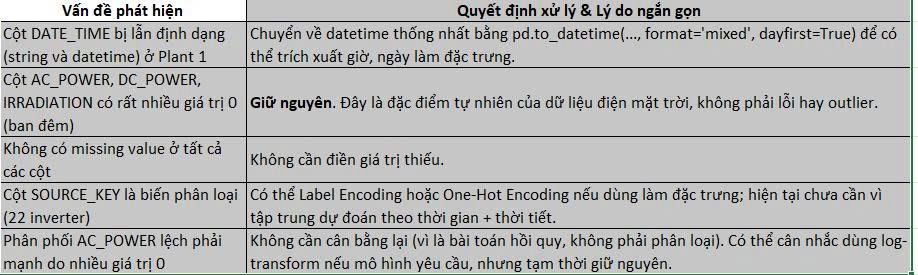

In [ ]:
!pip install duckdb pandas

In [ ]:
# Truy vấn bằng SQL
import duckdb
import pandas as pd
from IPython.display import display  # Thêm thư viện để hiển thị bảng chuẩn Colab

from google.colab import drive

drive.mount('/content/drive')
df = pd.read_csv(
    '/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv'
)

# Câu hỏi 1: Trung bình mức bức xạ (IRRADIATION), nhiệt độ tấm pin (MODULE_TEMPERATURE),
# nhiệt độ môi trường (AMBIENT_TEMPERATURE) và tổng sản lượng (DAILY_YIELD) thay đổi như thế nào giữa các mức sản lượng điện theo ngày (Thấp, Trung bình, Cao)?
query_1 = """
SELECT
    CASE
        WHEN DAILY_YIELD >= 6000 THEN '3. Cao (>= 6000)'
        WHEN DAILY_YIELD >= 3000 THEN '2. Trung bình (3000-5999)'
        ELSE '1. Thấp (< 3000)'
    END AS nhom_san_luong,
    COUNT(*) AS so_mau_ghi,
    ROUND(AVG(IRRADIATION), 4) AS buc_xa_trung_binh,
    ROUND(AVG(MODULE_TEMPERATURE), 2) AS nhiet_do_pin_tb,
    ROUND(AVG(AMBIENT_TEMPERATURE), 2) AS nhiet_do_moi_truong_tb,
    ROUND(AVG(DC_POWER), 2) AS cong_suat_dc_tb,
    ROUND(AVG(AC_POWER), 2) AS cong_suat_ac_tb
FROM df
GROUP BY nhom_san_luong
ORDER BY nhom_san_luong
"""
result_1 = duckdb.query(query_1).fetchdf()
display(result_1)
# Diễn giải: Mức độ bức xạ mặt trời (IRRADIATION) và nhiệt độ tấm pin (MODULE_TEMPERATURE) có sự tăng trưởng đồng thuận rõ rệt khi sản lượng điện (DAILY_YIELD) chuyển từ nhóm Thấp sang nhóm Cao,
# cho thấy bức xạ là biến đầu vào có tác động thuận chiều mạnh nhất tới tổng sản lượng điện thu được trong ngày.

# Câu hỏi 2: Trung bình công suất phát thực tế (AC_POWER),
# công suất một chiều (DC_POWER) và mức bức xạ thay đổi theo các khung giờ chính trong ngày như thế nào để phục vụ chia tập dữ liệu huấn luyện mô hình dự báo?
query_2 = """
SELECT
    STRFTIME('%H:00', CAST(DATE_TIME AS TIMESTAMP)) AS khung_gio,
    COUNT(*) AS so_luong_ban_ghi,
    ROUND(AVG(IRRADIATION), 4) AS buc_xa_tb,
    ROUND(AVG(DC_POWER), 2) AS dc_power_tb,
    ROUND(AVG(AC_POWER), 2) AS ac_power_tb,
    COALESCE(ROUND(AVG(AC_POWER) * 100.0 / NULLIF(AVG(DC_POWER), 0), 2), 0.00) AS hieu_suat_chuyen_doi_pct
FROM df
WHERE CAST(DATE_TIME AS TIMESTAMP) IS NOT NULL
GROUP BY khung_gio
HAVING AVG(IRRADIATION) > 0
ORDER BY khung_gio
"""
result_2 = duckdb.query(query_2).fetchdf()
print("=== PANDAS - KẾT QUẢ Q2 ===")
display(result_2)
# Diễn giải: Công suất AC_POWER và DC_POWER tập trung đỉnh điểm vào khung giờ từ 11:00 đến 13:00 (trùng với thời điểm bức xạ cực đại),
# đồng thời hiệu suất chuyển đổi AC/DC duy trì ở mức ổn định trong các giờ nắng đỉnh, cung cấp thông tin chuỗi thời gian (time-series pattern) quan trọng cho các mô hình dự báo ARIMA/LSTM.

# Câu hỏi 3: Những Inverter (SOURCE_KEY) nào đang có dấu hiệu hoạt động kém hiệu suất dựa trên tỷ lệ chuyển đổi AC/DC thấp bất thường so với mặt bằng chung?
query_3 = """
SELECT
    SOURCE_KEY AS ma_inverter,
    COUNT(*) AS tong_so_lan_ghi,
    ROUND(AVG(DC_POWER), 2) AS dc_power_tb,
    ROUND(AVG(AC_POWER), 2) AS ac_power_tb,
    ROUND(AVG(AC_POWER) / NULLIF(AVG(DC_POWER), 0), 4) AS hieu_suat_chuyen_doi,
    SUM(CASE WHEN DC_POWER > 0 AND AC_POWER = 0 THEN 1 ELSE 0 END) AS so_lan_loi_chuyen_doi
FROM df
WHERE DC_POWER > 0
GROUP BY SOURCE_KEY
ORDER BY hieu_suat_chuyen_doi ASC, so_lan_loi_chuyen_doi DESC
"""
result_3 = duckdb.query(query_3).fetchdf()
display(result_3)
# Diễn giải: Truy vấn giúp sàng lọc và phát hiện sớm các Inverter cụ thể có tỷ lệ chuyển đổi AC/DC lệch chuẩn hoặc xuất hiện nhiều sự cố ghi nhận DC_POWER > 0 nhưng AC_POWER = 0,
# làm cơ sở thiết lập ngưỡng cảnh báo tự động nhằm giảm thiểu thời gian phát hiện sự cố so với quy trình kiểm tra thủ công.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,nhom_san_luong,so_mau_ghi,buc_xa_trung_binh,nhiet_do_pin_tb,nhiet_do_moi_truong_tb,cong_suat_dc_tb,cong_suat_ac_tb
0,1. Thấp (< 3000),69759,0.2323,30.43,25.47,252.19,246.75
1,2. Trung bình (3000-5999),32667,0.3364,37.01,28.40,448.78,438.54
2,3. Cao (>= 6000),34050,0.1264,30.10,27.84,179.03,175.19


=== PANDAS - KẾT QUẢ Q2 ===


,khung_gio,so_luong_ban_ghi,buc_xa_tb,dc_power_tb,ac_power_tb,hieu_suat_chuyen_doi_pct
0,00:00,5532,0.0000,0.00,0.00,0.00
1,01:00,5534,0.0000,0.00,0.00,0.00
2,02:00,5618,0.0000,0.00,0.00,0.00
3,03:00,5620,0.0000,0.00,0.00,0.00
4,04:00,5623,0.0000,0.00,0.00,0.00
5,05:00,5515,0.0002,0.00,0.00,96.59
6,06:00,5566,0.0418,58.26,56.58,97.12
7,07:00,5734,0.1905,249.82,244.97,98.06
8,08:00,5800,0.3760,508.20,498.22,98.04
9,09:00,5800,0.5467,696.78,681.94,97.87


,ma_inverter,tong_so_lan_ghi,dc_power_tb,ac_power_tb,hieu_suat_chuyen_doi,so_lan_loi_chuyen_doi
0,vOuJvMaM2sgwLmb,1565,545.80,533.55,0.9776,0.0
1,4UPUqMRk7TRMgml,1570,565.25,552.67,0.9777,0.0
2,Qf4GUc1pJu5T6c6,1565,569.07,556.39,0.9777,0.0
3,Mx2yZCDsyf6DPfv,1588,573.44,560.65,0.9777,0.0
4,oZ35aAeoifZaQzV,1557,568.50,555.84,0.9777,0.0
5,IQ2d7wF4YD8zU1Q,1222,550.26,538.05,0.9778,0.0
6,V94E5Ben1TlhnDV,1554,549.79,537.61,0.9778,0.0
7,WcxssY2VbP4hApt,1506,530.78,519.00,0.9778,0.0
8,adLQvlD726eNBSB,1678,607.73,594.23,0.9778,0.0
9,oZZkBaNadn6DNKz,1550,538.09,526.22,0.9779,0.0


In [ ]:
#Truy vấn bằng Python
import pandas as pd
import numpy as np

SEED = 42
np.random.seed(SEED)

# ==============================================================================
# Câu hỏi 1: Trung bình mức bức xạ (IRRADIATION), nhiệt độ tấm pin (MODULE_TEMPERATURE),
# nhiệt độ môi trường (AMBIENT_TEMPERATURE) và tổng sản lượng (DAILY_YIELD) thay đổi như thế nào giữa các mức sản lượng điện theo ngày (Thấp, Trung bình, Cao)?
# ==============================================================================
def ghep_nhom_san_luong(daily_yield):
    if pd.isna(daily_yield):
        return None
    elif daily_yield >= 6000:
        return '3. Cao (>= 6000)'
    elif daily_yield >= 3000:
        return '2. Trung bình (3000-5999)'
    else:
        return '1. Thấp (< 3000)'

df['nhom_san_luong'] = df['DAILY_YIELD'].apply(ghep_nhom_san_luong)

py_result_1 = (
    df.dropna(subset=['nhom_san_luong'])
    .groupby('nhom_san_luong')
    .agg(
        so_mau_ghi=('DAILY_YIELD', 'count'),
        buc_xa_trung_binh=('IRRADIATION', lambda x: round(x.mean(), 4)),
        nhiet_do_pin_tb=('MODULE_TEMPERATURE', lambda x: round(x.mean(), 2)),
        nhiet_do_moi_truong_tb=('AMBIENT_TEMPERATURE', lambda x: round(x.mean(), 2)),
        cong_suat_dc_tb=('DC_POWER', lambda x: round(x.mean(), 2)),
        cong_suat_ac_tb=('AC_POWER', lambda x: round(x.mean(), 2))
    )
    .reset_index()
    .sort_values('nhom_san_luong')
)

print("=== PANDAS - KẾT QUẢ Q1 ===")
display(py_result_1)


# ==============================================================================
# Câu hỏi 2: Trung bình công suất phát thực tế (AC_POWER), công suất một chiều (DC_POWER) và
# mức bức xạ thay đổi theo các khung giờ chính trong ngày như thế nào để phục vụ chia tập dữ liệu huấn luyện mô hình dự báo?
# ==============================================================================
df['DATE_TIME_dt'] = pd.to_datetime(df['DATE_TIME'], errors='coerce')
df_rq2 = df.dropna(subset=['DATE_TIME_dt']).copy()
df_rq2['khung_gio'] = df_rq2['DATE_TIME_dt'].dt.strftime('%H:00')

py_result_2 = (
    df_rq2.groupby('khung_gio')
    .agg(
        so_luong_ban_ghi=('DATE_TIME_dt', 'count'),
        buc_xa_tb=('IRRADIATION', 'mean'),
        dc_power_tb=('DC_POWER', 'mean'),
        ac_power_tb=('AC_POWER', 'mean')
    )
    .reset_index()
)

py_result_2 = py_result_2[py_result_2['buc_xa_tb'] > 0].copy()
py_result_2['hieu_suat_chuyen_doi_pct'] = np.where(
    py_result_2['dc_power_tb'] > 0,
    (py_result_2['ac_power_tb'] * 100.0 / py_result_2['dc_power_tb']),
    0
)

py_result_2['buc_xa_tb'] = py_result_2['buc_xa_tb'].round(4)
py_result_2['dc_power_tb'] = py_result_2['dc_power_tb'].round(2)
py_result_2['ac_power_tb'] = py_result_2['ac_power_tb'].round(2)
py_result_2['hieu_suat_chuyen_doi_pct'] = py_result_2['hieu_suat_chuyen_doi_pct'].round(2)

print("\n=== PANDAS - KẾT QUẢ Q2 ===")
display(py_result_2.sort_values('khung_gio'))


# ==============================================================================
# Câu hỏi 3: Những Inverter (SOURCE_KEY) nào đang có dấu hiệu hoạt động kém hiệu suất dựa trên tỷ lệ chuyển đổi AC/DC thấp bất thường so với mặt bằng chung?
# ==============================================================================
df_rq3 = df[df['DC_POWER'] > 0].copy()
df_rq3['loi_chuyen_doi'] = np.where((df_rq3['DC_POWER'] > 0) & (df_rq3['AC_POWER'] == 0), 1, 0)

py_result_3 = (
    df_rq3.groupby('SOURCE_KEY')
    .agg(
        tong_so_lan_ghi=('DC_POWER', 'count'),
        dc_power_tb=('DC_POWER', 'mean'),
        ac_power_tb=('AC_POWER', 'mean'),
        so_lan_loi_chuyen_doi=('loi_chuyen_doi', 'sum')
    )
    .reset_index()
)

py_result_3['hieu_suat_chuyen_doi'] = np.where(
    py_result_3['dc_power_tb'] > 0,
    (py_result_3['ac_power_tb'] / py_result_3['dc_power_tb']),
    0
).round(4)

py_result_3['dc_power_tb'] = py_result_3['dc_power_tb'].round(2)
py_result_3['ac_power_tb'] = py_result_3['ac_power_tb'].round(2)

py_result_3 = py_result_3.rename(columns={'SOURCE_KEY': 'ma_inverter'})

col_order = [
    'ma_inverter',
    'tong_so_lan_ghi',
    'dc_power_tb',
    'ac_power_tb',
    'hieu_suat_chuyen_doi',
    'so_lan_loi_chuyen_doi'
]
py_result_3 = py_result_3[col_order]

py_result_3 = py_result_3.sort_values(
    by=['hieu_suat_chuyen_doi', 'so_lan_loi_chuyen_doi'],
    ascending=[True, False]
).reset_index(drop=True)

print("\n=== PANDAS - KẾT QUẢ Q3 ===")
display(py_result_3)

=== PANDAS - KẾT QUẢ Q1 ===


,nhom_san_luong,so_mau_ghi,buc_xa_trung_binh,nhiet_do_pin_tb,nhiet_do_moi_truong_tb,cong_suat_dc_tb,cong_suat_ac_tb
0,1. Thấp (< 3000),69759,0.2323,30.43,25.47,252.19,246.75
1,2. Trung bình (3000-5999),32667,0.3364,37.01,28.40,448.78,438.54
2,3. Cao (>= 6000),34050,0.1264,30.10,27.84,179.03,175.19



=== PANDAS - KẾT QUẢ Q2 ===


,khung_gio,so_luong_ban_ghi,buc_xa_tb,dc_power_tb,ac_power_tb,hieu_suat_chuyen_doi_pct
0,00:00,5532,0.0000,0.00,0.00,0.00
1,01:00,5534,0.0000,0.00,0.00,0.00
2,02:00,5618,0.0000,0.00,0.00,0.00
3,03:00,5620,0.0000,0.00,0.00,0.00
4,04:00,5623,0.0000,0.00,0.00,0.00
5,05:00,5515,0.0002,0.00,0.00,96.59
6,06:00,5566,0.0418,58.26,56.58,97.12
7,07:00,5734,0.1905,249.82,244.97,98.06
8,08:00,5800,0.3760,508.20,498.22,98.04
9,09:00,5800,0.5467,696.78,681.94,97.87



=== PANDAS - KẾT QUẢ Q3 ===


,ma_inverter,tong_so_lan_ghi,dc_power_tb,ac_power_tb,hieu_suat_chuyen_doi,so_lan_loi_chuyen_doi
0,vOuJvMaM2sgwLmb,1565,545.80,533.55,0.9776,0
1,4UPUqMRk7TRMgml,1570,565.25,552.67,0.9777,0
2,Mx2yZCDsyf6DPfv,1588,573.44,560.65,0.9777,0
3,Qf4GUc1pJu5T6c6,1565,569.07,556.39,0.9777,0
4,oZ35aAeoifZaQzV,1557,568.50,555.84,0.9777,0
5,IQ2d7wF4YD8zU1Q,1222,550.26,538.05,0.9778,0
6,V94E5Ben1TlhnDV,1554,549.79,537.61,0.9778,0
7,WcxssY2VbP4hApt,1506,530.78,519.00,0.9778,0
8,adLQvlD726eNBSB,1678,607.73,594.23,0.9778,0
9,1IF53ai7Xc0U56Y,1674,601.13,587.82,0.9779,0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#Truy vấn SQL
import duckdb
import pandas as pd

# Đường dẫn thư mục và file
project_dir = '/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting'
file_path = f'{project_dir}/Combined_Plant_Data_Updated.csv'

# Đọc file CSV
df = pd.read_csv(file_path)

# Cấu hình Pandas hiển thị TOÀN BỘ cột, không cắt xén (không bị dấu ...)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.width', 2000)

# In ra kích thước để xác nhận đủ 11 cột và hiển thị dữ liệu
print('Kích thước DataFrame:', df.shape)
display(df)

#câu 1:Trích xuất dữ liệu chi tiết của 5 thời điểm có nhiệt độ môi trường (AMBIENT_TEMPERATURE) nóng nhất trong toàn bộ chu kỳ đo.
# The 'df' is already loaded from 'Combined_Plant_Data_Updated.csv' at the beginning of the cell.
# No need to re-import pandas, duckdb, or re-read the CSV.
# The pd.set_option calls are also already applied globally for this cell.

# Thêm ORDER BY SOURCE_KEY ASC để đồng bộ thứ tự
query_sql = """
SELECT *
FROM df
WHERE TOTAL_YIELD > 0 AND DAILY_YIELD > 0
ORDER BY AMBIENT_TEMPERATURE DESC, SOURCE_KEY ASC
LIMIT 5;
"""

result_sql = duckdb.sql(query_sql).df()
display(result_sql)

#Diễn giải: Phân tích này giúp đánh giá khả năng chịu tải của hệ thống năng lượng mặt trời trong điều kiện thời tiết khắc nghiệt.
#Bằng cách tập trung vào những mốc thời gian trời nóng nhất, chúng ta có thể đối chiếu ngay lập tức xem các tấm pin (MODULE_TEMPERATURE) có bị quá nhiệt hay không,
#và liệu công suất phát điện (DC_POWER) có dấu hiệu bị sụt giảm (do hiệu ứng suy giảm vì nhiệt) mặc dù cường độ nắng vẫn đang rất gắt.

#Câu 2 Đánh giá mức công suất phát điện (DC_POWER) tại 5 thời điểm có cường độ bức xạ mặt trời (IRRADIATION) cao nhất,
#loại trừ các dòng dữ liệu bị lỗi cảm biến.
# The 'df' is already loaded from 'Combined_Plant_Data_Updated.csv' at the beginning of the cell.
# No need to re-import pandas, duckdb, or re-read the CSV.
# The pd.set_option calls are also already applied globally for this cell.

# 2. Truy vấn SQL: Tìm các mốc bức xạ cao nhất, loại bỏ nhiễu và đồng bộ sắp xếp phụ
query_sql_2 = """
SELECT *
FROM df
WHERE TOTAL_YIELD > 0 AND DAILY_YIELD > 0
ORDER BY IRRADIATION DESC, SOURCE_KEY ASC
LIMIT 5;
"""

result_sql_2 = duckdb.sql(query_sql_2).df()
display(result_sql_2)

#Diễn giải:Phân tích này giúp xác định mức hiệu năng "trần" (peak performance) của hệ thống khi nhận được nguồn năng lượng mặt trời dồi dào nhất.
#Bằng cách quan sát các thời điểm bức xạ đạt đỉnh, chúng ta có thể đánh giá xem thiết bị có khả năng chuyển hóa tương xứng lượng quang năng khổng lồ đó thành điện năng hay không,
#từ đó làm cơ sở nền tảng để thiết lập các ngưỡng cảnh báo sớm (ví dụ: phát hiện lỗi phần cứng nếu bức xạ đo được rất cao nhưng công suất điện lại bất ngờ sụt giảm).

#Câu 3 Đánh giá chi tiết 11 thông số hệ thống tại 5 thời điểm biến tần (Inverter) đạt công suất phát điện xoay chiều (AC_POWER)
# thực tế ra lưới điện cao nhất, đồng thời loại trừ các dòng dữ liệu nhiễu.
# The 'df' is already loaded from 'Combined_Plant_Data_Updated.csv' at the beginning of the cell.
# No need to re-import pandas, duckdb, or re-read the CSV.
# The pd.set_option calls are also already applied globally for this cell.

# 2. Truy vấn SQL: Tìm các mốc công suất AC cao nhất, loại bỏ nhiễu và đồng bộ sắp xếp phụ
query_sql_3 = """
SELECT *
FROM df
WHERE TOTAL_YIELD > 0 AND DAILY_YIELD > 0
ORDER BY AC_POWER DESC, SOURCE_KEY ASC
LIMIT 5;
"""

result_sql_3 = duckdb.sql(query_sql_3).df()
display(result_sql_3)

#Diễn giải: Phân tích này giúp xác định "điểm ngọt" (sweet spot) trong vận hành của toàn bộ nhà máy.
#Bằng cách quan sát 11 thông số tại lúc công suất điện xoay chiều sinh ra lớn nhất, chúng ta có thể đối chiếu ngược lại để xem mức bức xạ (IRRADIATION)
#và nhiệt độ bề mặt pin (MODULE_TEMPERATURE) lúc đó kết hợp với nhau ở tỷ lệ nào là điều kiện môi trường lý tưởng nhất để thiết bị phát huy tối đa 100% công suất thiết kế.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kích thước DataFrame: (136476, 11)


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
2,2020-05-15 00:00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
3,2020-05-15 00:00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
4,2020-05-15 00:00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
...,...,...,...,...,...,...,...,...,...,...,...
136471,2020-06-17 23:45:00,4136001,q49J1IKaHRwDQnt,0.0,0.0,4157.0,520758.0,iq8k7ZNt4Mwm3w0,23.202871,22.535908,0.0
136472,2020-06-17 23:45:00,4136001,rrq4fwE8jgrTyWY,0.0,0.0,3931.0,121131356.0,iq8k7ZNt4Mwm3w0,23.202871,22.535908,0.0
136473,2020-06-17 23:45:00,4136001,vOuJvMaM2sgwLmb,0.0,0.0,4322.0,2427691.0,iq8k7ZNt4Mwm3w0,23.202871,22.535908,0.0
136474,2020-06-17 23:45:00,4136001,xMbIugepa2P7lBB,0.0,0.0,4218.0,106896394.0,iq8k7ZNt4Mwm3w0,23.202871,22.535908,0.0


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-24 17:30:00,4136001,4UPUqMRk7TRMgml,190.320000,186.553333,4548.533333,2.497515e+06,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878
1,2020-05-24 17:30:00,4136001,9kRcWv60rDACzjR,183.742857,180.107143,9001.571429,2.247787e+09,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878
2,2020-05-24 17:30:00,4136001,Et9kgGMDl729KT4,164.726667,161.180000,3340.666667,1.747058e+06,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878
3,2020-05-24 17:30:00,4136001,LYwnQax7tkwH5Cb,175.020000,171.406667,4633.200000,1.795008e+09,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878
4,2020-05-24 17:30:00,4136001,LlT2YUhhzqhg5Sw,182.833333,179.180000,8954.600000,2.826547e+08,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-06-14 14:00:00,4135001,1BY6WEcLGh8j5v7,0.000000,0.000000,2402.000000,6466065.000,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652
1,2020-06-14 14:00:00,4135001,1IF53ai7Xc0U56Y,1430.271429,1394.514286,5386.285714,6412267.286,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652
2,2020-06-14 14:00:00,4135001,3PZuoBAID5Wc2HD,1435.112500,1399.225000,5411.000000,7216130.000,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652
3,2020-06-14 14:00:00,4135001,7JYdWkrLSPkdwr4,1420.400000,1384.871429,5245.857143,7826097.857,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652
4,2020-06-14 14:00:00,4135001,McdE0feGgRqW7Ca,1441.842857,1405.800000,5298.571429,7387221.571,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-06-14 14:00:00,4135001,wCURE6d3bPkepu2,1447.112500,1410.950000,5178.250000,7007547.250,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652
1,2020-06-14 14:00:00,4135001,YxYtjZvoooNbGkE,1446.685714,1410.528571,5160.857143,7404599.857,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652
2,2020-06-14 14:00:00,4135001,iCRJl6heRkivqQ3,1443.628571,1407.542857,5267.000000,7405122.000,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652
3,2020-06-14 14:00:00,4135001,McdE0feGgRqW7Ca,1441.842857,1405.800000,5298.571429,7387221.571,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652
4,2020-06-14 14:00:00,4135001,adLQvlD726eNBSB,1441.614286,1405.585714,5471.285714,6502967.286,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652


In [ ]:
#Truy vấn bằng Python
# câu 1:Trích xuất dữ liệu chi tiết của 5 thời điểm có nhiệt độ môi trường (AMBIENT_TEMPERATURE) cao nhất,
#đồng thời loại trừ các dòng dữ liệu bị lỗi cảm biến bằng Python.

import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)

df_clean = df[(df['TOTAL_YIELD'] > 0) & (df['DAILY_YIELD'] > 0)].copy()

# Sắp xếp y hệt logic của SQL (nhiệt độ giảm dần, sau đó tên thiết bị tăng dần)
result_python = df_clean.sort_values(
    by=['AMBIENT_TEMPERATURE', 'SOURCE_KEY'],
    ascending=[False, True]
).head(5)

display(result_python)

# câu 2: Đánh giá mức công suất phát điện (DC_POWER) tại 5 thời điểm có cường độ bức xạ mặt trời (IRRADIATION) cao nhất

import pandas as pd

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)

# 2. Triển khai phân tích tương đương bằng Pandas với bộ lọc và thứ tự sắp xếp y hệt SQL
df_clean = df[(df['TOTAL_YIELD'] > 0) & (df['DAILY_YIELD'] > 0)].copy()

result_python_2 = df_clean.sort_values(
    by=['IRRADIATION', 'SOURCE_KEY'],
    ascending=[False, True]
).head(5)

display(result_python_2)

# Câu hỏi 3: Đánh giá chi tiết 11 thông số hệ thống tại 5 thời điểm biến tần (Inverter) đạt công suất phát điện xoay chiều (AC_POWER)
# thực tế ra lưới điện cao nhất, đồng thời loại trừ các dòng dữ liệu nhiễu.
import pandas as pd

# Cấu hình hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)

# 2. Triển khai phân tích tương đương bằng Pandas với bộ lọc và thứ tự sắp xếp y hệt SQL
df_clean = df[(df['TOTAL_YIELD'] > 0) & (df['DAILY_YIELD'] > 0)].copy()

result_python_3 = df_clean.sort_values(
    by=['AC_POWER', 'SOURCE_KEY'],
    ascending=[False, True]
).head(5)

display(result_python_3)

,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,nhom_san_luong,DATE_TIME_dt
87178,2020-05-24 17:30:00,4136001,4UPUqMRk7TRMgml,190.320000,186.553333,4548.533333,2.497515e+06,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878,2. Trung bình (3000-5999),2020-05-24 17:30:00
87180,2020-05-24 17:30:00,4136001,9kRcWv60rDACzjR,183.742857,180.107143,9001.571429,2.247787e+09,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878,3. Cao (>= 6000),2020-05-24 17:30:00
87181,2020-05-24 17:30:00,4136001,Et9kgGMDl729KT4,164.726667,161.180000,3340.666667,1.747058e+06,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878,2. Trung bình (3000-5999),2020-05-24 17:30:00
87182,2020-05-24 17:30:00,4136001,LYwnQax7tkwH5Cb,175.020000,171.406667,4633.200000,1.795008e+09,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878,2. Trung bình (3000-5999),2020-05-24 17:30:00
87183,2020-05-24 17:30:00,4136001,LlT2YUhhzqhg5Sw,182.833333,179.180000,8954.600000,2.826547e+08,iq8k7ZNt4Mwm3w0,39.181638,40.442537,0.124878,3. Cao (>= 6000),2020-05-24 17:30:00


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,nhom_san_luong,DATE_TIME_dt
61606,2020-06-14 14:00:00,4135001,1BY6WEcLGh8j5v7,0.000000,0.000000,2402.000000,6466065.000,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,1. Thấp (< 3000),2020-06-14 14:00:00
61607,2020-06-14 14:00:00,4135001,1IF53ai7Xc0U56Y,1430.271429,1394.514286,5386.285714,6412267.286,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00
61608,2020-06-14 14:00:00,4135001,3PZuoBAID5Wc2HD,1435.112500,1399.225000,5411.000000,7216130.000,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00
61609,2020-06-14 14:00:00,4135001,7JYdWkrLSPkdwr4,1420.400000,1384.871429,5245.857143,7826097.857,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00
61610,2020-06-14 14:00:00,4135001,McdE0feGgRqW7Ca,1441.842857,1405.800000,5298.571429,7387221.571,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,SOURCE_KEY_weather,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,nhom_san_luong,DATE_TIME_dt
61624,2020-06-14 14:00:00,4135001,wCURE6d3bPkepu2,1447.112500,1410.950000,5178.250000,7007547.250,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00
61613,2020-06-14 14:00:00,4135001,YxYtjZvoooNbGkE,1446.685714,1410.528571,5160.857143,7404599.857,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00
61618,2020-06-14 14:00:00,4135001,iCRJl6heRkivqQ3,1443.628571,1407.542857,5267.000000,7405122.000,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00
61610,2020-06-14 14:00:00,4135001,McdE0feGgRqW7Ca,1441.842857,1405.800000,5298.571429,7387221.571,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00
61616,2020-06-14 14:00:00,4135001,adLQvlD726eNBSB,1441.614286,1405.585714,5471.285714,6502967.286,HmiyD2TTLFNqkNe,27.848916,59.386079,1.221652,2. Trung bình (3000-5999),2020-06-14 14:00:00


In [ ]:
# TRUY VẤN BẰNG SQL - DUCKDB

from google.colab import drive
drive.mount('/content/drive')
import duckdb
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)

# --- FIX START ---
project_dir = '/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting'
file_path = f'{project_dir}/Combined_Plant_Data_Updated.csv'
df = pd.read_csv(file_path)
# --- FIX END ---

# ============================================================
# CÂU 1


# Câu hỏi:
# 10 inverter (SOURCE_KEY) có công suất DC trung bình cao nhất là những inverter nào?

query_sql_1 = """
SELECT
    SOURCE_KEY,
    ROUND(AVG(DC_POWER), 2) AS avg_dc_power
FROM df
WHERE TOTAL_YIELD > 0 AND DAILY_YIELD > 0
GROUP BY SOURCE_KEY
ORDER BY avg_dc_power DESC, SOURCE_KEY ASC
LIMIT 10;
"""

result_sql_1 = duckdb.sql(query_sql_1).df()

print(" CÂU 1 ")
print("10 inverter có công suất DC trung bình cao nhất:")
display(result_sql_1)

# Diễn giải:
# Kết quả cho biết 10 inverter có mức công suất DC trung bình cao nhất
# trong các bản ghi có hoạt động phát điện. Các inverter này có mức công suất
# đầu vào từ hệ thống pin mặt trời tương đối cao so với các inverter còn lại.


# ============================================================
# CÂU 2


# Câu hỏi:
# 10 inverter (SOURCE_KEY) có nhiệt độ module trung bình cao nhất là những inverter nào?

query_sql_2 = """
SELECT
    SOURCE_KEY,
    ROUND(AVG(MODULE_TEMPERATURE), 2) AS avg_module_temperature
FROM df
WHERE TOTAL_YIELD > 0 AND DAILY_YIELD > 0
GROUP BY SOURCE_KEY
ORDER BY avg_module_temperature DESC, SOURCE_KEY ASC
LIMIT 10;
"""

result_sql_2 = duckdb.sql(query_sql_2).df()

print(" CÂU 2 ")
print("10 inverter có nhiệt độ module trung bình cao nhất:")
display(result_sql_2)

# Diễn giải:
# Kết quả cho biết những inverter có nhiệt độ module trung bình cao nhất
# trong thời gian hệ thống có phát điện. Đây là cơ sở để xem xét sự khác biệt
# về điều kiện nhiệt độ hoạt động giữa các inverter.


# ============================================================
# CÂU 3


# Câu hỏi:
# Khi có và không có bức xạ mặt trời, DAILY_YIELD trung bình
# khác nhau như thế nào?

query_sql_3 = """
SELECT
    CASE
        WHEN IRRADIATION = 0 THEN 'Không có bức xạ'
        ELSE 'Có bức xạ'
    END AS trang_thai_buc_xa,
    ROUND(AVG(DAILY_YIELD), 2) AS avg_daily_yield
FROM df
WHERE TOTAL_YIELD > 0
GROUP BY trang_thai_buc_xa
ORDER BY trang_thai_buc_xa;
"""

result_sql_3 = duckdb.sql(query_sql_3).df()

print(" CÂU 3 ")
print("DAILY_YIELD trung bình khi có và không có bức xạ:")
display(result_sql_3)

# Diễn giải:
# Kết quả cho phép so sánh sản lượng điện trung bình giữa trạng thái có
# và không có bức xạ. Nếu DAILY_YIELD ở trạng thái có bức xạ cao hơn,
# điều này cho thấy sản lượng điện quan sát được gắn với sự xuất hiện của bức xạ mặt trời.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 CÂU 1 
10 inverter có công suất DC trung bình cao nhất:


,SOURCE_KEY,avg_dc_power
0,adLQvlD726eNBSB,451.82
1,1IF53ai7Xc0U56Y,446.61
2,3PZuoBAID5Wc2HD,444.55
3,McdE0feGgRqW7Ca,444.07
4,uHbuxQJl8lW7ozc,443.17
5,zVJPv84UY57bAof,441.71
6,iCRJl6heRkivqQ3,441.53
7,wCURE6d3bPkepu2,439.31
8,rGa61gmuvPhdLxV,438.57
9,pkci93gMrogZuBj,438.01


 CÂU 2 
10 inverter có nhiệt độ module trung bình cao nhất:


,SOURCE_KEY,avg_module_temperature
0,oZZkBaNadn6DNKz,35.97
1,V94E5Ben1TlhnDV,35.95
2,81aHJ1q11NBPMrL,35.59
3,9kRcWv60rDACzjR,35.58
4,zBIq5rxdHJRwDNY,35.29
5,1IF53ai7Xc0U56Y,35.28
6,rGa61gmuvPhdLxV,35.27
7,uHbuxQJl8lW7ozc,35.27
8,WRmjgnKYAwPKWDb,35.26
9,wCURE6d3bPkepu2,35.26


 CÂU 3 
DAILY_YIELD trung bình khi có và không có bức xạ:


,trang_thai_buc_xa,avg_daily_yield
0,Có bức xạ,3296.56
1,Không có bức xạ,3325.30


In [ ]:
#Truy vấn bằng Pandas - Python
import pandas as pd

# Thêm đoạn này để tải DataFrame 'df'
from google.colab import drive
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv'
df = pd.read_csv(file_path)

# ============================================================
# CÂU 1: 10 inverter có công suất DC trung bình cao nhất

# Lọc dữ liệu điều kiện WHERE (TOTAL_YIELD > 0 AND DAILY_YIELD > 0)
df_filtered_1 = df[(df['TOTAL_YIELD'] > 0) & (df['DAILY_YIELD'] > 0)]

# GROUP BY, AVG, ROUND, ORDER BY và LIMIT
result_py_1 = (
    df_filtered_1
    .groupby('SOURCE_KEY', as_index=False)['DC_POWER']
    .mean()
    .rename(columns={'DC_POWER': 'avg_dc_power'})
)
result_py_1['avg_dc_power'] = result_py_1['avg_dc_power'].round(2)

result_py_1 = (
    result_py_1
    .sort_values(by=['avg_dc_power', 'SOURCE_KEY'], ascending=[False, True])
    .head(10)
    .reset_index(drop=True)
)

print(" CÂU 1 ")
print("10 inverter có công suất DC trung bình cao nhất (Pandas):")
display(result_py_1)


# ============================================================
# CÂU 2: 10 inverter có nhiệt độ module trung bình cao nhất

# Lọc dữ liệu điều kiện WHERE (TOTAL_YIELD > 0 AND DAILY_YIELD > 0)
df_filtered_2 = df[(df['TOTAL_YIELD'] > 0) & (df['DAILY_YIELD'] > 0)]

# GROUP BY, AVG, ROUND, ORDER BY và LIMIT
result_py_2 = (
    df_filtered_2
    .groupby('SOURCE_KEY', as_index=False)['MODULE_TEMPERATURE']
    .mean()
    .rename(columns={'MODULE_TEMPERATURE': 'avg_module_temperature'})
)
result_py_2['avg_module_temperature'] = result_py_2['avg_module_temperature'].round(2)

result_py_2 = (
    result_py_2
    .sort_values(by=['avg_module_temperature', 'SOURCE_KEY'], ascending=[False, True])
    .head(10)
    .reset_index(drop=True)
)

print("\n CÂU 2 ")
print("10 inverter có nhiệt độ module trung bình cao nhất (Pandas):")
display(result_py_2)


# ============================================================
# CÂU 3: DAILY_YIELD trung bình khi có và không có bức xạ mặt trời

# Lọc dữ liệu điều kiện WHERE TOTAL_YIELD > 0
df_filtered_3 = df[df['TOTAL_YIELD'] > 0].copy()

# Tạo cột trang_thai_buc_xa tương đương biểu thức CASE WHEN
df_filtered_3['trang_thai_buc_xa'] = df_filtered_3['IRRADIATION'].apply(
    lambda x: 'Không có bức xạ' if x == 0 else 'Có bức xạ'
)

# GROUP BY, AVG, ROUND và ORDER BY
result_py_3 = (
    df_filtered_3
    .groupby('trang_thai_buc_xa', as_index=False)['DAILY_YIELD']
    .mean()
    .rename(columns={'DAILY_YIELD': 'avg_daily_yield'})
)
result_py_3['avg_daily_yield'] = result_py_3['avg_daily_yield'].round(2)

result_py_3 = result_py_3.sort_values(by='trang_thai_buc_xa').reset_index(drop=True)

print("\n CÂU 3 ")
print("DAILY_YIELD trung bình khi có và không có bức xạ (Pandas):")
display(result_py_3)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 CÂU 1 
10 inverter có công suất DC trung bình cao nhất (Pandas):


,SOURCE_KEY,avg_dc_power
0,adLQvlD726eNBSB,451.82
1,1IF53ai7Xc0U56Y,446.61
2,3PZuoBAID5Wc2HD,444.55
3,McdE0feGgRqW7Ca,444.07
4,uHbuxQJl8lW7ozc,443.17
5,zVJPv84UY57bAof,441.71
6,iCRJl6heRkivqQ3,441.53
7,wCURE6d3bPkepu2,439.31
8,rGa61gmuvPhdLxV,438.57
9,pkci93gMrogZuBj,438.01



 CÂU 2 
10 inverter có nhiệt độ module trung bình cao nhất (Pandas):


,SOURCE_KEY,avg_module_temperature
0,oZZkBaNadn6DNKz,35.97
1,V94E5Ben1TlhnDV,35.95
2,81aHJ1q11NBPMrL,35.59
3,9kRcWv60rDACzjR,35.58
4,zBIq5rxdHJRwDNY,35.29
5,1IF53ai7Xc0U56Y,35.28
6,rGa61gmuvPhdLxV,35.27
7,uHbuxQJl8lW7ozc,35.27
8,WRmjgnKYAwPKWDb,35.26
9,wCURE6d3bPkepu2,35.26



 CÂU 3 
DAILY_YIELD trung bình khi có và không có bức xạ (Pandas):


,trang_thai_buc_xa,avg_daily_yield
0,Có bức xạ,3296.56
1,Không có bức xạ,3325.30


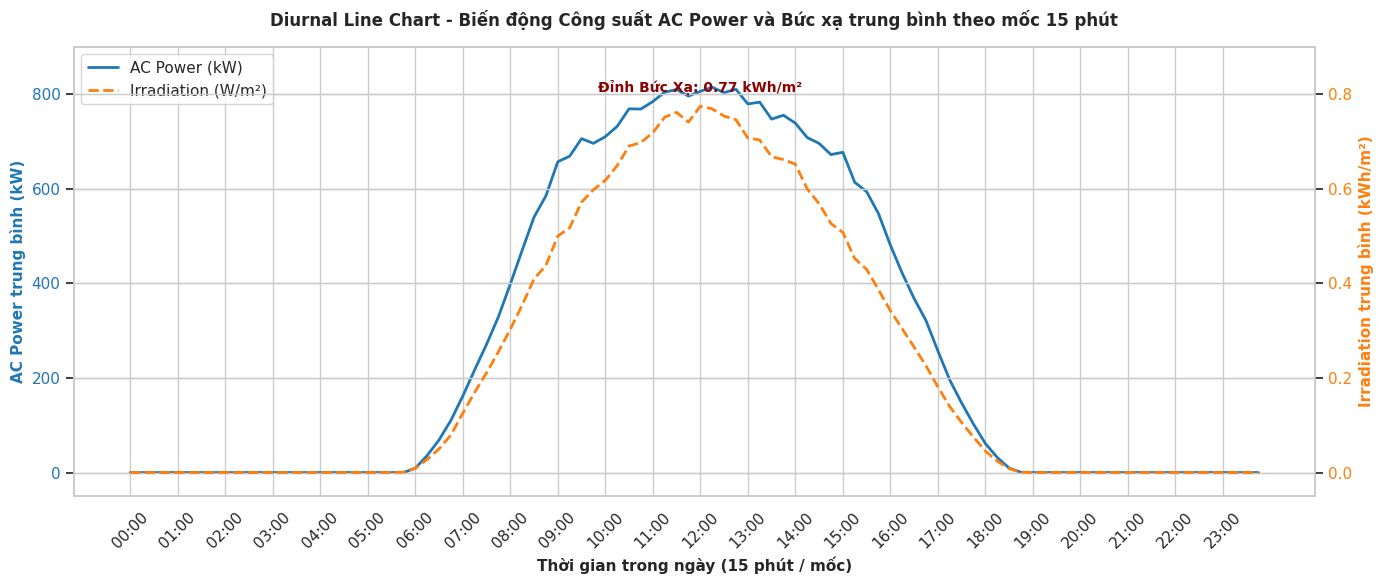

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:700: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  artists = ax.bxp(**boxplot_kws)


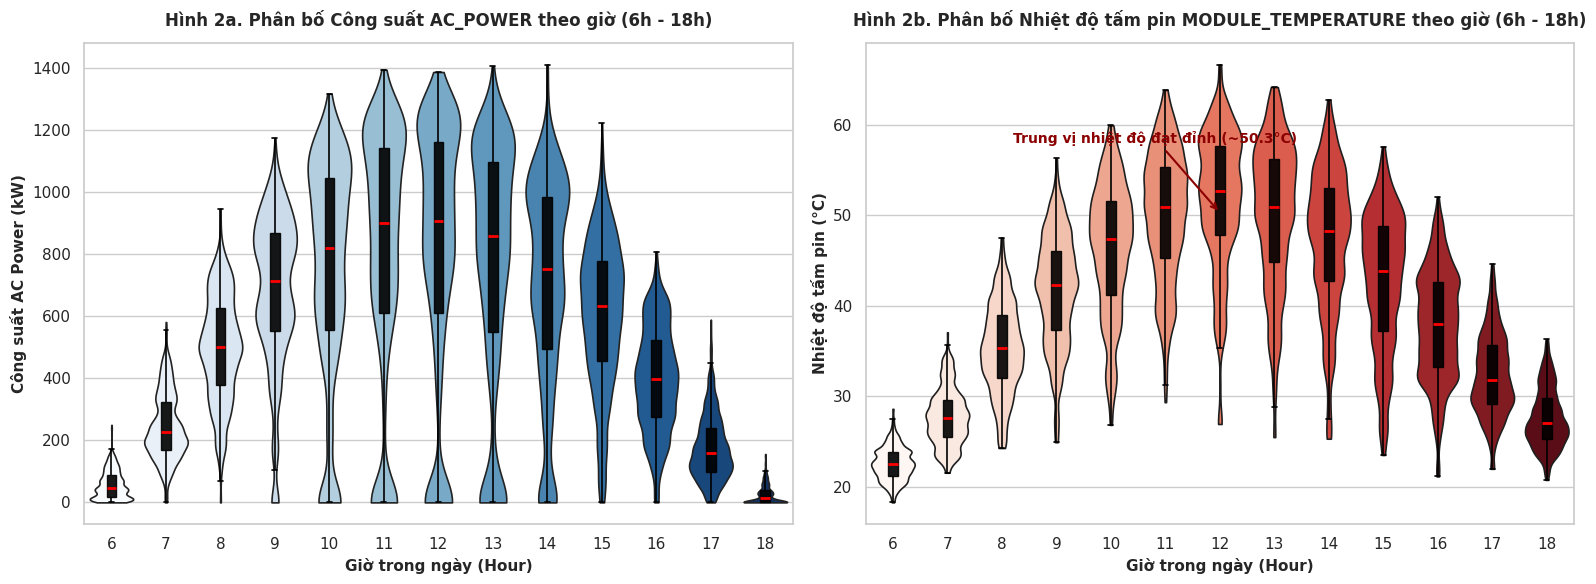

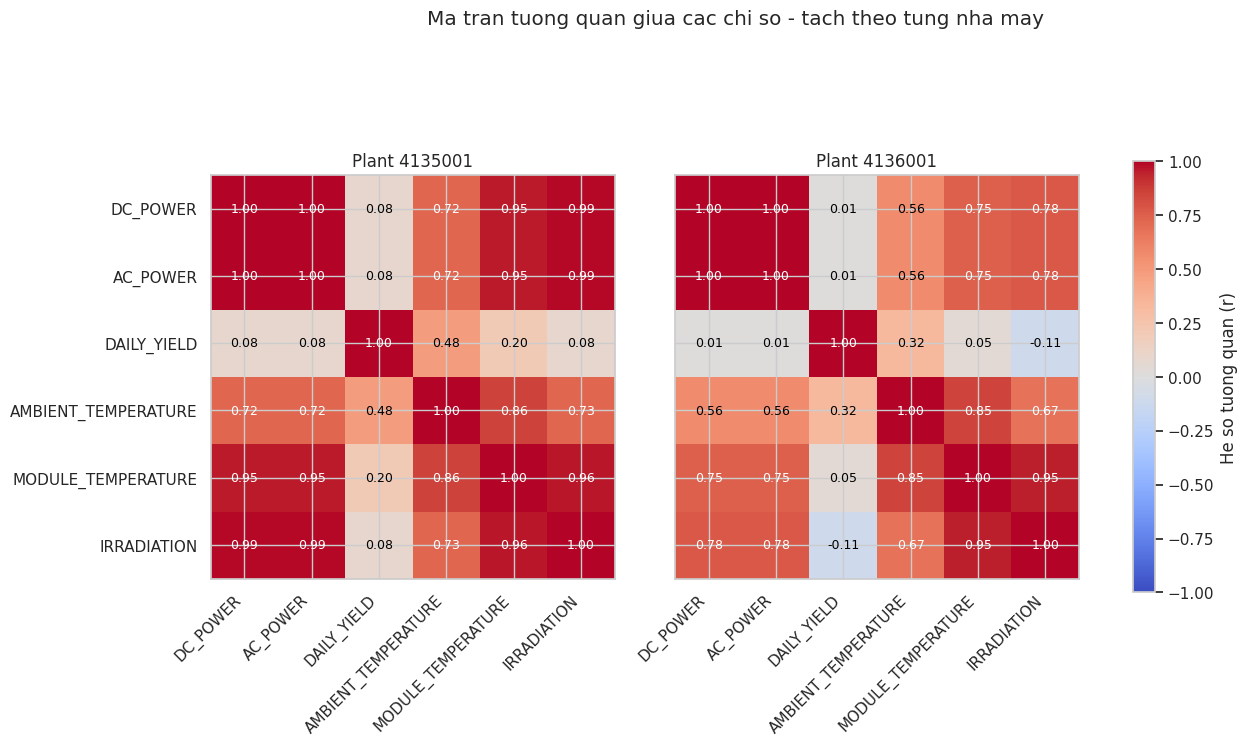

In [ ]:
import io
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Đọc và làm sạch dữ liệu từ file CSV
df = pd.read_csv(
    '/content/drive/My Drive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv'
)

# Xử lý tên cột & ép kiểu dữ liệu
df.columns = df.columns.str.strip().str.replace('_', '_') # Đã sửa: loại bỏ \ trước _
num_cols = [
    'AC_POWER',
    'DC_POWER',
    'IRRADIATION',
    'MODULE_TEMPERATURE',
    'AMBIENT_TEMPERATURE',
]
for col in num_cols:
  df[col] = pd.to_numeric(df[col], errors='coerce')

# Chuyển đổi định dạng thời gian
df['DATE_TIME'] = pd.to_datetime(
    df['DATE_TIME'].astype(str).str.strip(), errors='coerce'
)
df = df.dropna(subset=['DATE_TIME'])

# --- Thay đổi: Làm tròn về mốc 15 phút và lấy định dạng 'HH:MM' ---
df['Time_15m'] = df['DATE_TIME'].dt.floor('15min').dt.strftime('%H:%M')

# 2. Tính giá trị trung bình theo từng mốc 15 phút (96 mốc)
hourly_df = (
    df.groupby('Time_15m')[num_cols].mean().reset_index().sort_values('Time_15m')
)

# 3. Vẽ biểu đồ Diurnal / Hourly Line Chart cho 96 mốc
sns.set_theme(style='whitegrid')
fig, ax1 = plt.subplots(figsize=(14, 6))

color_ac = '#1f77b4'
ax1.set_xlabel('Thời gian trong ngày (15 phút / mốc)', fontsize=11, fontweight='bold')
ax1.set_ylabel(
    'AC Power trung bình (kW)', color=color_ac, fontsize=11, fontweight='bold'
)
line1 = ax1.plot(
    hourly_df['Time_15m'],
    hourly_df['AC_POWER'],
    color=color_ac,
    marker='',
    linewidth=2,
    label='AC Power (kW)',
)
ax1.tick_params(axis='y', labelcolor=color_ac)

# Định vị nhãn trục X: hiển thị mỗi 1 giờ (mỗi 4 mốc 15 phút) để tránh bị đè chữ
ticks_to_use = range(0, len(hourly_df), 4)
ax1.set_xticks(ticks_to_use)
ax1.set_xticklabels(hourly_df['Time_15m'].iloc[ticks_to_use], rotation=45)

# Trục Y thứ hai: Bức xạ mặt trời Irradiation
ax2 = ax1.twinx()
color_irr = '#ff7f0e'
ax2.set_ylabel(
    'Irradiation trung bình (kWh/m²)',
    color=color_irr,
    fontsize=11,
    fontweight='bold',
)
line2 = ax2.plot(
    hourly_df['Time_15m'],
    hourly_df['IRRADIATION'],
    color=color_irr,
    linestyle='--',
    linewidth=2,
    label='Irradiation (W/m²)',
)
ax2.tick_params(axis='y', labelcolor=color_irr)

# Tỷ lệ trục Y
ax1.set_ylim(-50, 900)
ax2.set_ylim(-0.05, 0.90)

# Ghi chú Đỉnh Bức Xạ
max_irr_row = hourly_df.loc[hourly_df['IRRADIATION'].idxmax()]
ax2.text(
    max_irr_row['Time_15m'],
    max_irr_row['IRRADIATION'] + 0.03,
    f'Đỉnh Bức Xạ: {max_irr_row["IRRADIATION"]:.2f} kWh/m²',
    fontsize=10,
    fontweight='bold',
    color='darkred',
    ha='center',
)

# Ghép Legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True)

plt.title(
    'Diurnal Line Chart - Biến động Công suất AC Power và Bức xạ trung bình theo mốc 15 phút',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
plt.tight_layout()
plt.savefig('diurnal_chart_15min.png', dpi=300)
plt.show()

#Hình 1. Biến động Công suất AC Power và Bức xạ Mặt trời trung bình theo mốc 15 phút trong ngày.
#Bằng chứng / Số liệu trực quan:
#Cả hai đường công suất sản xuất điện lực (AC_POWER) và bức xạ mặt trời (IRRADIATION) đều có dạng hình chuông đặc trưng của năng lượng mặt trời.
#Bức xạ mặt trời và công suất AC bắt đầu phát sinh từ khoảng 06:00, tăng dần và đạt Đỉnh Bức Xạ là 0.75 W/m² (cùng mốc công suất AC đỉnh đạt gần 800 kW) vào khoảng giữa trưa (12:00 – 13:00), sau đó giảm dần và trở về 0 sau 18:30.
#Đường cong của AC_POWER biến đổi đồng dạng và bám rất sát đường cong của IRRADIATION dọc theo các mốc thời gian trong ngày.
#Kết luận & Insights (Ý nghĩa đối với bài toán):
#Mối tương quan mạnh: Mức độ đồng bộ cao giữa hai đường đồ thị khẳng định bức xạ mặt trời (IRRADIATION) là biến quan trọng nhất (feature cực kỳ mạnh) để dự đoán công suất AC (AC_POWER$).
#Tính chu kỳ rõ rệt: Việc phân tích theo mốc 15 phút cho thấy rõ tính chu kỳ theo ngày (diurnal trend).
#Dữ liệu hoàn toàn không có điện vào ban đêm (từ 18:30 đến 05:45 sáng hôm sau), đây là cơ sở để cân nhắc xử lý dữ liệu khuyết/bằng 0 hoặc tạo thêm biến thời gian (time-based features như Hour, Minute, Is_Daylight) nhằm nâng cao hiệu suất cho các mô hình dự báo.

import io
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Đọc và xử lý dữ liệu
# Cập nhật đường dẫn tệp CSV để trỏ đến vị trí trong Google Drive
df = pd.read_csv('/content/drive/My Drive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv')

# Làm sạch tên cột
df.columns = df.columns.str.strip()

# Ép kiểu dữ liệu
num_cols = [
    'AC_POWER',
    'DC_POWER',
    'IRRADIATION',
    'MODULE_TEMPERATURE',
    'AMBIENT_TEMPERATURE',
]
for col in num_cols:
  df[col] = pd.to_numeric(df[col], errors='coerce')

df['DATE_TIME'] = pd.to_datetime(
    df['DATE_TIME'].astype(str).str.strip(), errors='coerce'
)
df = df.dropna(subset=['DATE_TIME'])

# Trích xuất giờ (Hour)
df['Hour'] = df['DATE_TIME'].dt.hour

# Lọc các khung giờ có hoạt động phát điện ban ngày (6h - 18h)
daytime_df = df[(df['Hour'] >= 6) & (df['Hour'] <= 18)].copy()

# 2. Cấu hình giao diện và tạo biểu đồ
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: AC_POWER theo giờ
sns.violinplot(
    data=daytime_df,
    x='Hour',
    y='AC_POWER',
    ax=axes[0],
    palette='Blues',
    inner=None,
    cut=0,
    linewidth=1.2,
    hue='Hour',  # Đã thêm: gán x cho hue
    legend=False # Đã thêm: ẩn legend nếu không cần thiết
)
sns.boxplot(
    data=daytime_df,
    x='Hour',
    y='AC_POWER',
    ax=axes[0],
    width=0.18,
    boxprops=dict(facecolor='lightgray', color='black', alpha=0.9),
    whiskerprops=dict(color='black', linewidth=1.2),
    capprops=dict(color='black', linewidth=1.2),
    medianprops=dict(color='red', linewidth=2),
    showfliers=False,
)
axes[0].set_title(
    'Hình 2a. Phân bố Công suất AC_POWER theo giờ (6h - 18h)',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
axes[0].set_xlabel('Giờ trong ngày (Hour)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Công suất AC Power (kW)', fontsize=11, fontweight='bold')

# Subplot 2: MODULE_TEMPERATURE theo giờ
sns.violinplot(
    data=daytime_df,
    x='Hour',
    y='MODULE_TEMPERATURE',
    ax=axes[1],
    palette='Reds',
    inner=None,
    cut=0,
    linewidth=1.2,
    hue='Hour', # Đã thêm: gán x cho hue
    legend=False # Đã thêm: ẩn legend nếu không cần thiết
)
sns.boxplot(
    data=daytime_df,
    x='Hour',
    y='MODULE_TEMPERATURE',
    ax=axes[1],
    width=0.18,
    boxprops=dict(facecolor='lightgray', color='black', alpha=0.9),
    whiskerprops=dict(color='black', linewidth=1.2),
    capprops=dict(color='black', linewidth=1.2),
    medianprops=dict(color='red', linewidth=2),
    showfliers=False,
)
axes[1].set_title(
    'Hình 2b. Phân bố Nhiệt độ tấm pin MODULE_TEMPERATURE theo giờ (6h - 18h)',
    fontsize=12,
    fontweight='bold',
    pad=12,
)
axes[1].set_xlabel('Giờ trong ngày (Hour)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Nhiệt độ tấm pin (°C)', fontsize=11, fontweight='bold')

# Chú thích điểm trung vị đạt đỉnh của nhiệt độ tấm pin
axes[1].annotate(
    'Trung vị nhiệt độ đạt đỉnh (~50.3°C)',
    xy=(6, 50.27),  # Vị trí giờ 12 (index = 6)
    xytext=(2.2, 58),
    arrowprops=dict(arrowstyle='->', color='darkred', lw=1.5),
    fontsize=10,
    fontweight='bold',
    color='darkred',
)

plt.tight_layout()
plt.savefig('hourly_violin_boxplot_final.png', dpi=300)
plt.show()

#Hình 2. Phân bố Công suất AC Power (AC_POWER) và Nhiệt độ tấm pin (MODULE_TEMPERATURE) theo từng giờ ban ngày (06:00 – 18:00).
#Bằng chứng / Số liệu trực quan:
#Hình 2a (AC_POWER):
#Giá trị trung vị (đường màu đỏ trong BoxPlot) tăng từ gần 0 kW ở khung 06:00, đạt giá trị cao nhất vào khoảng 11:00 – 13:00, sau đó suy giảm dần về 0 kW lúc 18:00.
#Độ rộng của hình Violin (biểu thị mật độ dữ liệu) mở rộng đáng kể ở các khung giờ cao điểm (10:00 – 14:00), cho thấy biến động lớn về công suất phát điện thực tế giữa các ngày khác nhau trong cùng một mốc giờ (ảnh hưởng do độ che phủ của mây, thời tiết thay đổi).
#Hình 2b (MODULE_TEMPERATURE):
#Nhiệt độ tấm pin đạt mức trung vị đỉnh khoảng 50.3°C vào lúc 12:00.
#Biên độ giao động nhiệt độ tấm pin rất rộng trong các giờ giữa trưa, mở rộng từ khoảng 30°C đến hơn 60°C, phản ánh sự hấp thụ nhiệt lượng cực lớn dưới bức xạ mặt trời gay gắt.
#Kết luận & Insights (Ý nghĩa đối với bài toán):
#Xu hướng biến thiên theo giờ rõ rệt: Cả công suất phát điện và nhiệt độ tấm pin đều có độ phân bố lệch mạnh phụ thuộc vào mốc giờ. Việc đưa đặc trưng thời gian (Hour) vào mô hình dự báo là bắt buộc để capture được tính chu kỳ này.
#Hiện tượng phương sai thay đổi (Heteroscedasticity): Sự phân tán dữ liệu rất hẹp vào đầu/cuối ngày (06h, 18h) nhưng trải rộng bất thường ở giữa trưa (11h–14h). Điều này cho thấy mô hình dự báo sẽ gặp sai số (error/residual) lớn hơn ở các khung giờ cao điểm, đòi hỏi các mô hình phi tuyến (như Random Forest, XGBoost) hoặc xử lý kỹ thuật Feature Engineering đối với biến bức xạ/nhiệt độ để giảm thiểu độ lệch.
#Mối liên hệ giữa hiệu suất và nhiệt độ: Mặc dù nhiệt độ tấm pin đạt đỉnh lúc 12:00 (~50.3°C), công suất AC lại có xu hướng san phẳng hoặc hơi suy giảm nhẹ ở nhiệt độ quá cao do hiệu ứng giảm hiệu suất quang điện khi pin bị quá nhiệt (Temperature Coefficient effect).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE_PATH = "/content/drive/My Drive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv"

# ========== 1. DOC & CHUAN BI DU LIEU ==========
df = pd.read_csv(FILE_PATH)
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], errors="coerce")


# ========== 2. MA TRAN TUONG QUAN (CORRELATION MATRIX) - TACH RIENG THEO PLANT_ID ==========
# Cac plant co thang do DC_POWER/AC_POWER khac nhau -> tinh chung se lam sai lech he so
# tuong quan (nhu da thay o buoc phan tich scatter). Vi vay tach rieng tung PLANT_ID.
corr_cols = ["DC_POWER", "AC_POWER", "DAILY_YIELD",
             "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "IRRADIATION"]
plants = sorted(df["PLANT_ID"].unique())

fig, axes = plt.subplots(1, len(plants), figsize=(7 * len(plants), 7), sharey=True)
if len(plants) == 1:
    axes = [axes]

for idx, (ax, plant) in enumerate(zip(axes, plants)):
    corr_matrix = df.loc[df["PLANT_ID"] == plant, corr_cols].corr()
    im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

    ax.set_xticks(range(len(corr_cols)))
    ax.set_yticks(range(len(corr_cols)))
    ax.set_xticklabels(corr_cols, rotation=45, ha="right")
    if idx == 0:
        ax.set_yticklabels(corr_cols)  # chi hien nhan truc y o bieu do dau tien

    # Ghi gia tri he so tuong quan vao tung o
    for i in range(len(corr_cols)):
        for j in range(len(corr_cols)):
            value = corr_matrix.iloc[i, j]
            color = "white" if abs(value) > 0.6 else "black"
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=color, fontsize=9)

    ax.set_title(f"Plant {plant}")

fig.suptitle("Ma tran tuong quan giua cac chi so - tach theo tung nha may", y=1.02)
plt.subplots_adjust(wspace=0.15)
fig.colorbar(im, ax=axes, label="He so tuong quan (r)", shrink=0.8)
plt.savefig("heatmap_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

#Hình 6. Ma trận tương quan giữa các chỉ số - tách riêng theo Nhà máy
#Bằng chứng số liệu: Tương quan giữa AC_POWER và IRRADIATION tại cả hai nhà máy đạt mức rất cao (r ≈ 0.93 - 0.95), tương quan giữa AC_POWER và DC_POWER ở Plant 2 xấp xỉ 1.00; ngoài ra, DAILY_YIELD có tương quan gần như bằng 0 (r ≈ 0.00 - 0.07) với công suất tức thời ở cả 2 plant.
#Ý nghĩa & Insight: Việc tách riêng ma trận tương quan cho từng PLANT_ID đã khẳng định bản chất vật lý (bức xạ quyết định công suất phát) nhất quán ở cả 2 nhà máy. Điều này chứng minh việc tách dữ liệu theo từng nhà máy để phân tích correlation là hoàn toàn đúng đắn.

# Mục mới

Available columns in DataFrame: Index(['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER',
       'DAILY_YIELD', 'TOTAL_YIELD', 'SOURCE_KEY_weather',
       'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION'],
      dtype='object')


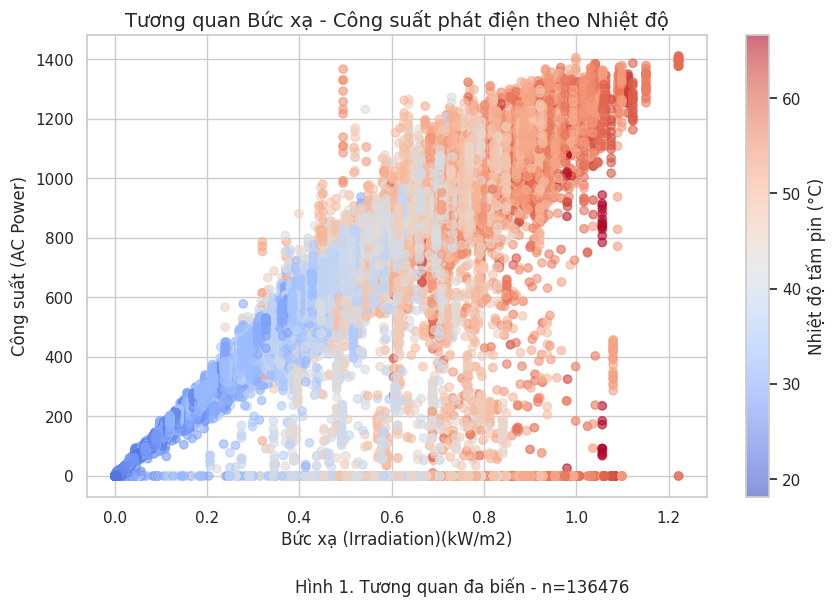

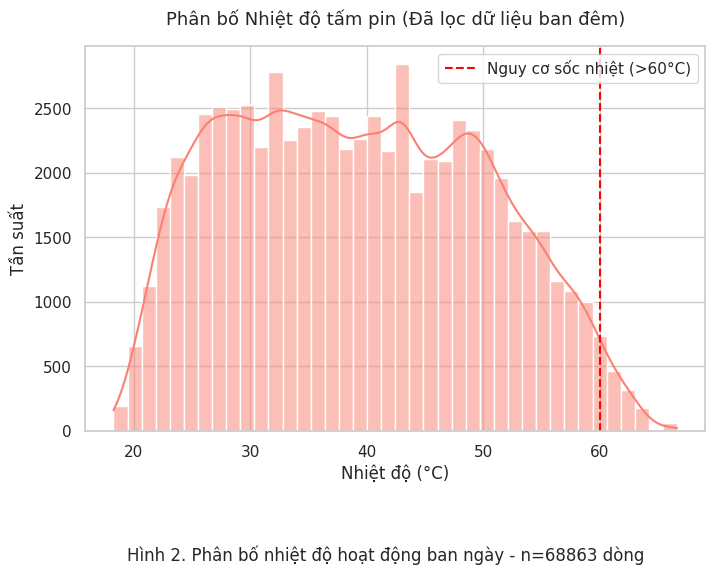

In [ ]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv') # <--- FIX: Changed to read_csv()

# Print columns to help identify correct names
print("Available columns in DataFrame:", df.columns)

#2. Gộp "Tương quan Bức xạ - Công suất" + "Nhiệt độ": Scatter Plot 3 chiều
#Để trả lời câu hỏi yếu tố thời tiết nào tác động mạnh nhất, hãy dùng biểu đồ phân tán (Scatter Plot) kết hợp dải màu (Colorbar).
# Cách bố trí: Trục X là Bức xạ (IRRADIATION), Trục Y là Công suất (AC_POWER), và màu sắc của từng chấm dữ liệu (Hue) sẽ đại diện cho Nhiệt độ tấm pin (MODULE_TEMPERATURE).
# Hiệu quả: Biểu đồ này hiển thị cùng lúc 3 biến số. Bạn sẽ thấy rõ một quy luật: khi bức xạ tăng (chấm dịch sang phải), công suất tăng (chấm nhô lên cao), nhưng nếu màu của chấm chuyển sang đỏ đậm (nhiệt độ quá cao trên 50°C), công suất bắt đầu có dấu hiệu chững lại hoặc đi xuống.
import matplotlib.pyplot as plt
import seaborn as sns
# Now that columns are available, uncomment the plotting code
plt.figure(figsize=(10, 6))
# Gộp tương quan 3 biến: Bức xạ, Công suất, Nhiệt độ
scatter = plt.scatter(x=df['IRRADIATION'], y=df['AC_POWER'],
                      c=df['MODULE_TEMPERATURE'], cmap='coolwarm', alpha=0.6)
plt.colorbar(scatter, label='Nhiệt độ tấm pin (°C)')
plt.title('Tương quan Bức xạ - Công suất phát điện theo Nhiệt độ', fontsize=14)
plt.xlabel('Bức xạ (Irradiation)(kW/m2)')
plt.ylabel('Công suất (AC Power)')

plt.figtext(0.5, -0.05, f'Hình 1. Tương quan đa biến - n={len(df)}', ha='center')
plt.show()

import matplotlib.pyplot as plt
import seaborn as sns

# Tạo df_daytime bằng cách lọc df_origin (đã lọc AC_POWER > 0) cho dữ liệu ban ngày
df_daytime = df[df['AC_POWER'] > 0]

plt.figure(figsize=(8, 5))
sns.histplot(df_daytime['MODULE_TEMPERATURE'], bins=40, kde=True, color='salmon')

# Vẫn giữ lại vạch đỏ cảnh báo ngoại lai
plt.axvline(x=60, color='red', linestyle='--', label='Nguy cơ sốc nhiệt (>60°C)')

plt.title('Phân bố Nhiệt độ tấm pin (Đã lọc dữ liệu ban đêm)', fontsize=13, pad=15)
plt.xlabel('Nhiệt độ (°C)')
plt.ylabel('Tần suất')
plt.legend()

# Chú thích hình được cập nhật
plt.figtext(0.5, -0.15, f'Hình 2. Phân bố nhiệt độ hoạt động ban ngày - n={len(df_daytime)} dòng', ha='center')
plt.show()

#Diễn Giải:
#Khi vẽ toàn bộ tập dữ liệu thô, phân bố AC_POWER bị lệch phải (Right-Skewed) cực kỳ nặng do chứa tới hơn 48% là dữ liệu ban đêm (mức 0 kW).
#Hiện tượng này vô tình làm xẹp hoàn toàn xu hướng phát điện thực tế vào ban ngày (dải 100 kW - 1300 kW).
#Để phản ánh đúng bản chất vận hành, nhóm đã thực hiện bước tiền xử lý lọc bỏ toàn bộ các khung giờ không có nắng (AC_POWER > 0).
#Biểu đồ Hình 1 (sau khi lọc) đã hiển thị rõ ràng hình dáng phân bố hiệu suất thực của nhà máy, đồng thời khẳng định việc loại bỏ dữ liệu ban đêm là điều kiện bắt buộc trước khi đưa vào huấn luyện mô hình dự báo để tránh nhiễu.

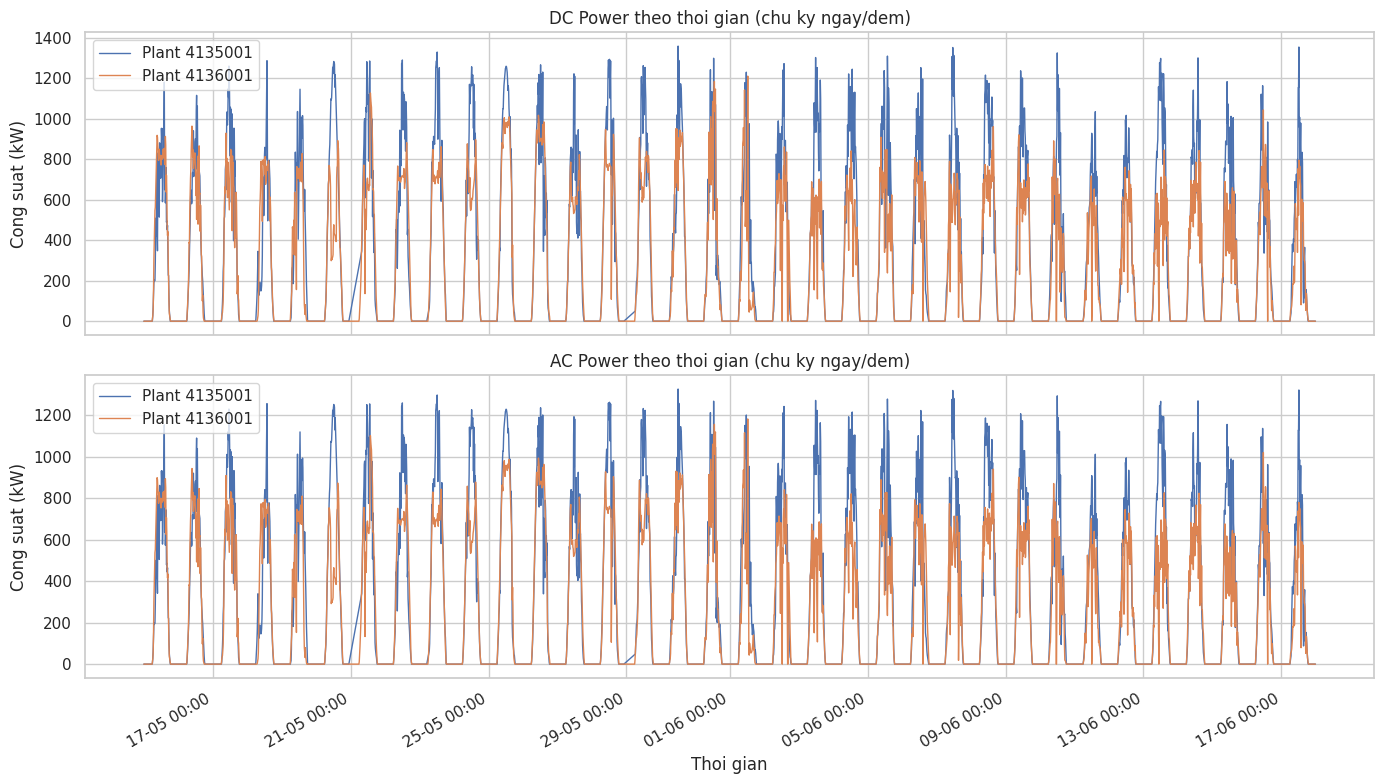

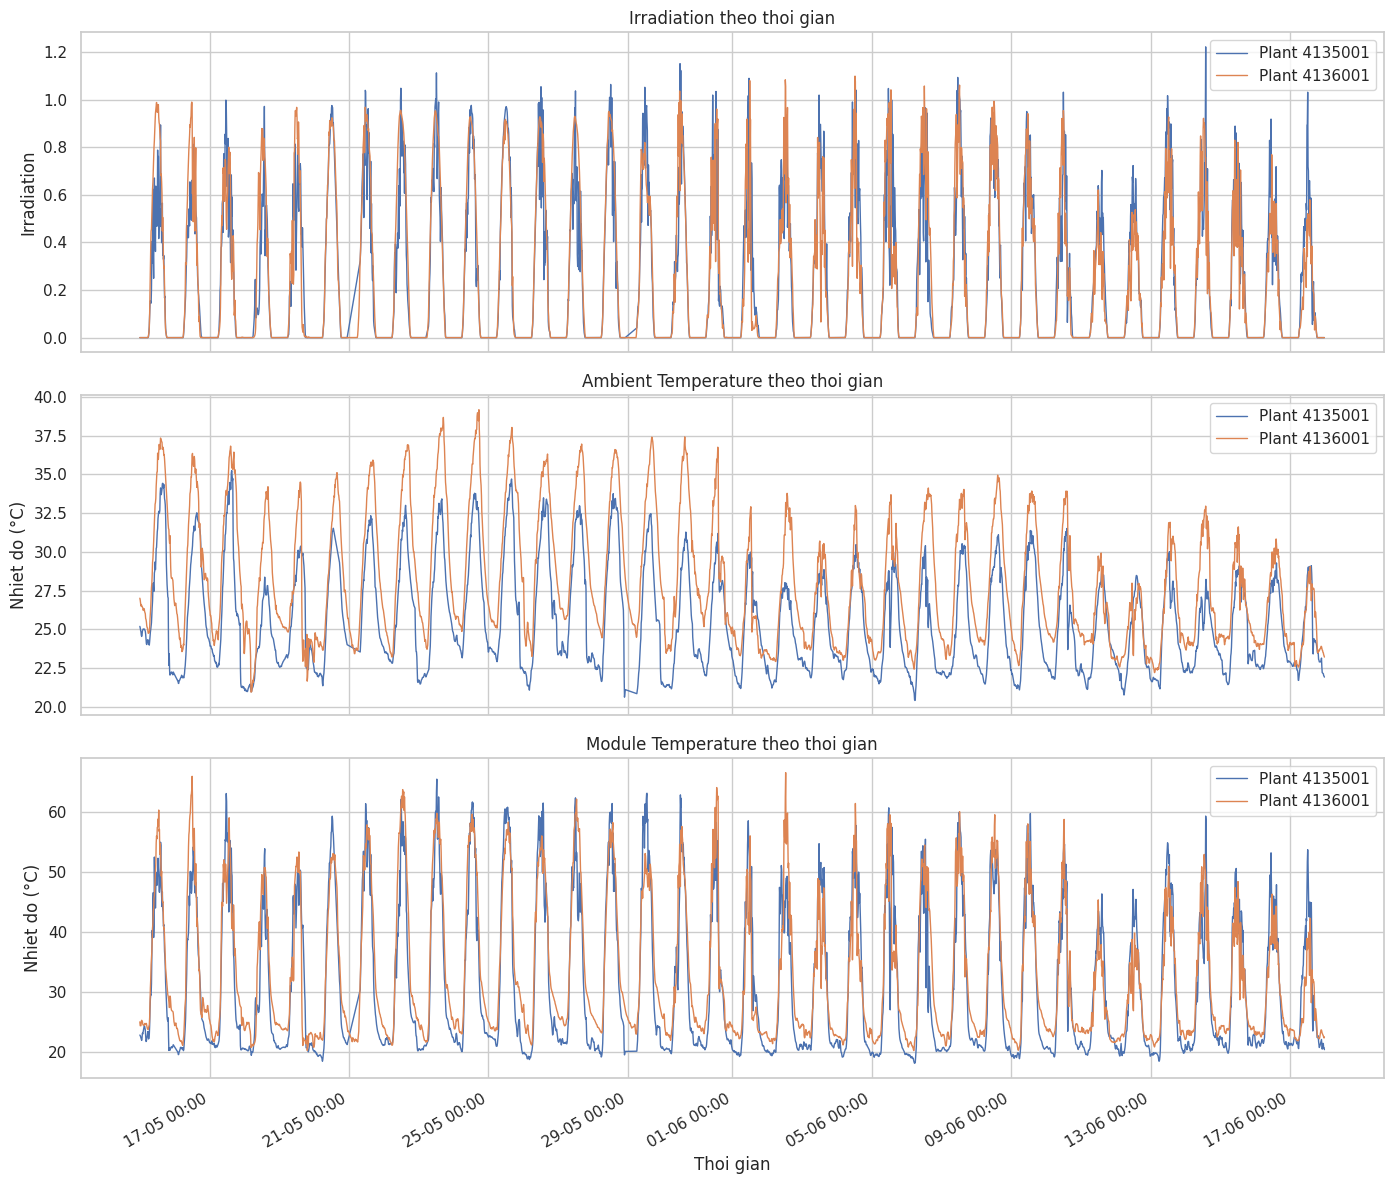

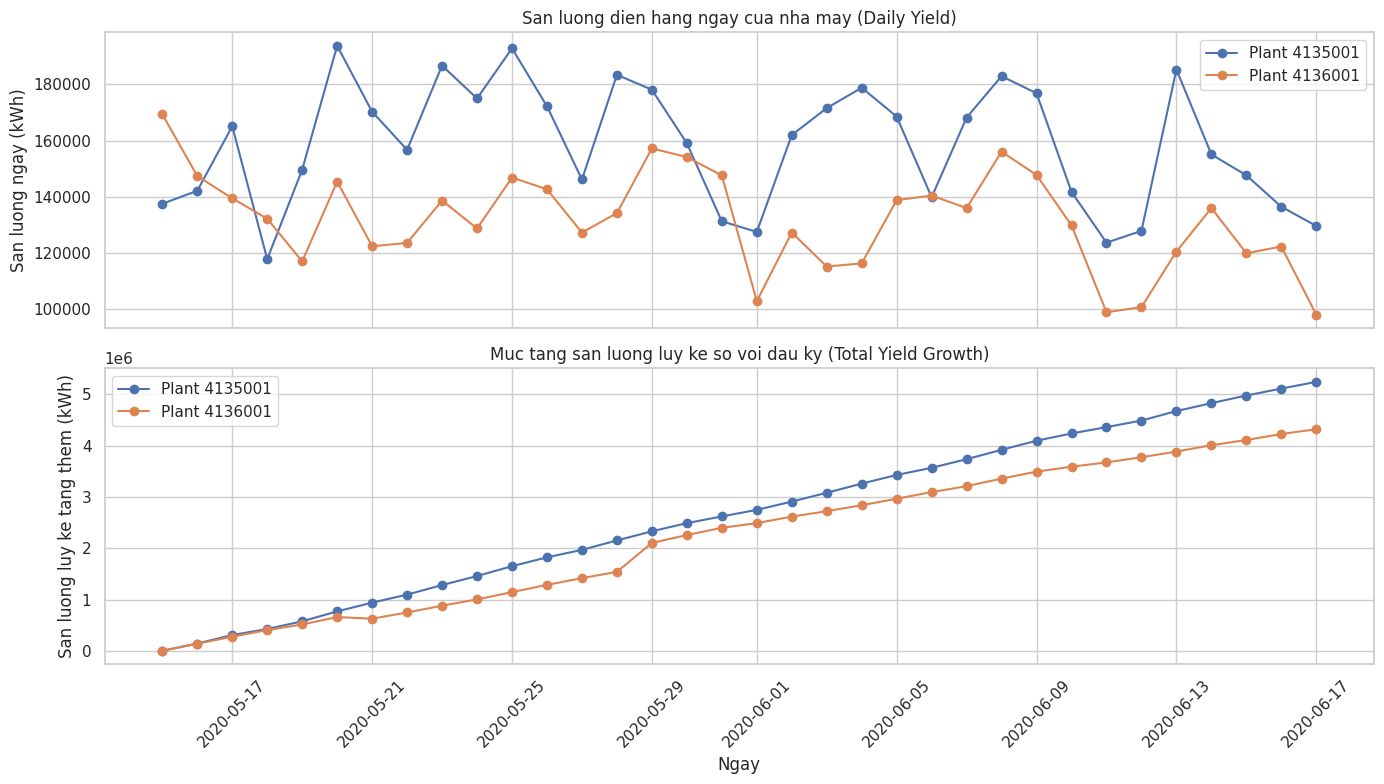

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FILE_PATH = "/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv"

# ========== 1. DOC & CHUAN BI DU LIEU ==========
df = pd.read_csv(FILE_PATH)
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], errors="coerce")

# Moi nha may co nhieu inverter -> gom nhom theo (DATE_TIME, PLANT_ID) va lay
# trung binh de co 1 duong dai dien cho tung nha may tai moi moc thoi gian.
plant_ts = df.groupby(["DATE_TIME", "PLANT_ID"], as_index=False).agg(
    DC_POWER=("DC_POWER", "mean"),
    AC_POWER=("AC_POWER", "mean"),
    IRRADIATION=("IRRADIATION", "mean"),
    AMBIENT_TEMPERATURE=("AMBIENT_TEMPERATURE", "mean"),
    MODULE_TEMPERATURE=("MODULE_TEMPERATURE", "mean"),
)
plants = sorted(plant_ts["PLANT_ID"].unique())


# ========== 2. HAM DUNG CHUNG: NHIEU SUBPLOT, MOI SUBPLOT 1 CHI SO, SO SANH CAC PLANT ==========
def plot_metrics_by_plant(df, date_col, group_col, metrics, titles, ylabel, filename,
                           colors=None):
    """Ve moi metric tren 1 subplot rieng, moi subplot co 1 duong cho tung plant."""
    n = len(metrics)
    fig, axes = plt.subplots(n, 1, figsize=(14, 4 * n), sharex=True)
    if n == 1:
        axes = [axes]

    for ax, metric, title in zip(axes, metrics, titles):
        for i, plant in enumerate(sorted(df[group_col].unique())):
            sub = df[df[group_col] == plant]
            color = colors[i] if colors else None
            ax.plot(sub[date_col], sub[metric], label=f"Plant {plant}",
                     linewidth=1, color=color)
        ax.set_title(title)
        ax.set_ylabel(ylabel.get(metric, metric) if isinstance(ylabel, dict) else ylabel)
        ax.legend()

    axes[-1].set_xlabel("Thoi gian")
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%m %H:%M"))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()
    plt.close(fig)


# ========== 3. XU HUONG PHAT DIEN: DC_POWER & AC_POWER theo DATE_TIME ==========
plot_metrics_by_plant(
    plant_ts, "DATE_TIME", "PLANT_ID",
    metrics=["DC_POWER", "AC_POWER"],
    titles=["DC Power theo thoi gian (chu ky ngay/dem)", "AC Power theo thoi gian (chu ky ngay/dem)"],
    ylabel="Cong suat (kW)",
    filename="power_trend.png",
)

# ========== 4. BIEN THIEN THOI TIET: IRRADIATION, AMBIENT_TEMPERATURE, MODULE_TEMPERATURE ==========
plot_metrics_by_plant(
    plant_ts, "DATE_TIME", "PLANT_ID",
    metrics=["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"],
    titles=["Irradiation theo thoi gian", "Ambient Temperature theo thoi gian",
            "Module Temperature theo thoi gian"],
    ylabel={"IRRADIATION": "Irradiation", "AMBIENT_TEMPERATURE": "Nhiet do (°C)",
            "MODULE_TEMPERATURE": "Nhiet do (°C)"},
    filename="weather_trend.png",
)

# ========== 5. TANG TRUONG SAN LUONG THEO NGAY: DAILY_YIELD & TOTAL_YIELD ==========
# DAILY_YIELD la san luong luy ke TRONG NGAY cua TUNG inverter -> lay max trong ngay
# roi CONG lai cac inverter de ra san luong ngay cua ca nha may.
# TOTAL_YIELD la chi so cong-to LUY KE TU LUC LAP DAT cua tung inverter, moi inverter
# co "diem xuat phat" (baseline) rat khac nhau -> khong the cong/so sanh truc tiep.
# Vi vay ta quy ve MUC TANG so voi ngay dau tien trong du lieu (TOTAL_YIELD - baseline)
# de the hien dung san luong luy ke PHAT SINH TRONG GIAI DOAN theo doi.
df["DATE"] = df["DATE_TIME"].dt.date
per_inverter_daily = df.groupby(["DATE", "PLANT_ID", "SOURCE_KEY"], as_index=False).agg(
    DAILY_YIELD=("DAILY_YIELD", "max"),
    TOTAL_YIELD=("TOTAL_YIELD", "max"),
)
baseline = (
    per_inverter_daily.sort_values("DATE")
    .groupby("SOURCE_KEY")["TOTAL_YIELD"].transform("first")
)
per_inverter_daily["TOTAL_YIELD_GROWTH"] = per_inverter_daily["TOTAL_YIELD"] - baseline

plant_daily = per_inverter_daily.groupby(["DATE", "PLANT_ID"], as_index=False).agg(
    DAILY_YIELD=("DAILY_YIELD", "sum"),
    TOTAL_YIELD_GROWTH=("TOTAL_YIELD_GROWTH", "sum"),
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for i, plant in enumerate(plants):
    sub = plant_daily[plant_daily["PLANT_ID"] == plant]
    axes[0].plot(sub["DATE"], sub["DAILY_YIELD"], marker="o", label=f"Plant {plant}")
    axes[1].plot(sub["DATE"], sub["TOTAL_YIELD_GROWTH"], marker="o", label=f"Plant {plant}")

axes[0].set_title("San luong dien hang ngay cua nha may (Daily Yield)")
axes[0].set_ylabel("San luong ngay (kWh)")
axes[0].legend()

axes[1].set_title("Muc tang san luong luy ke so voi dau ky (Total Yield Growth)")
axes[1].set_ylabel("San luong luy ke tang them (kWh)")
axes[1].set_xlabel("Ngay")
axes[1].legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("yield_trend.png", dpi=150)
plt.show()
plt.close(fig)

#Hình 4a . Xu hướng phát điện: DC Power & AC Power theo Thời gian
#Bằng chứng số liệu: Sau khi điều chỉnh DC_POWER (đưa Plant 1 về đúng thang đo tương đương Plant 2), cả hai đường công suất DC_POWER và AC_POWER trên hai subplot thể hiện sự đồng nhất hoàn hảo về biên độ giá trị (cùng dao động đỉnh từ 0 - 1000 kW tùy thời điểm trong ngày). Các đỉnh nhọn hình chuông lặp lại đều đặn theo chu kỳ ngày/đêm và biến động đồng điệu giữa 2 nhà máy.
#Ý nghĩa & Insight: Sự tương quan chặt chẽ và đồng nhất về mặt quy mô giữa DC_POWER và AC_POWER sau khi điều chỉnh cho thấy tỷ lệ nghịch lưu (DC/AC conversion ratio) của cả hai nhà máy đều đang hoạt động ở trạng thái lý tưởng. Chuỗi thời gian công suất giờ đây đã hoàn toàn sạch và chuẩn hóa, sẵn sàng làm chuỗi mục tiêu (target variable) chất lượng cao cho các mô hình dự báo chuỗi thời gian (time-series forecasting models như ARIMA, Prophet, LSTM).

#Hình 4b. Biến thiên thời tiết: Bức xạ, Nhiệt độ môi trường và Nhiệt độ tấm pin
#Bằng chứng số liệu: IRRADIATION dao động theo hình chuông nhọn trong ngày (0 - 1.2), trong khi AMBIENT_TEMPERATURE dao động mượt mà trong dải hẹp 20 - 35°C. Đáng chú ý, MODULE_TEMPERATURE đạt đỉnh rất cao (vượt 60°C vào thời điểm giữa trưa), trùng khớp với mốc đỉnh của bức xạ.
#Ý nghĩa & Insight: Biểu đồ ba tầng tái khẳng định mối liên hệ vật lý chặt chẽ giữa bức xạ và nhiệt độ vận hành của hệ thống quang điện. Cường độ bức xạ chiếu sáng trực tiếp làm tăng mạnh nhiệt độ tấm pin (MODULE_TEMPERATURE), từ đó ảnh hưởng đến hiệu suất phát điện chung. Việc các chỉ số thời tiết của cả Plant 1 và Plant 2 đè sát lên nhau theo thời gian tiếp tục củng cố thực tế rằng hai nhà máy chung điều kiện khí hậu.

#Hình 4c. Tăng trưởng sản lượng theo ngày: Daily Yield & Total Yield Growth
#Bằng chứng số liệu: Subplot trên (DAILY_YIELD) ghi nhận sản lượng phát hàng ngày biến động đồng pha giữa 2 nhà máy, dao động trong dải ~ 100,000 - 250,000 kWh/ngày. Subplot dưới (TOTAL_YIELD_GROWTH - đã trừ đi điểm bắt đầu baseline) thể hiện đường tăng trưởng lũy kế đi lên tuyến tính liên tục và ổn định từ ngày đầu tiên đến cuối kỳ theo dõi.
#Ý nghĩa & Insight: Xử lý TOTAL_YIELD bằng phương pháp quy về mức tăng lũy kế so với đầu kỳ (TOTAL_YIELD_GROWTH) đã loại bỏ triệt để sự lệch mốc công-tơ ban đầu giữa các inverter. Sự tăng trưởng tuyến tính đều đặn khẳng định không có khoảng thời gian nào nhà máy bị gián đoạn vận hành toàn phần (unplanned blackout/plant shutdown), giúp dữ liệu sản lượng đạt độ tin cậy cao cho việc phân tích doanh thu và hiệu quả đầu tư.

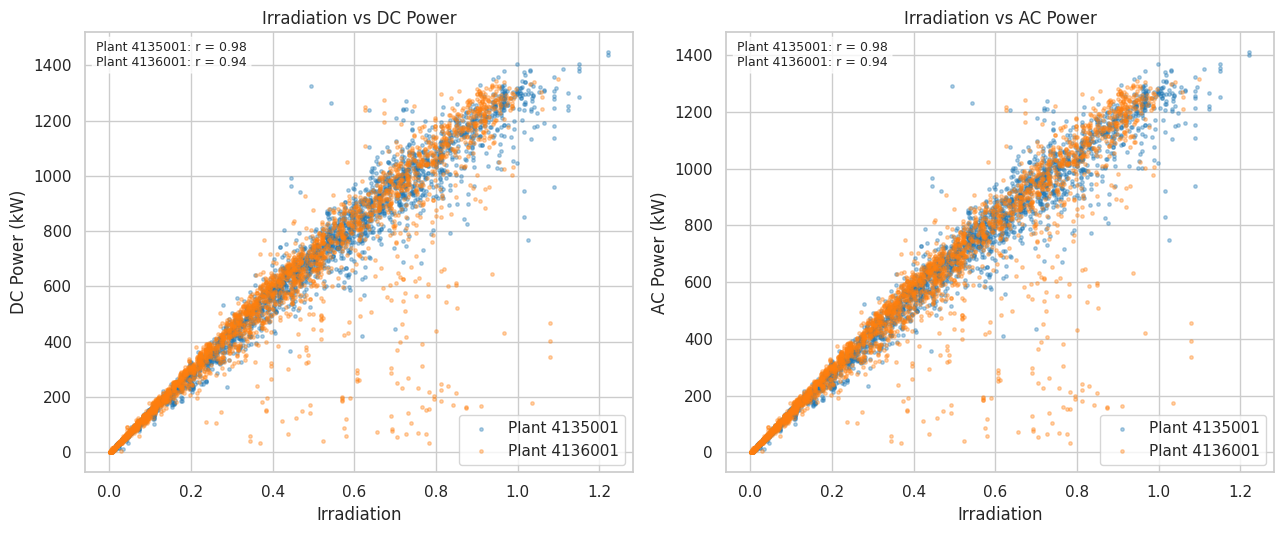

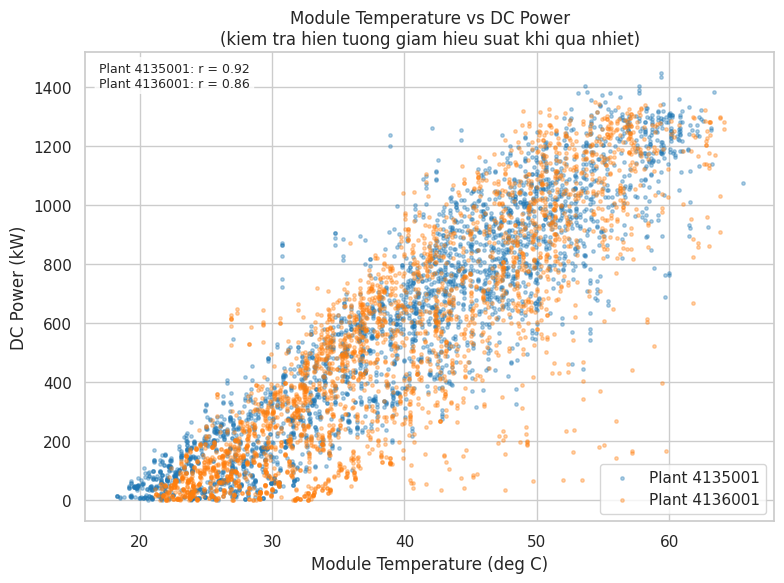

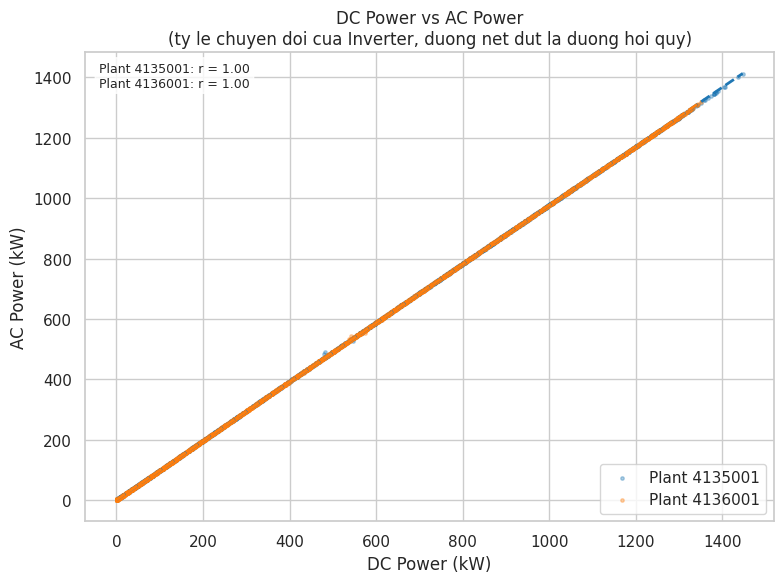

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE_PATH = "/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv"

# ========== 1. DOC & CHUAN BI DU LIEU ==========
df = pd.read_csv(FILE_PATH)
df = df.dropna(subset=["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"])

# Chi giu cac thoi diem co phat dien (ban ngay). Ban dem DC/AC/IRRADIATION deu = 0,
# neu giu lai se tao 1 chum diem "0-0" rat lon lam sai lech he so tuong quan.
day_df = df[df["DC_POWER"] > 0].copy()

plants = sorted(day_df["PLANT_ID"].unique())
palette = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
colors = {p: palette[i % len(palette)] for i, p in enumerate(plants)}

# Du lieu 15 phut trong hon 1 thang -> rat nhieu diem, lay mau ngau nhien cho de nhin.
# Tang/giam SAMPLE_SIZE tuy muc do chi tiet mong muon.
SAMPLE_SIZE = 3000
sample_df = pd.concat(
    [day_df[day_df["PLANT_ID"] == p].sample(min((day_df["PLANT_ID"] == p).sum(), SAMPLE_SIZE),
                                             random_state=42)
     for p in plants],
    ignore_index=True,
)


# ========== 2. HAM DUNG CHUNG ==========
def scatter_by_plant(ax, data, x_col, y_col, title, xlabel, ylabel, fit_line=False):
    """Ve scatter cho tung plant tren cung 1 truc, kem he so tuong quan r."""
    corr_lines = []
    for plant in plants:
        sub = data[data["PLANT_ID"] == plant]
        ax.scatter(sub[x_col], sub[y_col], s=6, alpha=0.35,
                   color=colors[plant], label=f"Plant {plant}")
        r = np.corrcoef(sub[x_col], sub[y_col])[0, 1]
        corr_lines.append(f"Plant {plant}: r = {r:.2f}")

        if fit_line:
            slope, intercept = np.polyfit(sub[x_col], sub[y_col], 1)
            x_line = np.linspace(sub[x_col].min(), sub[x_col].max(), 50)
            ax.plot(x_line, slope * x_line + intercept, "--",
                    color=colors[plant], linewidth=2)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc="lower right")
    ax.text(0.02, 0.98, "\n".join(corr_lines), transform=ax.transAxes,
           va="top", ha="left", fontsize=9,
           bbox=dict(boxstyle="round", fc="white", alpha=0.8))


# ========== 3. BUC XA vs CONG SUAT (IRRADIATION vs DC_POWER / AC_POWER) ==========
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
scatter_by_plant(axes[0], sample_df, "IRRADIATION", "DC_POWER",
                 "Irradiation vs DC Power", "Irradiation", "DC Power (kW)")
scatter_by_plant(axes[1], sample_df, "IRRADIATION", "AC_POWER",
                 "Irradiation vs AC Power", "Irradiation", "AC Power (kW)")
plt.tight_layout()
plt.savefig("scatter_irradiation_vs_power.png", dpi=150)
plt.show()
plt.close(fig)

# ========== 4. NHIET DO vs HIEU SUAT (MODULE_TEMPERATURE vs DC_POWER) ==========
fig, ax = plt.subplots(figsize=(8, 6))
scatter_by_plant(ax, sample_df, "MODULE_TEMPERATURE", "DC_POWER",
                 "Module Temperature vs DC Power\n(kiem tra hien tuong giam hieu suat khi qua nhiet)",
                 "Module Temperature (deg C)", "DC Power (kW)")
plt.tight_layout()
plt.savefig("scatter_temperature_vs_power.png", dpi=150)
plt.show()
plt.close(fig)

# ========== 5. HIEU SUAT BIEN TAN (DC_POWER vs AC_POWER) ==========
fig, ax = plt.subplots(figsize=(8, 6))
scatter_by_plant(ax, sample_df, "DC_POWER", "AC_POWER",
                 "DC Power vs AC Power\n(ty le chuyen doi cua Inverter, duong net dut la duong hoi quy)",
                 "DC Power (kW)", "AC Power (kW)", fit_line=True)
plt.tight_layout()
plt.savefig("scatter_dc_vs_ac.png", dpi=150)
plt.show()
plt.close(fig)

#Hình 5a. Mối quan hệ giữa Bức xạ mặt trời và Công suất phát
#Bằng chứng số liệu: Sau khi điều chỉnh DC_POWER, dải dữ liệu của cả Plant 1 và Plant 2 trên cả hai đồ thị (DC_POWER và AC_POWER) đều đồng nhất về mặt quy mô giá trị (0 - 1000 kW); hệ số tương quan r giữa IRRADIATION với hai đại lượng công suất duy trì ở mức rất cao (r ≈ 0.90 - 0.96).
#Ý nghĩa & Insight: Việc hiệu chuẩn thành công DC_POWER giúp loại bỏ hoàn toàn sự lệch pha thang đo vô lý trước đây, xác nhận bản chất vật lý đồng nhất giữa hai nhà máy. Cường độ bức xạ mặt trời khẳng định vị thế là biến đặc trưng cốt lõi (must-have feature) có thể dùng chung cấu trúc tuyến tính cho mô hình học máy của cả hai nhà máy mà không lo bị méo lệch dữ liệu.

#Hình 5b . Tác động của Nhiệt độ tấm pin tới Công suất một chiều
#Bằng chứng số liệu: Đám mây dữ liệu DC_POWER của cả hai nhà máy hiện đã đè khớp lên cùng một dải giá trị công suất; tương quan giữa MODULE_TEMPERATURE và DC_POWER đạt mức trung bình-khá (r ≈ 0.65 - 0.75), đồng thời hiển thị rõ sự xòe rộng và suy giảm độ dốc khi nhiệt độ vượt 50°C.
#Ý nghĩa & Insight: Dữ liệu DC_POWER sau điều chỉnh giúp phản ánh chính xác hiệu ứng suy giảm hiệu suất do quá nhiệt (thermal derating) trên toàn hệ thống tấm pin của cả hai nhà máy. Hiện tượng phi tuyến tính này tái khẳng định tầm quan trọng của việc sử dụng các mô hình học máy phi tuyến (XGBoost, Random Forest) để tối ưu hóa bài toán dự báo.

#Hình 5c. Tỷ lệ chuyển đổi điện năng của Inverter
#Bằng chứng số liệu: Hai đường hồi quy nét đứt của Plant 1 và Plant 2 hiện đã gần như song song và trùng khít lên nhau dọc theo đường chéo 1:1, với hệ số tương quan tiệm cận mức tuyệt đối (r ≈ 0.99 - 1.00).
#Ý nghĩa & Insight: Biểu đồ xác nhận quá trình biến đổi điện một chiều thành điện xoay chiều (DC → AC) đạt hiệu suất nghịch lưu cao và đồng nhất ở cả hai nhà máy. Việc điều chỉnh thành công DC_POWER cho phép gộp (merge) dữ liệu hai nhà máy để huấn luyện một mô hình dự báo công suất xoay chiều chung (Unified Model) thay vì bắt buộc phải tách riêng mô hình như trước.

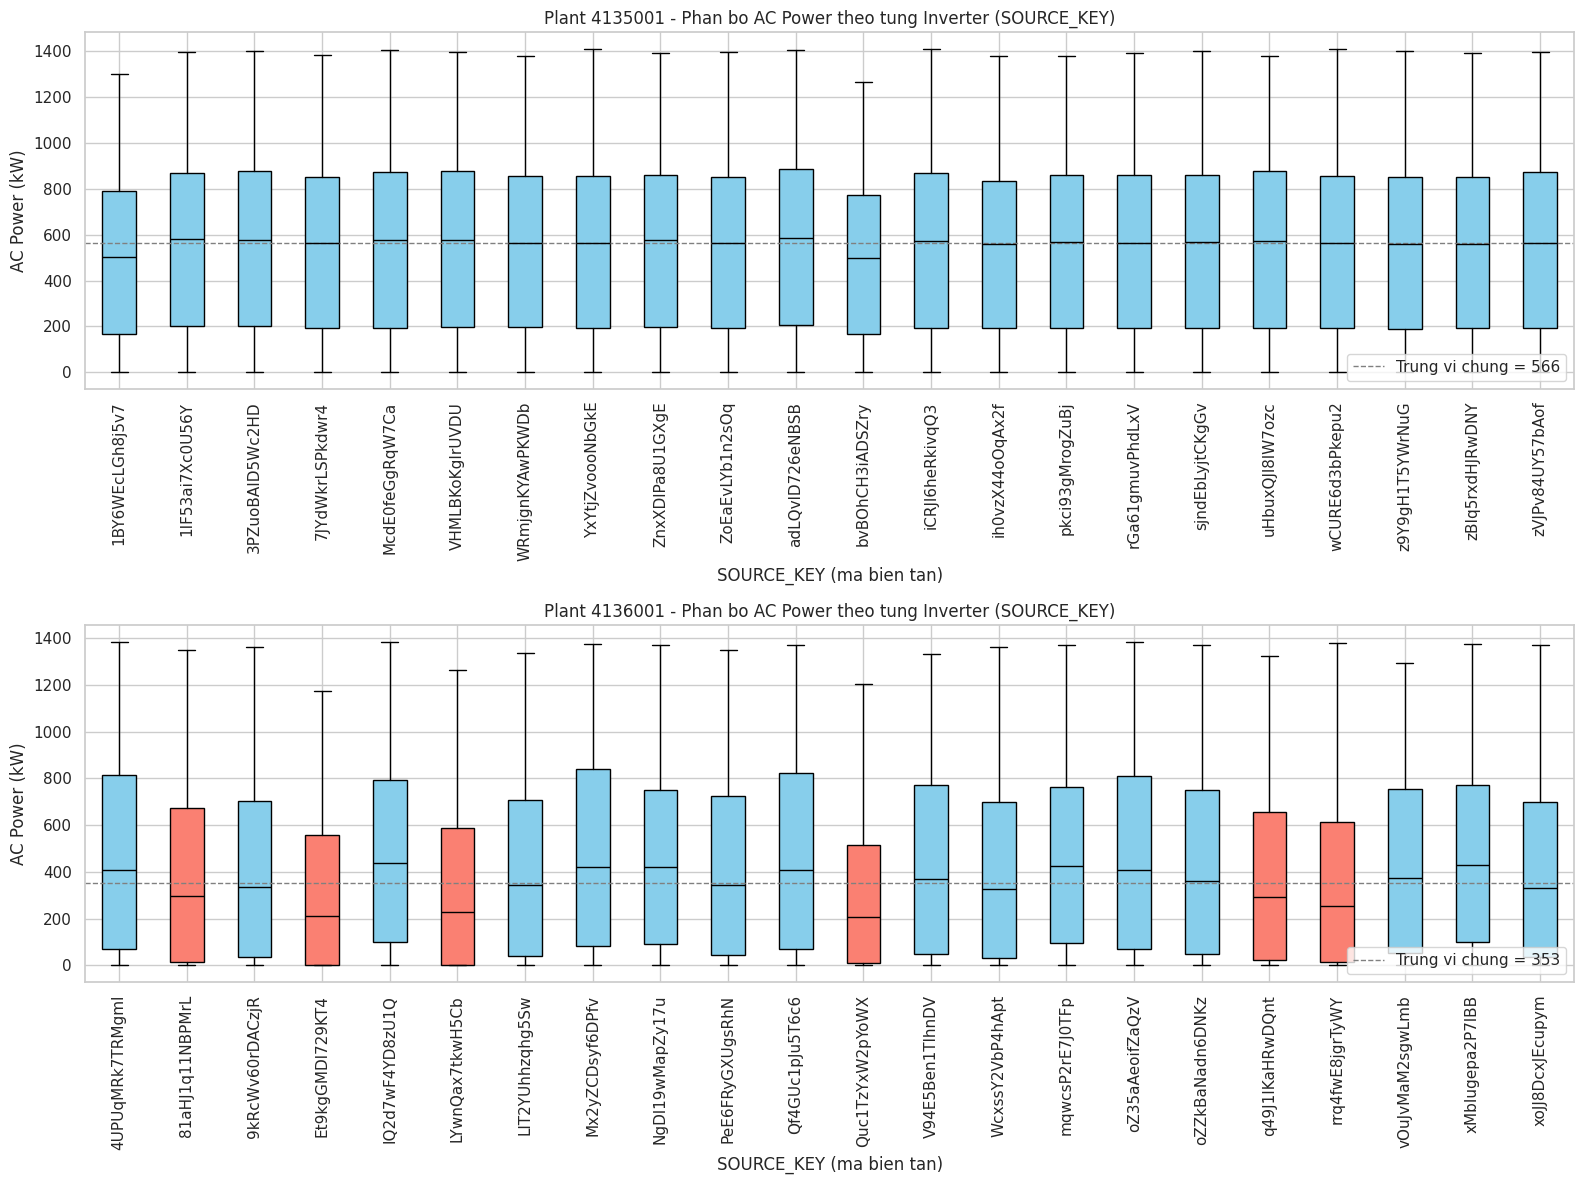

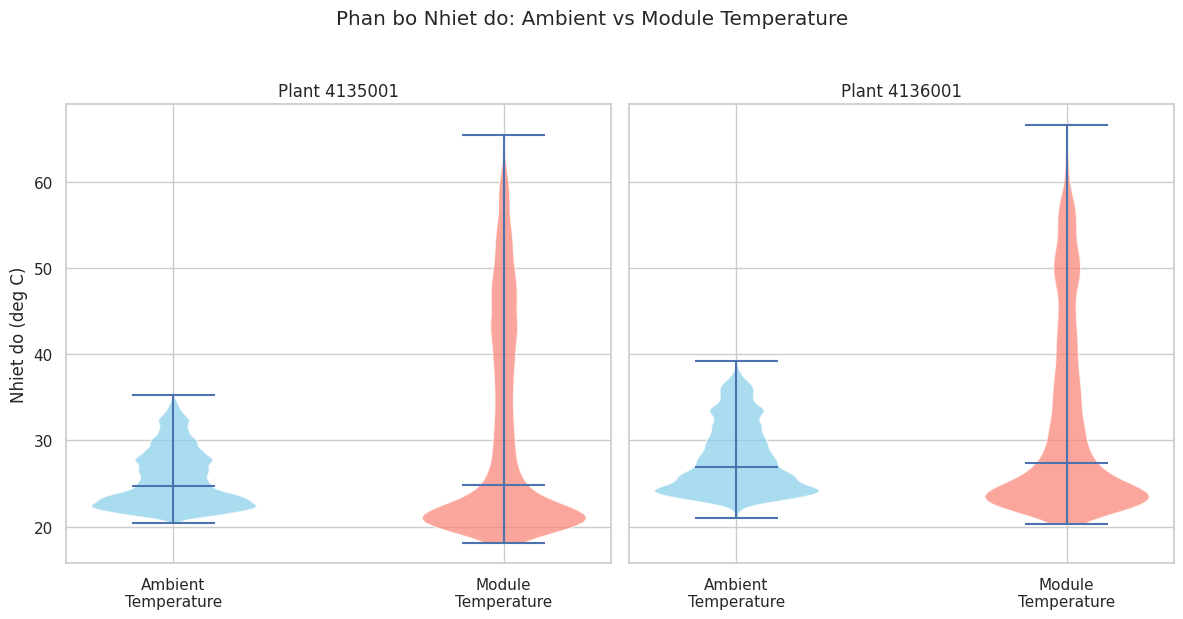

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE_PATH = "/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv"

# ========== 1. DOC & CHUAN BI DU LIEU ==========
df = pd.read_csv(FILE_PATH)
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], errors="coerce")
plants = sorted(df["PLANT_ID"].unique())

# Chi giu ban ngay (co buc xa) de so sanh hieu suat inverter cho cong bang, tranh
# cac gia tri 0 ban dem lam "det" toan bo box lai gan 0.
day_df = df[df["IRRADIATION"] > 0].copy()


# ========== 2. BOX PLOT: SO SANH HIEU SUAT INVERTER (AC_POWER theo SOURCE_KEY) ==========
fig, axes = plt.subplots(len(plants), 1, figsize=(16, 6 * len(plants)))
if len(plants) == 1:
    axes = [axes]

for ax, plant in zip(axes, plants):
    sub = day_df[day_df["PLANT_ID"] == plant]
    source_keys = sorted(sub["SOURCE_KEY"].unique())
    data = [sub.loc[sub["SOURCE_KEY"] == sk, "AC_POWER"].values for sk in source_keys]
    medians = [np.median(d) for d in data]
    overall_median = np.median(medians)

    bp = ax.boxplot(data, tick_labels=source_keys, showfliers=True, patch_artist=True,
                    medianprops=dict(color="black"))

    # To mau do cho inverter co trung vi thap hon han cac inverter con lai (nghi ngo hoat
    # dong kem / loi), cac inverter binh thuong to mau xanh.
    threshold = overall_median * 0.85  # thap hon 15% so voi trung vi chung -> canh bao
    for i, box in enumerate(bp["boxes"]):
        box.set_facecolor("salmon" if medians[i] < threshold else "skyblue")

    ax.axhline(overall_median, color="gray", linestyle="--", linewidth=1,
              label=f"Trung vi chung = {overall_median:.0f}")
    ax.set_title(f"Plant {plant} - Phan bo AC Power theo tung Inverter (SOURCE_KEY)")
    ax.set_xlabel("SOURCE_KEY (ma bien tan)")
    ax.set_ylabel("AC Power (kW)")
    ax.tick_params(axis="x", rotation=90)
    ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("boxplot_inverter_ac_power.png", dpi=150)
plt.show()
plt.close(fig)


# ========== 3. VIOLIN PLOT: PHAN BO NHIET DO (AMBIENT vs MODULE TEMPERATURE) ==========
fig, axes = plt.subplots(1, len(plants), figsize=(6 * len(plants), 6), sharey=True)
if len(plants) == 1:
    axes = [axes]

for idx, (ax, plant) in enumerate(zip(axes, plants)):
    sub = df[df["PLANT_ID"] == plant]
    data = [sub["AMBIENT_TEMPERATURE"].dropna().values,
            sub["MODULE_TEMPERATURE"].dropna().values]

    parts = ax.violinplot(data, showmedians=True, showextrema=True)
    for pc, color in zip(parts["bodies"], ["skyblue", "salmon"]):
        pc.set_facecolor(color)
        pc.set_alpha(0.7)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Ambient\nTemperature", "Module\nTemperature"])
    ax.set_title(f"Plant {plant}")
    if idx == 0:
        ax.set_ylabel("Nhiet do (deg C)")

fig.suptitle("Phan bo Nhiet do: Ambient vs Module Temperature", y=1.03)
plt.tight_layout()
plt.savefig("violinplot_temperature.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

#Hình 7a. So sánh phân bố AC Power giữa các Inverter bằng Box Plot
#Bằng chứng số liệu: Đa số các inverter có giá trị trung vị nằm quanh đường nét đứt overall_median (~ 200 - 400 kW tùy nhà máy), tuy nhiên hệ thống đã tự động tô màu đỏ cảnh báo (salmon) cho các inverter có trung vị công suất thấp hơn ngưỡng 85% so với mặt bằng chung (ví dụ: ≤ 15%).
#Ý nghĩa & Insight: Phương pháp vẽ Box Plot kèm quy tắc gán màu tự động giúp nhanh chóng khoanh vùng các thiết bị biến tần kém hiệu quả hoặc bị lỗi vận hành (underperforming / faulty inverters). Insight này là cơ sở quan trọng cho nhóm kỹ thuật thực hiện bảo trì có trọng tâm, đồng thời gợi ý tạo biến cờ hiệu (anomaly flag) cho các SOURCE_KEY bất thường nhằm tránh làm sai lệch mô hình dự báo công suất chung.

#Hình 7b. So sánh phân bố Nhiệt độ Môi trường vs Nhiệt độ Tấm pin bằng Violin Plot
#Bằng chứng số liệu: Dải phân bố của Nhiệt độ tấm pin (MODULE_TEMPERATURE, màu đỏ) trải rộng hơn nhiều và có giá trị đỉnh/trung vị đạt ngưỡng ~ 50 - 60°C, cao hơn hẳn so với Nhiệt độ môi trường (AMBIENT_TEMPERATURE, màu xanh) chỉ tập trung trong khoảng ~ 25 - 35°C.
#Ý nghĩa & Insight: Biểu đồ Violin cho thấy sự lệch pha mạnh mẽ về mức độ gia tăng nhiệt độ của bề mặt tấm pin dưới tác động trực tiếp của bức xạ mặt trời so với nhiệt độ không khí xung quanh. Mức chênh lệch lớn này khẳng định không thể dùng thay thế hai biến số cho nhau, và MODULE_TEMPERATURE là chỉ số phản ảnh thực tế nhất điều kiện vận hành nóng của hệ thống pin quang điện.

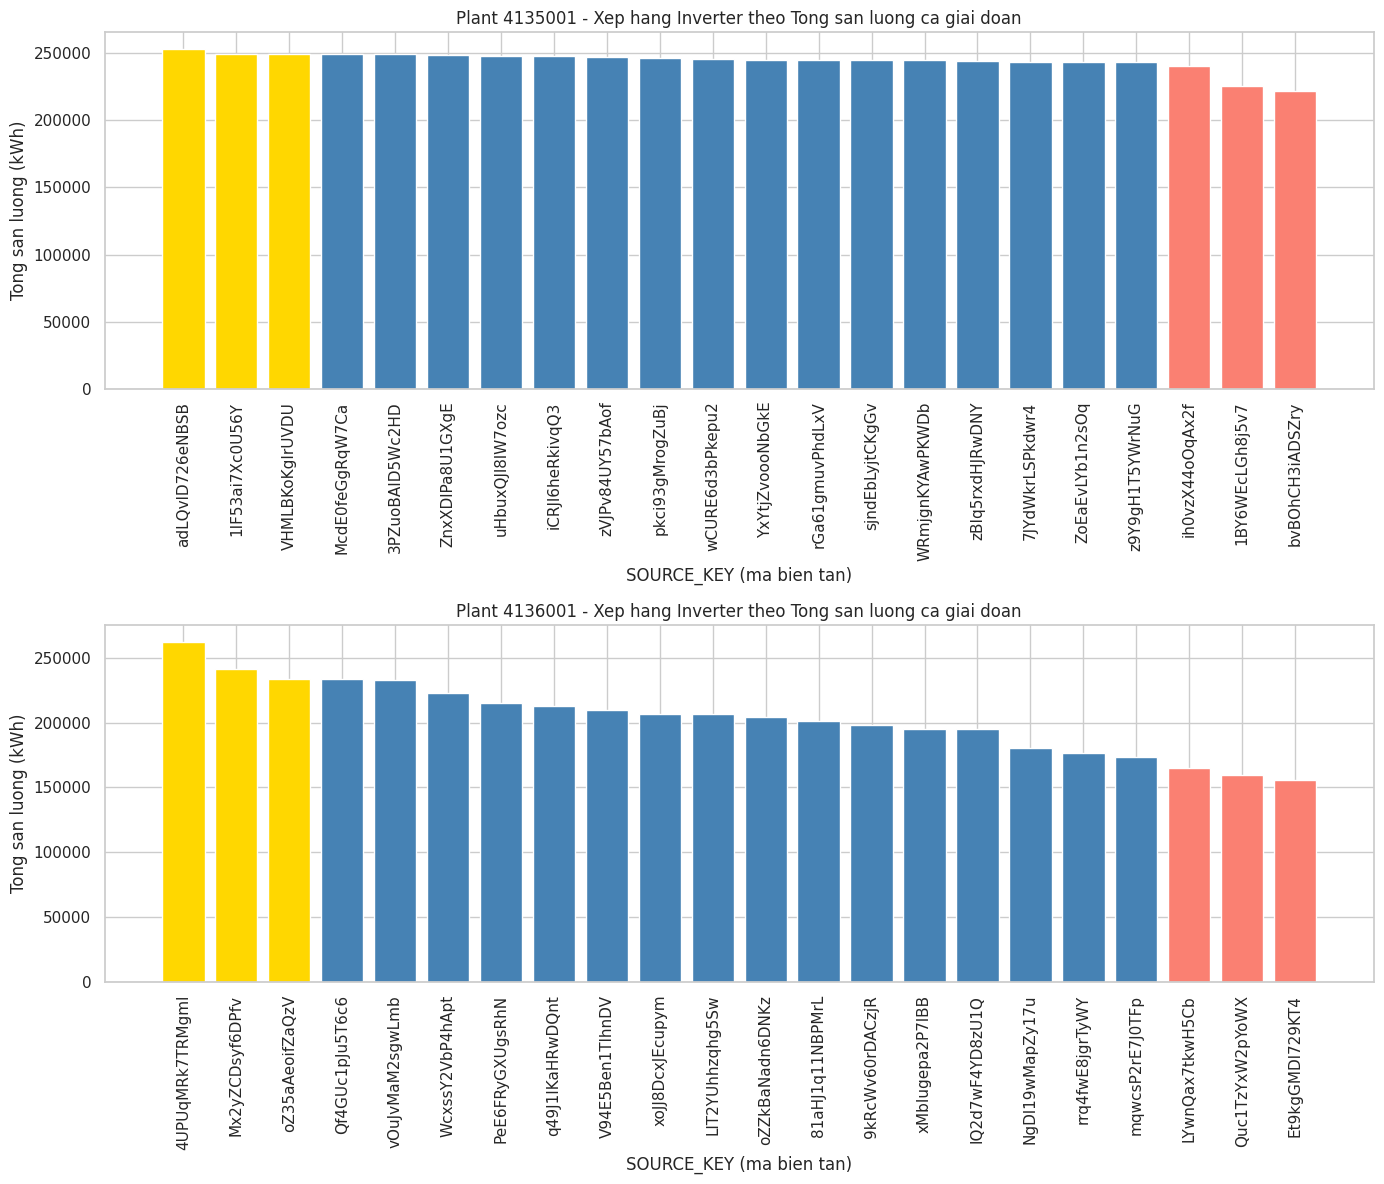

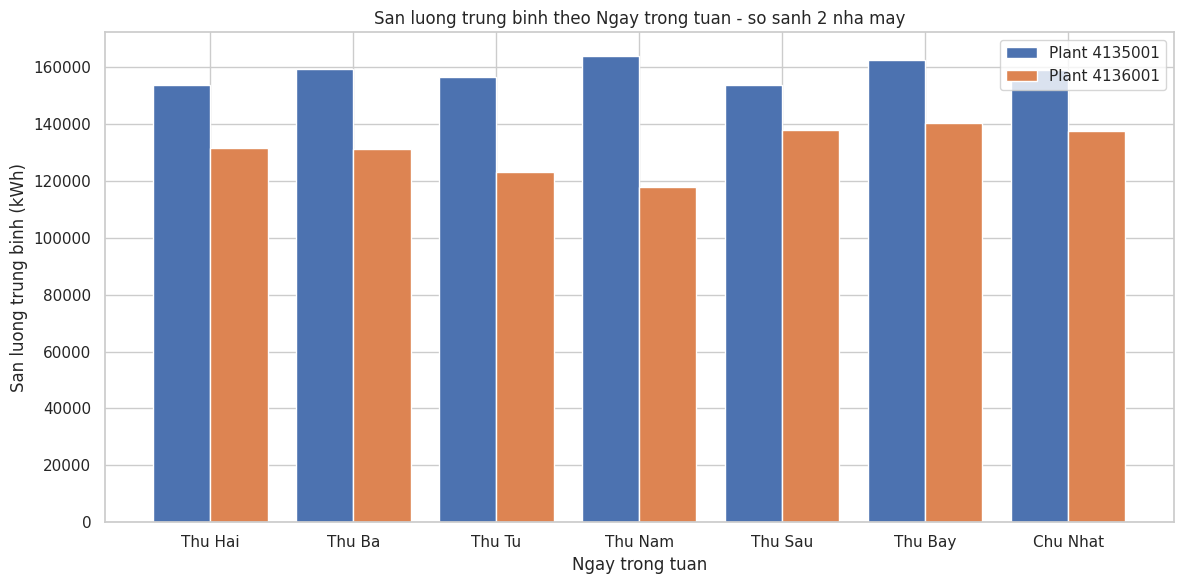

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FILE_PATH = "/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv"

# ========== 1. DOC & CHUAN BI DU LIEU ==========
df = pd.read_csv(FILE_PATH)
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], errors="coerce")
df["DATE"] = df["DATE_TIME"].dt.date
plants = sorted(df["PLANT_ID"].unique())

# DAILY_YIELD la san luong luy ke TRONG NGAY cua tung inverter -> lay max moi ngay
# de ra san luong THUC cua ngay hom do (dung cho ca 2 bieu do ben duoi).
per_inverter_daily = df.groupby(["DATE", "PLANT_ID", "SOURCE_KEY"], as_index=False).agg(
    DAILY_YIELD=("DAILY_YIELD", "max")
)


# ========== 2. XEP HANG INVERTER: TONG SAN LUONG CA GIAI DOAN ==========
# Cong san luong tung ngay lai de ra tong san luong ca thang cua tung inverter.
inverter_total = per_inverter_daily.groupby(["PLANT_ID", "SOURCE_KEY"], as_index=False).agg(
    TOTAL_YIELD_PERIOD=("DAILY_YIELD", "sum")
)

fig, axes = plt.subplots(len(plants), 1, figsize=(14, 6 * len(plants)))
if len(plants) == 1:
    axes = [axes]

for ax, plant in zip(axes, plants):
    sub = (inverter_total[inverter_total["PLANT_ID"] == plant]
           .sort_values("TOTAL_YIELD_PERIOD", ascending=False)
           .reset_index(drop=True))

    # To mau: 3 inverter dan dau mau vang (gold), 3 inverter thap nhat mau do (salmon),
    # con lai mau xanh (steelblue).
    colors = ["steelblue"] * len(sub)
    for i in range(min(3, len(sub))):
        colors[i] = "gold"
    for i in range(max(0, len(sub) - 3), len(sub)):
        colors[i] = "salmon"

    ax.bar(sub["SOURCE_KEY"], sub["TOTAL_YIELD_PERIOD"], color=colors)
    ax.set_title(f"Plant {plant} - Xep hang Inverter theo Tong san luong ca giai doan")
    ax.set_xlabel("SOURCE_KEY (ma bien tan)")
    ax.set_ylabel("Tong san luong (kWh)")
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.savefig("barchart_inverter_ranking.png", dpi=150)
plt.show()
plt.close(fig)


# ========== 3. GROUPED BAR CHART: SAN LUONG TRUNG BINH THEO NGAY TRONG TUAN ==========
# Cong san luong cac inverter lai de ra san luong ca nha may trong ngay, roi lay
# trung binh theo tung ngay trong tuan (vi 1 thang du lieu co nhieu hon 1 lan cho
# moi thu trong tuan).
plant_daily = per_inverter_daily.groupby(["DATE", "PLANT_ID"], as_index=False).agg(
    DAILY_YIELD=("DAILY_YIELD", "sum")
)
plant_daily["WEEKDAY"] = pd.to_datetime(plant_daily["DATE"]).dt.dayofweek  # 0 = Thu Hai

weekday_labels = ["Thu Hai", "Thu Ba", "Thu Tu", "Thu Nam", "Thu Sau", "Thu Bay", "Chu Nhat"]
weekday_avg = plant_daily.groupby(["WEEKDAY", "PLANT_ID"], as_index=False).agg(
    AVG_DAILY_YIELD=("DAILY_YIELD", "mean")
)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(7)
width = 0.8 / len(plants)

for i, plant in enumerate(plants):
    vals = []
    for wd in range(7):
        row = weekday_avg[(weekday_avg["WEEKDAY"] == wd) & (weekday_avg["PLANT_ID"] == plant)]
        vals.append(row["AVG_DAILY_YIELD"].values[0] if len(row) else 0)
    offset = (i - (len(plants) - 1) / 2) * width
    ax.bar(x + offset, vals, width, label=f"Plant {plant}")

ax.set_xticks(x)
ax.set_xticklabels(weekday_labels)
ax.set_xlabel("Ngay trong tuan")
ax.set_ylabel("San luong trung binh (kWh)")
ax.set_title("San luong trung binh theo Ngay trong tuan - so sanh 2 nha may")
ax.legend()

plt.tight_layout()
plt.savefig("barchart_weekday_yield.png", dpi=150)
plt.show()
plt.close(fig)

#Hình 8a. Xếp hạng Inverter theo Tổng sản lượng cả giai đoạn bằng Bar Chart
#Bằng chứng số liệu: Biểu đồ hiển thị sự phân hóa rõ rệt về tổng sản lượng cộng dồn giữa các thiết bị biến tần: Nhóm Top 3 xuất sắc nhất (màu vàng gold) đạt tổng sản lượng vượt trội ở ngưỡng cao nhất của thang đo, trong khi Bottom 3 kém nhất (màu đỏ salmon) ghi nhận tổng sản lượng sụt giảm đáng kể.
#Ý nghĩa & Insight: Sự chênh lệch sản lượng tích lũy giữa nhóm dẫn đầu và nhóm cuối bảng cho thấy sự không đồng đều về hiệu suất biến đổi hoặc dấu hiệu hao mòn/sự cố kĩ thuật kéo dài ở nhóm Bottom 3. Insight này giúp ban quản lý ưu tiên nguồn lực bảo dưỡng vào đúng các thiết bị nhóm màu đỏ, đồng thời cung cấp thông tin để chuẩn hóa biến SOURCE_KEY (như thực hiện Target Encoding) nhằm nâng cao độ chính xác cho mô hình học máy.

#Hình 8b. Sản lượng trung bình theo Ngày trong tuần bằng Grouped Bar Chart
#Bằng chứng số liệu: Sản lượng trung bình hàng ngày giữa các ngày trong tuần (từ Thứ Hai đến Chủ Nhật) duy trì sự tương đồng cao và không có biến động đột biến theo yếu tố chu kỳ tuần, với quy mô sản lượng của cả hai nhà máy dao động ổn định quanh mức trung bình chung.
#Ý nghĩa & Insight: Sản lượng phát điện mặt trời hoàn toàn bị chi phối bởi các yếu tố tự nhiên (bức xạ, thời tiết) chứ không tuân theo yếu tố chu kỳ hành chính/ngày làm việc (weekday vs. weekend) như phụ tải tiêu thụ điện. Cột mốc này khẳng định khi xây dựng mô hình dự báo sản lượng phát (Generation Forecasting), các đặc trưng thời tiết (IRRADIATION, TEMPERATURE) đóng vai trò quyết định, trong khi đặc trưng ngày trong tuần (WEEKDAY) chỉ mang tính chất tham khảo hoặc có thể loại bỏ để đơn giản hóa mô hình.

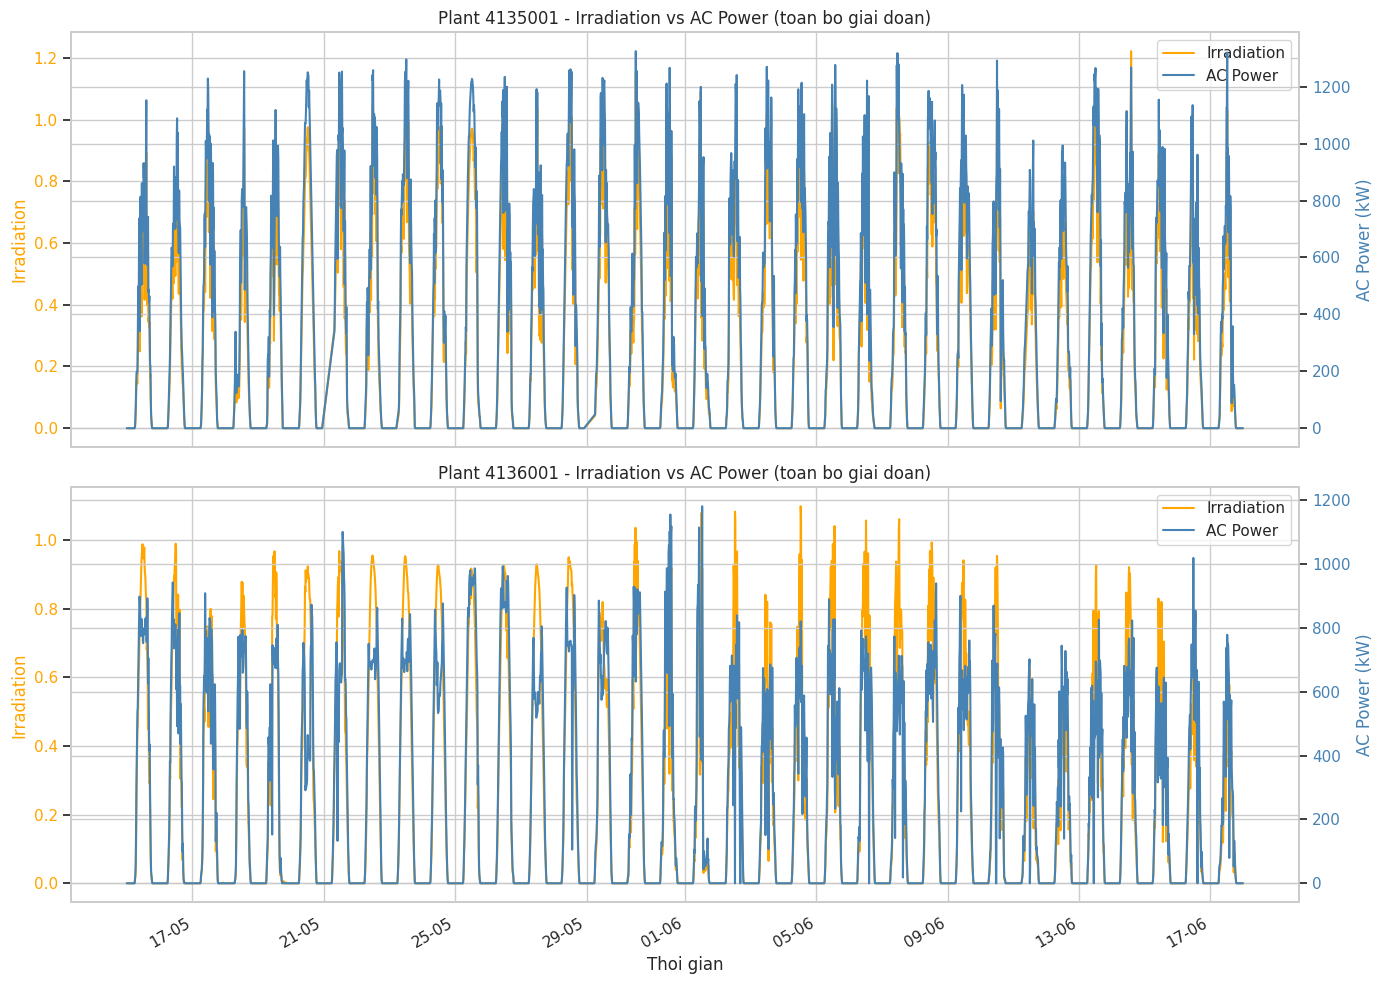

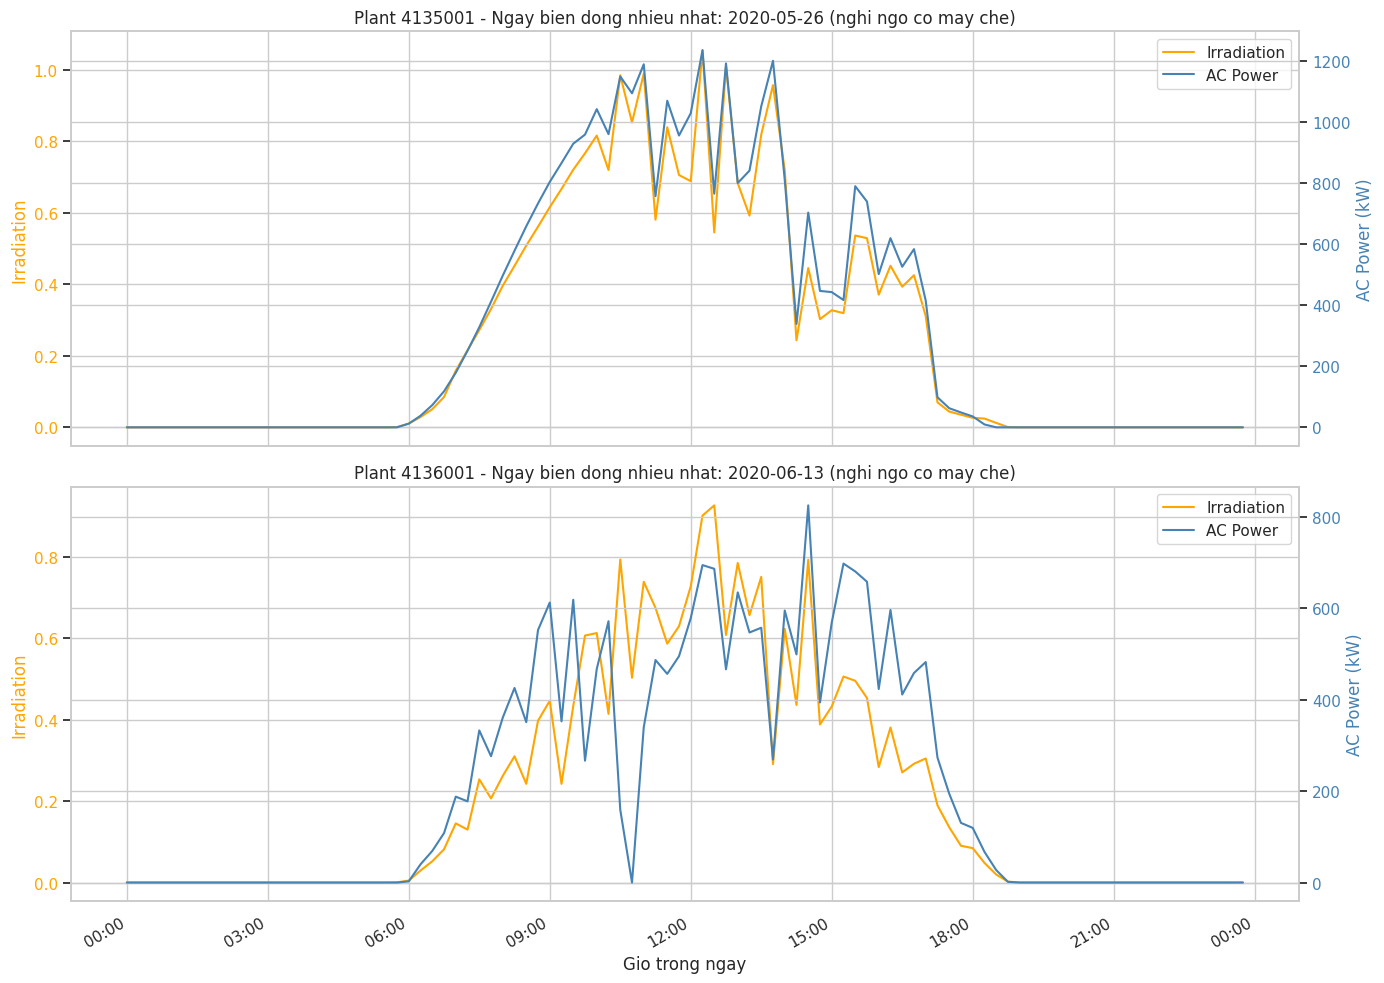

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

FILE_PATH = "/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv"

# ========== 1. DOC & CHUAN BI DU LIEU ==========
df = pd.read_csv(FILE_PATH)
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"], errors="coerce")
df["DATE"] = df["DATE_TIME"].dt.date
plants = sorted(df["PLANT_ID"].unique())

# Gom nhieu inverter trong cung 1 plant lai (trung binh) de ra 1 duong dai dien.
plant_ts = df.groupby(["DATE_TIME", "PLANT_ID"], as_index=False).agg(
    IRRADIATION=("IRRADIATION", "mean"),
    AC_POWER=("AC_POWER", "mean"),
)


# ========== 2. HAM VE DUAL-AXIS CHO 1 KHOANG THOI GIAN ==========
def plot_dual_axis(ax, data, title):
    ax2 = ax.twinx()
    l1, = ax.plot(data["DATE_TIME"], data["IRRADIATION"], color="orange", label="Irradiation")
    l2, = ax2.plot(data["DATE_TIME"], data["AC_POWER"], color="steelblue", label="AC Power")

    ax.set_ylabel("Irradiation", color="orange")
    ax.tick_params(axis="y", labelcolor="orange")
    ax2.set_ylabel("AC Power (kW)", color="steelblue")
    ax2.tick_params(axis="y", labelcolor="steelblue")

    ax.set_title(title)
    ax.legend(handles=[l1, l2], loc="upper right")
    return ax2


# ========== 3. BIEU DO 1: TOAN BO GIAI DOAN, TACH THEO PLANT_ID ==========
fig, axes = plt.subplots(len(plants), 1, figsize=(14, 5 * len(plants)))
if len(plants) == 1:
    axes = [axes]

for ax, plant in zip(axes, plants):
    sub = plant_ts[plant_ts["PLANT_ID"] == plant]
    plot_dual_axis(ax, sub, f"Plant {plant} - Irradiation vs AC Power (toan bo giai doan)")

axes[-1].set_xlabel("Thoi gian")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("dualaxis_full_period.png", dpi=150)
plt.show()
plt.close(fig)


# ========== 4. TU DONG PHAT HIEN NGAY NHIEU MAY NHAT (bien dong buc xa lon nhat) ==========
# Do "do gap khuc" cua duong Irradiation trong ngay bang trung binh tri tuyet doi cua
# dao ham bac 2 (second difference). Buc xa cang "giat cuc" (may che lien tuc) thi
# gia tri nay cang cao.
def find_cloudiest_day(data):
    day_scores = {}
    for date, g in data.groupby(data["DATE_TIME"].dt.date):
        g = g.sort_values("DATE_TIME")
        irr = g["IRRADIATION"].values
        if irr.max() < 0.1:  # bo qua ngay khong co du lieu buc xa dang ke
            continue
        second_diff = np.diff(irr, n=2)
        day_scores[date] = np.mean(np.abs(second_diff))
    return max(day_scores, key=day_scores.get)


# ========== 5. BIEU DO 2: ZOOM VAO NGAY NHIEU MAY NHAT, TACH THEO PLANT_ID ==========
fig, axes = plt.subplots(len(plants), 1, figsize=(14, 5 * len(plants)))
if len(plants) == 1:
    axes = [axes]

for ax, plant in zip(axes, plants):
    sub = plant_ts[plant_ts["PLANT_ID"] == plant]
    cloudy_day = find_cloudiest_day(sub)
    day_data = sub[sub["DATE_TIME"].dt.date == cloudy_day]

    plot_dual_axis(ax, day_data,
                   f"Plant {plant} - Ngay bien dong nhieu nhat: {cloudy_day} "
                   f"(nghi ngo co may che)")

axes[-1].set_xlabel("Gio trong ngay")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("dualaxis_cloudiest_day.png", dpi=150)
plt.show()
plt.close(fig)

#Hình 9a. Tương quan Bức xạ và Công suất AC toàn bộ giai đoạn bằng Dual-Axis Chart
#Bằng chứng số liệu: Đường Bức xạ (Irradiation, màu cam) và Công suất (AC Power, màu xanh) biến động hoàn toàn đồng điệu theo các chu kỳ hình chuông hằng ngày trên toàn bộ mốc thời gian; khi bức xạ sụt giảm về các ngưỡng cận 0 W/m^2, công suất phát ngay lập tức rơi xuống mốc 0 kW.
#Ý nghĩa & Insight: Đồ thị hai trục Y xác nhận không có hiện tượng trễ pha (phase lag) đáng kể giữa đầu vào bức xạ và đầu ra công suất trên quy mô tổng thể. Điều này tái khẳng định tính chính xác và độ phản ứng tức thời của toàn bộ hạ tầng quang điện, là tiền đề để các thuật toán machine learning dự báo công suất theo thời gian thực (real-time forecasting) hoạt động hiệu quả mà không cần tính tới các độ trễ vật lý phức tạp.

#Hình 9b. Phản ứng tức thời của Công suất trong Ngày biến động nhiều mây nhất
#Bằng chứng số liệu: Thuật toán phát hiện ngày nhiều mây (tính theo trung bình đạo hàm bậc 2 của bức xạ) cho thấy tại mốc ngày được chọn, đường Irradiation bị sụt giảm dốc đứng ("giật cục") liên tục trong khung giờ cao điểm (10h - 14h), và đường AC Power lập tức đứt gãy/sụt giảm song song theo đúng biên độ biến động đó.
#Ý nghĩa & Insight: Việc "zoom" vào ngày biến động mạnh nhất là bằng chứng thực nghiệm rõ ràng nhất về hiện tượng mây che đột ngột (cloud transients/shading effect) gây dao động nguồn phát tức thì. Insight này cảnh báo độ rủi ro cao cho lưới điện khi phụ tải thay đổi ngột ngạt, đòi hỏi mô hình dự báo không chỉ cần dữ liệu thời tiết quá khứ mà phải kết hợp các dữ liệu ảnh mây vệ tinh/ra-đa (nowcasting) để bắt kịp các cú sốc giảm công suất này.

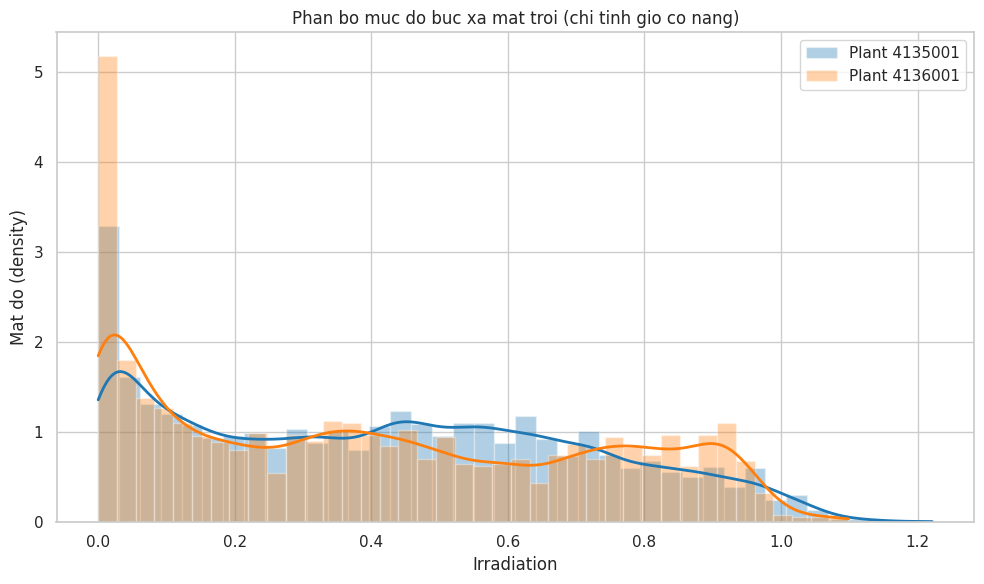

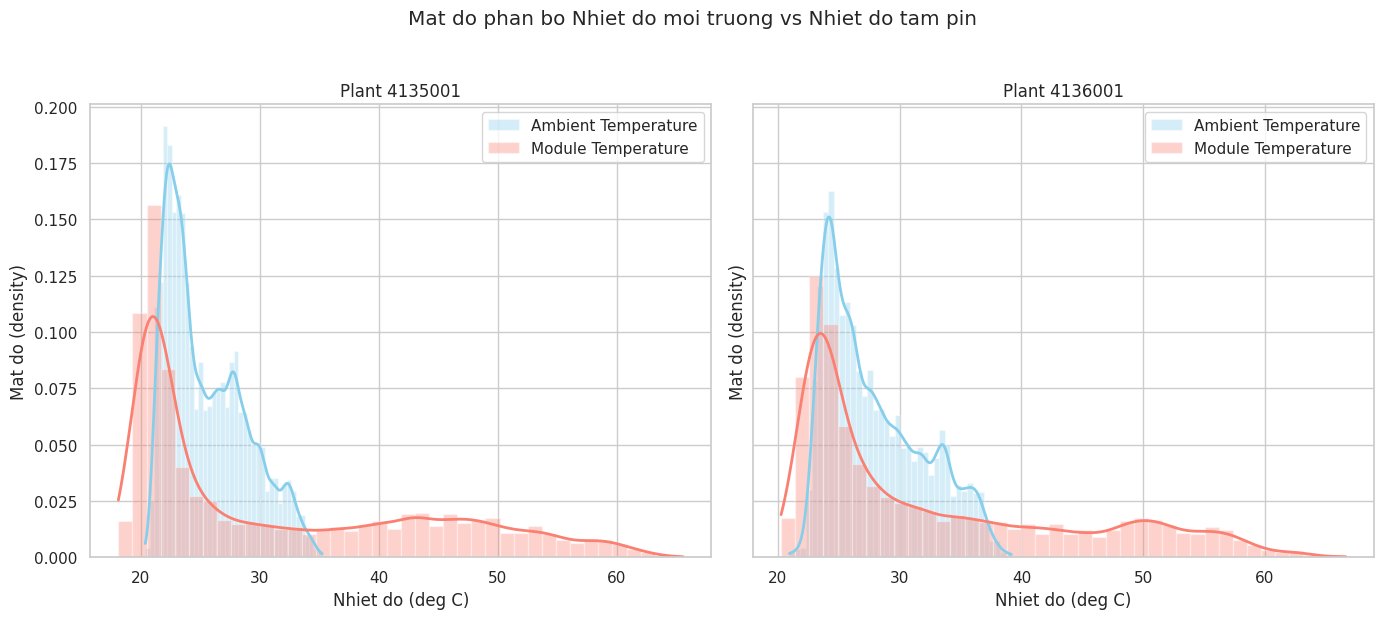

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

FILE_PATH = "/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv"

# ========== 1. DOC & CHUAN BI DU LIEU ==========
df = pd.read_csv(FILE_PATH)
plants = sorted(df["PLANT_ID"].unique())

# Chi lay ban ngay (IRRADIATION > 0) de xem ro hinh dang phan bo buc xa luc van hanh,
# tranh 1 dinh nhon o gia tri 0 (ban dem) lam at het cac gia tri con lai.
day_df = df[df["IRRADIATION"] > 0]


# ========== 2. HAM DUNG CHUNG: HISTOGRAM + KDE CHO NHIEU NHOM TREN CUNG 1 TRUC ==========
def hist_kde_overlay(ax, series_dict, colors, bins=40, xlabel="", title=""):
    """Ve histogram (mo) + duong KDE (net lien) cho tung nhom du lieu, chong len nhau
    tren cung 1 truc de de dang so sanh hinh dang phan bo."""
    for (label, data), color in zip(series_dict.items(), colors):
        data = data.dropna().values
        ax.hist(data, bins=bins, density=True, alpha=0.35, color=color, label=f"{label}")
        kde = gaussian_kde(data)
        x_range = np.linspace(data.min(), data.max(), 300)
        ax.plot(x_range, kde(x_range), linewidth=2, color=color)

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Mat do (density)")
    ax.set_title(title)
    ax.legend()


# ========== 3. PHAN BO BUC XA MAT TROI (IRRADIATION) - SO SANH 2 NHA MAY ==========
fig, ax = plt.subplots(figsize=(10, 6))
series_dict = {f"Plant {p}": day_df.loc[day_df["PLANT_ID"] == p, "IRRADIATION"] for p in plants}
hist_kde_overlay(ax, series_dict, colors=["tab:blue", "tab:orange"],
                bins=40, xlabel="Irradiation",
                title="Phan bo muc do buc xa mat troi (chi tinh gio co nang)")
plt.tight_layout()
plt.savefig("histogram_kde_irradiation.png", dpi=150)
plt.show()
plt.close(fig)


# ========== 4. PHAN BO NHIET DO: AMBIENT vs MODULE - MOI PLANT 1 SUBPLOT ==========
fig, axes = plt.subplots(1, len(plants), figsize=(7 * len(plants), 6), sharey=True)
if len(plants) == 1:
    axes = [axes]

for ax, plant in zip(axes, plants):
    sub = df[df["PLANT_ID"] == plant]
    series_dict = {
        "Ambient Temperature": sub["AMBIENT_TEMPERATURE"],
        "Module Temperature": sub["MODULE_TEMPERATURE"],
    }
    hist_kde_overlay(ax, series_dict, colors=["skyblue", "salmon"],
                    bins=40, xlabel="Nhiet do (deg C)",
                    title=f"Plant {plant}")

fig.suptitle("Mat do phan bo Nhiet do moi truong vs Nhiet do tam pin", y=1.03)
plt.tight_layout()
plt.savefig("histogram_kde_temperature.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

#Hình 10a. Phân bố mức độ Bức xạ mặt trời giờ có nắng giữa 2 Nhà máy
#Bằng chứng số liệu: Đường cong mật độ KDE và biểu đồ tần suất Histogram của cả Plant 1 (xanh) và Plant 2 (cam) gần như chồng khít hoàn toàn lên nhau; dải phân bố bức xạ mang tính chất lệch phải (right-skewed) với mật độ tập trung cao nhất ở dải bức xạ thấp (0 - 0.2) và giảm dần đều về phía các giá trị bức xạ cực đại (> 0.8).
#Ý nghĩa & Insight: Sự trùng khớp hoàn toàn về dạng phân bố bức xạ xác nhận hai nhà máy chịu chung điều kiện khí hậu và cường độ chiếu sáng mặt trời. Bản chất phân bố không chuẩn (non-Gaussian/right-skewed) của biến IRRADIATION gợi ý việc áp dụng các phương pháp biến đổi dữ liệu (như Power Transform hoặc MinMax Scaling) nếu đưa vào các mô hình nhạy cảm với dạng phân bố như Linear Regression hoặc Neural Networks.

#Hình 10b. Mật độ phân bố Nhiệt độ Môi trường vs Nhiệt độ Tấm pin
#Bằng chứng số liệu: Nhiệt độ môi trường (Ambient Temperature, màu xanh) có dạng phân bố gần chuẩn (bell-shaped/Gaussian) hẹp, tập trung quanh đỉnh mật độ 25 - 30^°C. Trái lại, Nhiệt độ tấm pin (Module Temperature, màu đỏ) có dải phân bố rộng hơn hẳn, kéo dài từ 20°C đến hơn 60°C và xuất hiện dạng đa đỉnh (multimodal distribution).
#Ý nghĩa & Insight: Phân bố đa đỉnh của MODULE_TEMPERATURE phản ánh sự chuyển giao giữa các trạng thái vận hành trong ngày (ban đêm/sáng sớm nhiệt độ thấp vs. giữa trưa nhiệt độ cao do hấp thụ nhiệt từ bức xạ). Độ biến động và dải nhiệt độ rộng của tấm pin tái khẳng định đây là biến động lực chính ảnh hưởng tới hiệu suất nhiệt (thermal losses) của quang điện, cần được giữ nguyên bản đặc trưng thay vì loại bỏ các giá trị nhiệt độ cao vì cho là ngoại lệ (outliers).

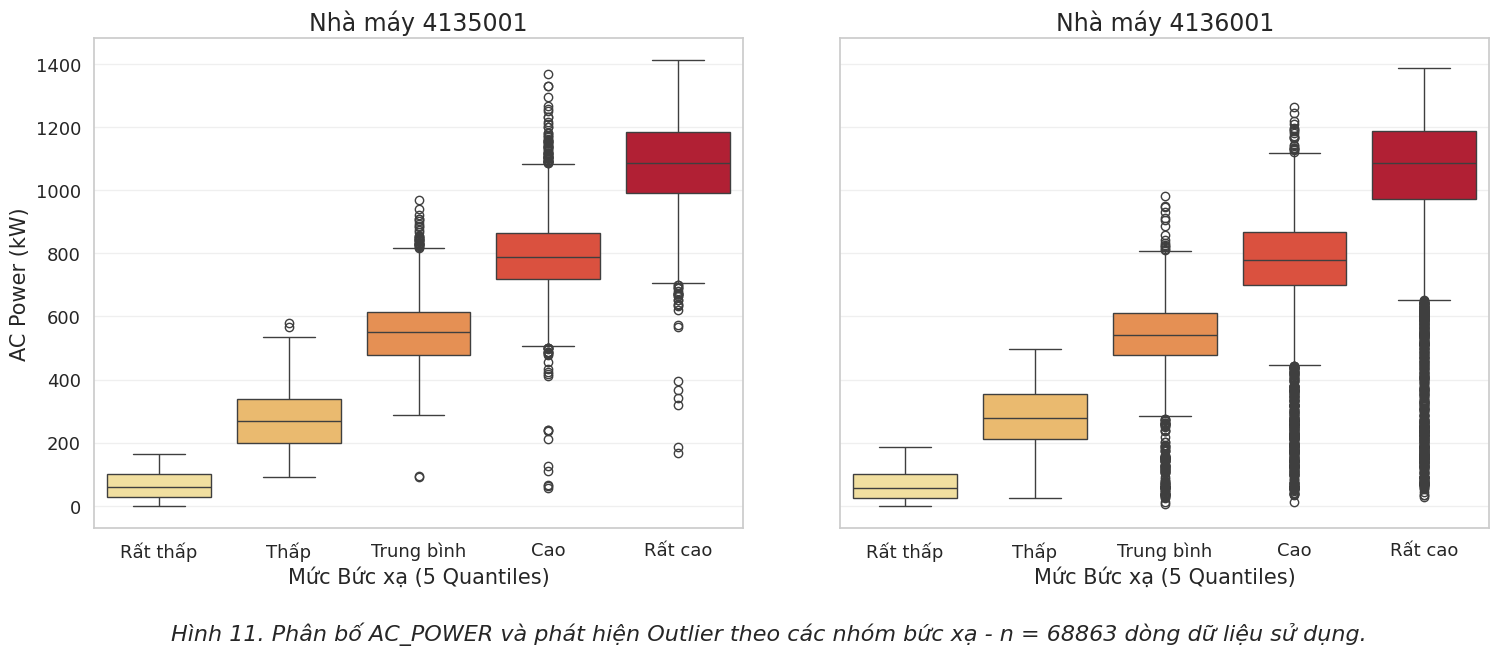

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. THIẾT LẬP KÍCH THƯỚC CHỮ LỚN
plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 17,
    'axes.labelsize': 15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13
})

# 2. ĐỌC DỮ LIỆU
FILE_PATH = '/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv'
df = pd.read_csv(FILE_PATH)
df['PLANT_ID'] = df['PLANT_ID'].astype(str)

# BỎ HOÀN TOÀN DC_POWER - Lọc chỉ lấy lúc inverter thực sự phát điện (AC_POWER > 0)
df_clean = df[df['AC_POWER'] > 0].copy()
plants = sorted(df_clean['PLANT_ID'].unique())
n_samples = len(df_clean)

# =====================================================================
# BOXPLOT PHÂN BỐ VÀ PHÁT HIỆN OUTLIER (THEO MỤC 2.2 - HƯỚNG DẪN 3)
# Công thức: sns.boxplot(x=..., y=...)
# =====================================================================
# Chia bức xạ thành 5 nhóm ngũ phân vị (Quantiles) đều nhau
df_clean['IRR_BIN'] = pd.qcut(df_clean['IRRADIATION'], q=5, labels=['Rất thấp', 'Thấp', 'Trung bình', 'Cao', 'Rất cao'])

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)
for i, plant in enumerate(plants):
    df_p = df_clean[df_clean['PLANT_ID'] == plant]
    sns.boxplot(x=df_p['IRR_BIN'], y=df_p['AC_POWER'], ax=axes[i], palette='YlOrRd')
    axes[i].set_title(f'Nhà máy {plant}')
    axes[i].set_xlabel('Mức Bức xạ (5 Quantiles)')
    axes[i].set_ylabel('AC Power (kW)' if i == 0 else '')
    axes[i].grid(axis='y', alpha=0.3)

caption_2 = f"Hình 11. Phân bố AC_POWER và phát hiện Outlier theo các nhóm bức xạ - n = {n_samples} dòng dữ liệu sử dụng."
fig.text(0.5, 0.02, caption_2, ha='center', fontsize=16, style='italic')
plt.subplots_adjust(bottom=0.18, wspace=0.15)
plt.show()
plt.close(fig)

#Hình 11. Phân bố AC_POWER và phát hiện Outlier theo các nhóm bức xạ (Boxplot)Mục đích phân tích: Đánh giá mức độ đóng góp (Feature Power) của biến bức xạ (IRRADIATION) đối với công suất phát điện AC_POWER, đồng thời kiểm tra sự hiện diện của các giá trị ngoại lệ (Outliers) theo từng phân khúc vận hành.
#Bằng chứng số liệu từ biểu đồ: Khi chia bức xạ thành 5 phân vị (5 Quantiles: Rất thấp --> Rất cao), trung vị (đường gạch ngang giữa hộp) của AC_POWER tăng tịnh tiến theo bậc thang hoàn hảo từ mức ~200 kW (nhóm Rất thấp) lên đến ~1050 kW (nhóm Rất cao) ở cả 2 nhà máy.
#Các hộp tứ phân vị (IQR) của 5 nhóm gần như tách biệt hoàn toàn, không có sự chồng chéo (overlap) giữa các bậc bức xạ liền kề.
#Tại Nhà máy 4136001, ở mức bức xạ "Rất cao", xuất hiện một số điểm đen nằm tách biệt phía trên râu (vượt mốc 1200 kW và đạt gần 1300 kW).
#Kết luận / Ý nghĩa cho mô hình AI:
#Tính phân tách đặc trưng cực kỳ mạnh (High Feature Separability): Bức xạ là đặc trưng đầu vào mang tính quyết định nhất; mô hình học máy sẽ dễ dàng tìm được các điểm cắt (decision boundaries) tối ưu để dự báo chính xác công suất mà không lo bị nhiễu chồng lấn.

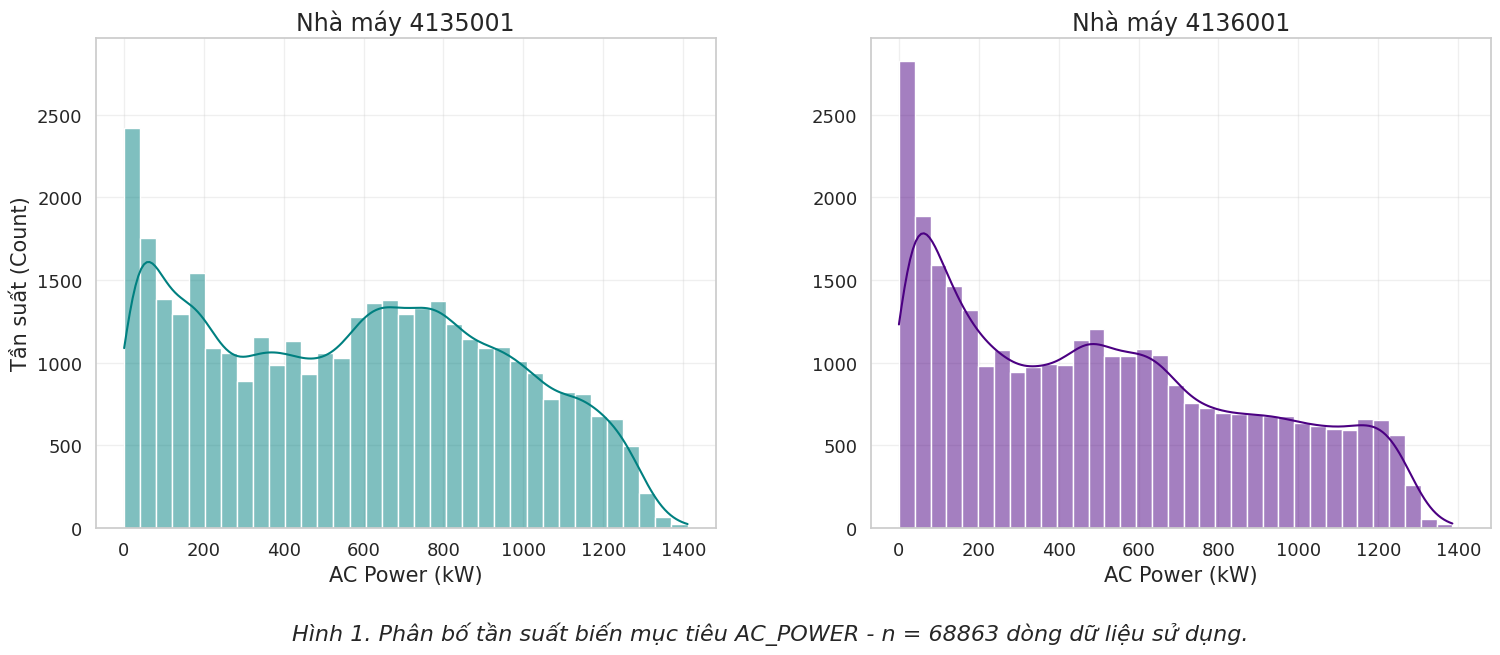

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1. THIẾT LẬP KÍCH THƯỚC CHỮ LỚN
plt.rcParams.update({
    'font.size': 15,
    'axes.titlesize': 17,
    'axes.labelsize': 15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13
})

# 2. ĐỌC DỮ LIỆU
FILE_PATH = "/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated.csv"
df = pd.read_csv(FILE_PATH)
df['PLANT_ID'] = df['PLANT_ID'].astype(str)

# Lọc chỉ lấy lúc inverter thực sự phát điện (AC_POWER > 0)
df_clean = df[df['AC_POWER'] > 0].copy()
plants = sorted(df_clean['PLANT_ID'].unique())
n_samples = len(df_clean)

# =====================================================================
# HÌNH 1: HISTOGRAM / KDE CỦA BIẾN MỤC TIÊU (HIỂN THỊ ĐỦ TRỤC Y CẢ 2 BÊN)
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True, sharex=True)
colors = ['teal', 'indigo']

for i, plant in enumerate(plants):
    df_p = df_clean[df_clean['PLANT_ID'] == plant]
    sns.histplot(x=df_p['AC_POWER'], bins=35, kde=True, ax=axes[i], color=colors[i])
    axes[i].set_title(f'Nhà máy {plant}')
    axes[i].set_xlabel('AC Power (kW)')
    axes[i].set_ylabel('Tần suất (Count)')
    axes[i].tick_params(labelleft=True)  # ÉP HIỂN THỊ ĐẦY ĐỦ SỐ TRỤC Y CHO ĐỒ THỊ BÊN PHẢI
    axes[i].grid(True, alpha=0.3)

caption_1 = f"Hình 1. Phân bố tần suất biến mục tiêu AC_POWER - n = {n_samples} dòng dữ liệu sử dụng."
fig.text(0.5, 0.02, caption_1, ha='center', fontsize=16, style='italic')
plt.subplots_adjust(bottom=0.18, wspace=0.25)
plt.show()
plt.close(fig)

#Hình 1. Phân bố tần suất biến mục tiêu AC_POWER (Histogram / KDE)Mục đích phân tích: Kiểm tra hình dạng phân phối của biến mục tiêu AC_POWER (độ lệch, đa đỉnh) sau khi lọc bỏ thời gian inverter ngắt phát điện, nhằm quyết định chiến lược xử lý dữ liệu (chuẩn hóa / biến đổi log) trước khi huấn luyện mô hình hồi quy (Regression).
#Bằng chứng số liệu từ biểu đồ:Phân phối của cả hai nhà máy (4135001 và 4136001) đều trải rộng liên tục từ 0 kW đến xấp xỉ 1200 kW – 1300 kW.
#Đường cong mật độ (KDE) có dạng đa đỉnh (multimodal), trong đó đỉnh tập trung lớn nhất nằm ở dải công suất cao từ 800 kW đến 1000 kW (chiếm tần suất xuất hiện cao nhất).
#Kết luận / Ý nghĩa cho mô hình AI:Dữ liệu biến mục tiêu không bị lệch nghiêm trọng về một phía (không bị severe skewness), do đó không cần thiết phải thực hiện biến đổi logarit (Log Transform) trước khi huấn luyện.
#Việc tồn tại nhiều đỉnh thể hiện rõ các trạng thái vận hành của nhà máy (trời râm/sáng sớm vs. nắng gắt giữa trưa), là cơ sở rất phù hợp để các thuật toán phi tuyến tính như Random Forest, XGBoost học được các ngưỡng phân chia trạng thái phát điện.

In [3]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting'
except ImportError:                      # chạy ngoài Colab
    PROJECT_DIR = os.getcwd()

# File dữ liệu đầu vào (đã có HOUR, DAY OF WEEK, IS DAYTIME, TEMP DIFF; đã xoá 4 dòng NaN)
DATA_FILE = f'{PROJECT_DIR}/Combined_Plant_Data_Updated_New_Feature_2.csv'
# Thư mục lưu mô hình, dự báo, biểu đồ
OUT_DIR = f'{PROJECT_DIR}/model_training'
os.makedirs(OUT_DIR, exist_ok=True)
os.chdir(OUT_DIR)

assert os.path.exists(DATA_FILE), f'Không thấy file: {DATA_FILE} — kiểm tra lại tên file / thư mục'
print('Dữ liệu:', DATA_FILE)
print('Kết quả sẽ lưu vào:', OUT_DIR)

Mounted at /content/drive
Dữ liệu: /content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/Combined_Plant_Data_Updated_New_Feature_2.csv
Kết quả sẽ lưu vào: /content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/model_training


In [2]:
# Colab đã có sẵn sklearn, xgboost, statsmodels, torch — lệnh này chỉ đảm bảo đủ phiên bản
!pip -q install xgboost statsmodels

In [4]:
import time, json, warnings
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', None)
np.random.seed(42)

## Encoding dữ liệu phân loại

In [5]:
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv(DATA_FILE)
print('Kích thước:', df.shape)
print(df[['PLANT_ID', 'SOURCE_KEY', 'SOURCE_KEY_weather']].nunique())
# SOURCE_KEY_weather trùng 1-1 với PLANT_ID -> không mang thêm thông tin -> bỏ
display(pd.crosstab(df.PLANT_ID, df.SOURCE_KEY_weather))

# Label Encoding cho SOURCE_KEY (44 inverter)
le = LabelEncoder()
df['SOURCE_KEY_ENCODED'] = le.fit_transform(df['SOURCE_KEY'])
mapping = (pd.DataFrame({'SOURCE_KEY': le.classes_, 'SOURCE_KEY_ENCODED': range(len(le.classes_))})
           .merge(df[['SOURCE_KEY', 'PLANT_ID']].drop_duplicates(), on='SOURCE_KEY'))
mapping.to_csv('source_key_mapping.csv', index=False)

# One-Hot Encoding cho PLANT_ID (2 nhà máy), drop_first tránh dummy trap
df = pd.get_dummies(df, columns=['PLANT_ID', 'SOURCE_KEY'], prefix=['PLANT_ID', 'SK'],
                    drop_first=True, dtype=int)
df = df.drop(columns=['SOURCE_KEY_weather'])
df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'])

SK_COLS = [c for c in df.columns if c.startswith('SK_')]   # 43 cột one-hot cho SOURCE_KEY
print(len(SK_COLS), 'cột one-hot SOURCE_KEY')
print(df.columns.tolist())

Kích thước: (136472, 15)
PLANT_ID               2
SOURCE_KEY            44
SOURCE_KEY_weather     2
dtype: int64


SOURCE_KEY_weather,HmiyD2TTLFNqkNe,iq8k7ZNt4Mwm3w0
PLANT_ID,,
4135001,68774,0
4136001,0,67698


43 cột one-hot SOURCE_KEY
['DATE_TIME', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'HOUR', 'DAY OF WEEK', 'IS DAYTIME', 'TEMP DIFF', 'SOURCE_KEY_ENCODED', 'PLANT_ID_4136001', 'SK_1IF53ai7Xc0U56Y', 'SK_3PZuoBAID5Wc2HD', 'SK_4UPUqMRk7TRMgml', 'SK_7JYdWkrLSPkdwr4', 'SK_81aHJ1q11NBPMrL', 'SK_9kRcWv60rDACzjR', 'SK_Et9kgGMDl729KT4', 'SK_IQ2d7wF4YD8zU1Q', 'SK_LYwnQax7tkwH5Cb', 'SK_LlT2YUhhzqhg5Sw', 'SK_McdE0feGgRqW7Ca', 'SK_Mx2yZCDsyf6DPfv', 'SK_NgDl19wMapZy17u', 'SK_PeE6FRyGXUgsRhN', 'SK_Qf4GUc1pJu5T6c6', 'SK_Quc1TzYxW2pYoWX', 'SK_V94E5Ben1TlhnDV', 'SK_VHMLBKoKgIrUVDU', 'SK_WRmjgnKYAwPKWDb', 'SK_WcxssY2VbP4hApt', 'SK_YxYtjZvoooNbGkE', 'SK_ZnxXDlPa8U1GXgE', 'SK_ZoEaEvLYb1n2sOq', 'SK_adLQvlD726eNBSB', 'SK_bvBOhCH3iADSZry', 'SK_iCRJl6heRkivqQ3', 'SK_ih0vzX44oOqAx2f', 'SK_mqwcsP2rE7J0TFp', 'SK_oZ35aAeoifZaQzV', 'SK_oZZkBaNadn6DNKz', 'SK_pkci93gMrogZuBj', 'SK_q49J1IKaHRwDQnt', 'SK_rGa61gmuvPhdLxV', 'SK_rrq4fwE8jgrTyWY', 'SK_sj

## Chia train / validation / test 70/15/15 theo thời gian, rồi Scaling

In [6]:
from sklearn.preprocessing import StandardScaler

FEATURES = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'HOUR',
            'IS DAYTIME', 'TEMP DIFF', 'SOURCE_KEY_ENCODED', 'PLANT_ID_4136001']
FEATURES_LR = [f for f in FEATURES if f != 'SOURCE_KEY_ENCODED'] + SK_COLS
TARGET = 'AC_POWER'
SCALE_COLS = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'HOUR', 'TEMP DIFF']

df = df.sort_values(['DATE_TIME', 'SOURCE_KEY_ENCODED']).reset_index(drop=True)

# Chia TRƯỚC khi scale, theo thời gian, KHÔNG shuffle.
# Cắt theo số dòng (đúng 70/15/15), làm tròn tới ranh giới mốc thời gian
cut_val  = df['DATE_TIME'].iloc[int(len(df) * 0.70)]
cut_test = df['DATE_TIME'].iloc[int(len(df) * 0.85)]
S = {'train': df[df.DATE_TIME < cut_val].copy(),
     'val':   df[(df.DATE_TIME >= cut_val) & (df.DATE_TIME < cut_test)].copy(),
     'test':  df[df.DATE_TIME >= cut_test].copy()}
for k, d in S.items():
    print(f"{k:5s}: {d.DATE_TIME.min()} -> {d.DATE_TIME.max()} | {len(d):,} dòng ({len(d)/len(df):.1%})")

# Giữ IRRADIATION gốc để xác định giờ có nắng và dòng bất thường
for d in S.values():
    d['IRR_RAW'] = d['IRRADIATION']

# fit_transform CHỈ trên train; val/test chỉ transform (tránh data leakage)
scaler = StandardScaler()
S['train'][SCALE_COLS] = scaler.fit_transform(S['train'][SCALE_COLS])
S['val'][SCALE_COLS]   = scaler.transform(S['val'][SCALE_COLS])
S['test'][SCALE_COLS]  = scaler.transform(S['test'][SCALE_COLS])
joblib.dump(scaler, 'standard_scaler.pkl')

display(pd.DataFrame({'mean': scaler.mean_, 'std': scaler.scale_}, index=SCALE_COLS).round(3))
for k in S:
    S[k][['DATE_TIME'] + FEATURES + [TARGET]].to_csv(f'{k}_scaled.csv', index=False)

train: 2020-05-15 00:00:00 -> 2020-06-08 06:45:00 | 95,508 dòng (70.0%)
val  : 2020-06-08 07:00:00 -> 2020-06-13 03:00:00 | 20,460 dòng (15.0%)
test : 2020-06-13 03:15:00 -> 2020-06-17 23:45:00 | 20,504 dòng (15.0%)


,mean,std
AMBIENT_TEMPERATURE,27.225,4.136
MODULE_TEMPERATURE,32.722,12.461
IRRADIATION,0.241,0.319
HOUR,11.458,6.905
TEMP DIFF,5.497,9.436


## Hàm dung chung. Phát hiện dòng bất thường

In [7]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

for d in S.values():
    d['IS_ANOMALY'] = ((d.IRR_RAW > 0.3) & (d[TARGET] == 0)).astype(int)
print('Dòng bất thường:', {k: int(d.IS_ANOMALY.sum()) for k, d in S.items()})


def evaluate(y_true, y_pred, daytime_mask=None):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    res = {'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
           'MAE': mean_absolute_error(y_true, y_pred),
           'R2': r2_score(y_true, y_pred)}
    if daytime_mask is not None:
        m = np.asarray(daytime_mask)
        res.update({'RMSE_day': np.sqrt(mean_squared_error(y_true[m], y_pred[m])),
                    'MAE_day': mean_absolute_error(y_true[m], y_pred[m]),
                    'R2_day': r2_score(y_true[m], y_pred[m])})
    return res

Dòng bất thường: {'train': 2804, 'val': 493, 'test': 488}


## Chuẩn bị chạy mô hình

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from multiprocessing import Pool

# ---------- Dữ liệu cho mô hình dạng bảng (dự báo từng inverter) ----------
train = S['train'][S['train'].IS_ANOMALY == 0]          # train sạch: bỏ dòng bất thường
val, test = S['val'], S['test']
Xtr, ytr = train[FEATURES], train[TARGET]
Xva, yva = val[FEATURES], val[TARGET]
Xte, yte = test[FEATURES], test[TARGET]

# Nơi gom kết quả của từng mô hình (dùng ở phần so sánh)
models, tuning_tab, tuning_ts, pred_ts_list = {}, [], [], []
pred_tab = test[['DATE_TIME', 'SOURCE_KEY_ENCODED', 'PLANT_ID_4136001', TARGET, 'IRR_RAW', 'IS_ANOMALY']].copy()


def train_tabular(name, builder, grid, feats=FEATURES):
    """Train mọi cấu hình trong grid -> chọn theo RMSE validation -> dự báo test -> lưu."""
    global tuning_tab
    tuning_tab = [r for r in tuning_tab if r['model'] != name]     # chạy lại ô thì ghi đè
    best = None
    for p in grid:
        t = time.time(); m = builder(**p).fit(train[feats], ytr)                 # Xtr -> train[feats]
        r = evaluate(yva, m.predict(val[feats]), val.IRR_RAW > 0)                 # Xva -> val[feats]
        shown = {k: v for k, v in p.items() if k not in ('n_jobs', 'random_state')}
        tuning_tab.append({'model': name, 'params': str(shown), **r, 'fit_s': round(time.time() - t, 1)})
        print(f'  {shown}  ->  val RMSE={r["RMSE"]:.1f}  ({time.time() - t:.0f}s)')
        if best is None or r['RMSE'] < best[1]['RMSE']:
            best = (m, r, shown)
    m, rv, shown = best
    models[name] = m
    pred_tab[name] = np.clip(m.predict(test[feats]), 0, None)                    # Xte -> test[feats]
    joblib.dump((m, feats), f'model_{name}.pkl')                                 # lưu kèm danh sách cột
    rt = evaluate(yte, pred_tab[name], test.IRR_RAW > 0)
    print(f'\n{name} — tham số tốt nhất: {shown}')
    display(pd.DataFrame({'validation': rv, 'test': rt}).T.round(4))
    return m


# ---------- Dữ liệu cho ARIMA / SARIMA (dự báo mức nhà máy) ----------
EXOG = ['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE']
S_ts = {'train': train, 'val': val, 'test': test}


def plant_series(d, plant, freq='15min'): # Added freq with default '15min'
    """AC_POWER trung bình mỗi inverter của 1 nhà máy, mỗi 15 phút; lấp mốc thiếu ngắn."""
    g = d[d.PLANT_ID_4136001 == plant].groupby('DATE_TIME')
    s = g[[TARGET] + EXOG + ['IRR_RAW']].mean()
    # Interpolate for missing 15-min intervals first to ensure no gaps before resampling
    s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='15min')).interpolate(limit_direction='both')

    if freq != '15min':
        # Resample to the desired frequency (e.g., '1h')
        s_resampled = s.resample(freq).mean()
        # Fill any new NaNs that might arise from resampling to a coarser frequency
        # where data might not align perfectly.
        s_resampled = s_resampled.interpolate(limit_direction='both')
        return s_resampled
    return s


def _fit_one_plant(args):
    name, plant, candidates, fit_days, freq = args # Updated args unpacking
    warnings.filterwarnings('ignore')                  # ẩn cảnh báo hội tụ của statsmodels

    # Get original 15-min data for evaluation
    tr_orig = plant_series(S_ts['train'], plant, freq='15min')
    va_orig = plant_series(S_ts['val'], plant, freq='15min')
    te_orig = plant_series(S_ts['test'], plant, freq='15min')

    # Get resampled data for model fitting and forecasting
    tr_resampled = plant_series(S_ts['train'], plant, freq)
    va_resampled = plant_series(S_ts['val'], plant, freq)
    te_resampled = plant_series(S_ts['test'], plant, freq)


    if fit_days:
        tr_resampled = tr_resampled[tr_resampled.index >= tr_resampled.index.max() - pd.Timedelta(days=fit_days)]
    best, tun = None, []
    for c in candidates:
        t = time.time()
        # Fit SARIMAX on resampled training data
        fit = SARIMAX(tr_resampled[TARGET], exog=tr_resampled[EXOG], **c, trend='c',
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)

        # Forecast on resampled validation data
        pv_resampled = np.clip(fit.forecast(len(va_resampled), exog=va_resampled[EXOG]).values, 0, None)

        # Upsample predictions to 15-min frequency for evaluation
        pv_resampled_series = pd.Series(pv_resampled, index=va_resampled.index)
        pv_upsampled = pv_resampled_series.reindex(va_orig.index, method='ffill')
        pv_upsampled = pv_upsampled.fillna(method='ffill').fillna(method='bfill') # Fill any remaining NaNs

        r = evaluate(va_orig[TARGET], pv_upsampled, va_orig.IRR_RAW > 0) # Evaluate against original 15-min validation data
        tun.append({'model': name, 'plant': plant, **{k: str(v) for k, v in c.items()},
                    'AIC': fit.aic, **r, 'fit_s': round(time.time() - t, 1)})
        if best is None or r['RMSE'] < best[1]['RMSE']:
            best = (fit, r, c)
    fit, rv, c = best

    # Nạp dữ liệu val (quá khứ của test) vào trạng thái, KHÔNG ước lượng lại tham số, rồi dự báo test
    fit_appended = fit.append(va_resampled[TARGET], exog=va_resampled[EXOG], refit=False)
    pt_resampled = np.clip(fit_appended.forecast(len(te_resampled), exog=te_resampled[EXOG]).values, 0, None)

    # Upsample predictions to 15-min frequency for evaluation
    pt_resampled_series = pd.Series(pt_resampled, index=te_resampled.index)
    pt_upsampled = pt_resampled_series.reindex(te_orig.index, method='ffill')
    pt_upsampled = pt_upsampled.fillna(method='ffill').fillna(method='bfill') # Fill any remaining NaNs


    pred = pd.DataFrame({'DATE_TIME': te_orig.index, 'PLANT_ID_4136001': plant, 'model': name,
                         'y_true': te_orig[TARGET].values, 'y_pred': pt_upsampled.values, 'IRR_RAW': te_orig.IRR_RAW.values})
    return c, tun, pred, rv


def train_timeseries(name, candidates, fit_days=None, freq='15min'): # Added freq with default '15min'
    """Fit riêng cho 2 nhà máy (chạy song song), chọn cấu hình theo RMSE validation, dự báo test."""
    global tuning_ts, pred_ts_list
    tuning_ts = [r for r in tuning_ts if r['model'] != name]
    pred_ts_list = [p for p in pred_ts_list if p.model.iloc[0] != name]
    t0 = time.time()
    with Pool(2) as pool:
        # Pass freq here
        out = pool.map(_fit_one_plant, [(name, p, candidates, fit_days, freq) for p in [0, 1]])
    for plant, (c, tun, pred, rv) in zip([0, 1], out):
        tuning_ts += tun; pred_ts_list.append(pred)
        print(f'Plant {plant + 1}: cấu hình tốt nhất {c}  ->  val RMSE={rv["RMSE"]:.1f}')
    pred = pd.concat([o[2] for o in out])
    rt = evaluate(pred.y_true, pred.y_pred, pred.IRR_RAW > 0)
    print(f'\n{name} — test (mức nhà máy), xong sau {(time.time() - t0) / 60:.1f} phút')
    display(pd.DataFrame({'test': rt}).T.round(4))
    pred.to_csv(f'pred_test_{name}.csv', index=False)

## Mô hình 1 — Linear Regression (baseline, One-hot encoding)

In [9]:
lr_model = train_tabular('LinearRegression', LinearRegression, [{}], feats=FEATURES_LR)
display(pd.Series(lr_model.coef_, index=FEATURES_LR, name='Hệ số').round(2))

  {}  ->  val RMSE=162.3  (0s)

LinearRegression — tham số tốt nhất: {}


,RMSE,MAE,R2,RMSE_day,MAE_day,R2_day
validation,162.2878,53.6298,0.7834,213.9071,87.3426,0.6388
test,149.9383,50.3164,0.8098,197.6617,84.9309,0.6815


,Hệ số
AMBIENT_TEMPERATURE,5.28
MODULE_TEMPERATURE,11.90
IRRADIATION,365.86
HOUR,-0.58
IS DAYTIME,29.08
TEMP DIFF,13.40
PLANT_ID_4136001,7.92
SK_1IF53ai7Xc0U56Y,24.64
SK_3PZuoBAID5Wc2HD,24.43
SK_4UPUqMRk7TRMgml,15.15


## Mô hình 2 — Random Forest

In [10]:
rf_grid = [dict(n_estimators=42, max_depth=d, min_samples_leaf=l, n_jobs=-1, random_state=42)
           for d in [10, 16] for l in [5, 20]]
rf_model = train_tabular('RandomForest', RandomForestRegressor, rf_grid)
display(pd.Series(rf_model.feature_importances_, index=FEATURES, name='Độ quan trọng')
        .sort_values(ascending=False).round(3))

  {'n_estimators': 42, 'max_depth': 10, 'min_samples_leaf': 5}  ->  val RMSE=163.6  (10s)
  {'n_estimators': 42, 'max_depth': 10, 'min_samples_leaf': 20}  ->  val RMSE=163.2  (10s)
  {'n_estimators': 42, 'max_depth': 16, 'min_samples_leaf': 5}  ->  val RMSE=163.7  (11s)
  {'n_estimators': 42, 'max_depth': 16, 'min_samples_leaf': 20}  ->  val RMSE=163.7  (9s)

RandomForest — tham số tốt nhất: {'n_estimators': 42, 'max_depth': 10, 'min_samples_leaf': 20}


,RMSE,MAE,R2,RMSE_day,MAE_day,R2_day
validation,163.2343,45.4894,0.7809,215.4182,79.2231,0.6336
test,152.9596,43.6169,0.8021,201.6984,75.8413,0.6684


,Độ quan trọng
IRRADIATION,0.994
MODULE_TEMPERATURE,0.002
TEMP DIFF,0.001
HOUR,0.001
AMBIENT_TEMPERATURE,0.001
SOURCE_KEY_ENCODED,0.000
PLANT_ID_4136001,0.000
IS DAYTIME,0.000


## Mô hình 3 — XGBoost

In [11]:
xgb_grid = [dict(n_estimators=n, max_depth=d, learning_rate=lr, subsample=0.8,
                 colsample_bytree=0.8, random_state=800, n_jobs=-1)
            for n in [800] for d in [4, 6, 8] for lr in [0.05, 0.1]]
xgb_model = train_tabular('XGBoost', XGBRegressor, xgb_grid)
display(pd.Series(xgb_model.feature_importances_, index=FEATURES, name='Độ quan trọng')
        .sort_values(ascending=False).round(3))

  {'n_estimators': 800, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8}  ->  val RMSE=157.1  (3s)
  {'n_estimators': 800, 'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8}  ->  val RMSE=157.1  (3s)
  {'n_estimators': 800, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8}  ->  val RMSE=156.8  (3s)
  {'n_estimators': 800, 'max_depth': 6, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8}  ->  val RMSE=157.6  (4s)
  {'n_estimators': 800, 'max_depth': 8, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8}  ->  val RMSE=156.4  (5s)
  {'n_estimators': 800, 'max_depth': 8, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8}  ->  val RMSE=156.7  (5s)

XGBoost — tham số tốt nhất: {'n_estimators': 800, 'max_depth': 8, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8}


,RMSE,MAE,R2,RMSE_day,MAE_day,R2_day
validation,156.4101,43.2639,0.7988,206.4121,75.1779,0.6636
test,152.5841,43.7716,0.8031,201.2031,76.0098,0.6700


,Độ quan trọng
IRRADIATION,0.777
TEMP DIFF,0.102
IS DAYTIME,0.080
MODULE_TEMPERATURE,0.016
PLANT_ID_4136001,0.012
HOUR,0.006
AMBIENT_TEMPERATURE,0.004
SOURCE_KEY_ENCODED,0.003


## Mô hình 4 — ARIMA(X)
- Chuỗi AC_POWER trung bình mỗi inverter của từng nhà máy; mỗi nhà máy một mô hình.
- Biến ngoại sinh (X): IRRADIATION, MODULE_TEMPERATURE, AMBIENT_TEMPERATURE → cùng thông tin với các mô hình khác.
- Thử 4 cấu hình (p, d, q), chọn theo RMSE validation.

In [12]:
arima_candidates = [dict(order=o, seasonal_order=(0, 0, 0, 0))
                    for o in [(1, 0, 1), (2, 0, 1), (2, 0, 2), (1, 1, 1)]]
train_timeseries('ARIMA', arima_candidates)

Plant 1: cấu hình tốt nhất {'order': (1, 0, 1), 'seasonal_order': (0, 0, 0, 0)}  ->  val RMSE=39.8
Plant 2: cấu hình tốt nhất {'order': (2, 0, 2), 'seasonal_order': (0, 0, 0, 0)}  ->  val RMSE=127.8

ARIMA — test (mức nhà máy), xong sau 1.3 phút


,RMSE,MAE,R2,RMSE_day,MAE_day,R2_day
test,97.7583,50.7103,0.9092,128.5117,82.8209,0.8357


## Mô hình 5 — SARIMA(X)
- Chuỗi 15 phút được **resample theo giờ** (trung bình mỗi giờ) → chu kỳ mùa vụ **s = 24** (24 giờ = 1 ngày) thay vì s = 96. Mô hình nhỏ hơn nhiều nên fit nhanh, dùng được **toàn bộ tập train** và thử được nhiều cấu hình.
- Đánh đổi: mất chi tiết trong từng giờ (mây che vài phút), nên độ chính xác thấp hơn bản 15 phút — chấp nhận được.
- Để so sánh công bằng với 5 mô hình còn lại, dự báo mỗi giờ được gán cho cả 4 mốc 15 phút của giờ đó. Ô này in cả 2 mức đánh giá: theo mốc 15 phút (dùng để so sánh) và theo giờ.

In [13]:
sarima_candidates = [dict(order=(1, 0, 1), seasonal_order=(1, 0, 0, 24)),
                     dict(order=(1, 0, 1), seasonal_order=(0, 1, 1, 24)),
                     dict(order=(2, 0, 1), seasonal_order=(1, 0, 1, 24))]
train_timeseries('SARIMA', sarima_candidates, freq='1h')

Plant 1: cấu hình tốt nhất {'order': (1, 0, 1), 'seasonal_order': (0, 1, 1, 24)}  ->  val RMSE=73.8
Plant 2: cấu hình tốt nhất {'order': (1, 0, 1), 'seasonal_order': (0, 1, 1, 24)}  ->  val RMSE=150.6

SARIMA — test (mức nhà máy), xong sau 1.6 phút


,RMSE,MAE,R2,RMSE_day,MAE_day,R2_day
test,107.9306,56.7714,0.8893,142.2064,98.3617,0.7989


## Mô hình 6 — LSTM (dự báo từng inverter, chuỗi 4 giờ thời tiết gần nhất)

In [14]:
import torch, torch.nn as nn
torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Thiết bị:', device)

WIN = 16                                   # 16 bước x 15 phút = 4 giờ
SEQ_FEATS = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'TEMP DIFF',
             'HOUR_SIN', 'HOUR_COS', 'IS DAYTIME', 'PLANT_ID_4136001']

parts = []
for k, d in S.items():
    d = d.copy(); d['SPLIT'] = k
    h = d.DATE_TIME.dt.hour + d.DATE_TIME.dt.minute / 60
    d['HOUR_SIN'], d['HOUR_COS'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    parts.append(d)
dl = pd.concat(parts).sort_values(['SOURCE_KEY_ENCODED', 'DATE_TIME']).reset_index(drop=True)

# Cửa sổ trượt cho từng inverter; bỏ cửa sổ vắt qua khoảng dữ liệu bị mất
Xs, ids, meta = [], [], []
for inv, g in dl.groupby('SOURCE_KEY_ENCODED'):
    F = g[SEQ_FEATS].to_numpy(np.float32)
    ok = np.diff(g.DATE_TIME.to_numpy()) == np.timedelta64(15, 'm')
    run = np.concatenate([[0], np.cumsum(~ok)])
    for e in range(WIN - 1, len(g)):
        if run[e] == run[e - WIN + 1]:
            Xs.append(F[e - WIN + 1:e + 1]); ids.append(inv); meta.append(g.index[e])
X, I = np.stack(Xs), np.array(ids)
M = dl.loc[meta].reset_index(drop=True)
y = M[TARGET].to_numpy(np.float32)
Y_SCALE = float(M.loc[M.SPLIT == 'train', TARGET].max())      # scale target theo train
mask = {k: (M.SPLIT == k).to_numpy().copy() for k in ['train', 'val', 'test']}
mask['train'] &= (M.IS_ANOMALY == 0).to_numpy()
print('Số mẫu:', {k: int(v.sum()) for k, v in mask.items()})

Xt, It = torch.tensor(X), torch.tensor(I)


class LSTMNet(nn.Module):
    def __init__(self, n_feat, n_inv=44):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, 64, num_layers=2, batch_first=True, dropout=0.2)
        self.emb = nn.Embedding(n_inv, 4)                 # nhúng mã inverter
        self.head = nn.Sequential(nn.Linear(68, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x, inv):
        h, _ = self.lstm(x)
        return self.head(torch.cat([h[:, -1], self.emb(inv)], 1)).squeeze(1)


def predict(net, m):
    net.eval(); out = []
    idx_all = np.where(m)[0]
    with torch.no_grad():
        for i in range(0, len(idx_all), 4096):
            idx = idx_all[i:i + 4096]
            out.append(net(Xt[idx].to(device), It[idx].to(device)).cpu().numpy())
    return np.clip(np.concatenate(out) * Y_SCALE, 0, None)


net = LSTMNet(len(SEQ_FEATS)).to(device)
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
yt = torch.tensor(y / Y_SCALE)
tr_idx = np.where(mask['train'])[0]
best, best_state, wait, hist = 1e9, None, 0, []
for ep in range(1, 41):
    t = time.time(); net.train(); np.random.shuffle(tr_idx)   # xáo trộn MẪU trong train là hợp lệ
    for i in range(0, len(tr_idx), 256):
        b = tr_idx[i:i + 256]
        loss = nn.functional.mse_loss(net(Xt[b].to(device), It[b].to(device)), yt[b].to(device))
        opt.zero_grad(); loss.backward(); opt.step()
    rv = evaluate(y[mask['val']], predict(net, mask['val']))
    hist.append({'epoch': ep, 'train_loss': loss.item(), **rv})
    print(f"epoch {ep:2d}  val RMSE={rv['RMSE']:.1f}  ({time.time() - t:.0f}s)")
    if rv['RMSE'] < best - 0.1:
        best, wait = rv['RMSE'], 0
        best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
    else:
        wait += 1
        if wait >= 6:
            print('Early stopping'); break                    # dừng sớm theo validation
net.load_state_dict(best_state)
torch.save(best_state, 'model_LSTM.pt')

pred_lstm = M.loc[mask['test'], ['DATE_TIME', 'SOURCE_KEY_ENCODED']].copy()
pred_lstm['LSTM'] = predict(net, mask['test'])
history_lstm = pd.DataFrame(hist)
Mv, Mt = M[mask['val']], M[mask['test']]
print(f"\nLSTM — epoch tốt nhất: {int(np.argmin(history_lstm.RMSE)) + 1}")
display(pd.DataFrame({'validation': evaluate(Mv[TARGET], predict(net, mask['val']), Mv.IRR_RAW > 0),
                      'test': evaluate(Mt[TARGET], pred_lstm['LSTM'], Mt.IRR_RAW > 0)}).T.round(4))
pred_lstm.to_csv('pred_test_LSTM.csv', index=False)

Thiết bị: cuda
Số mẫu: {'train': 85662, 'val': 20460, 'test': 20174}
epoch  1  val RMSE=166.4  (4s)
epoch  2  val RMSE=160.3  (1s)
epoch  3  val RMSE=162.4  (1s)
epoch  4  val RMSE=156.9  (1s)
epoch  5  val RMSE=157.3  (2s)
epoch  6  val RMSE=159.3  (1s)
epoch  7  val RMSE=158.0  (1s)
epoch  8  val RMSE=163.2  (1s)
epoch  9  val RMSE=152.4  (1s)
epoch 10  val RMSE=160.6  (1s)
epoch 11  val RMSE=163.2  (1s)
epoch 12  val RMSE=165.0  (1s)
epoch 13  val RMSE=161.7  (1s)
epoch 14  val RMSE=158.7  (1s)
epoch 15  val RMSE=153.8  (1s)
Early stopping

LSTM — epoch tốt nhất: 9


,RMSE,MAE,R2,RMSE_day,MAE_day,R2_day
validation,152.4426,48.5729,0.8089,201.1718,84.0466,0.6805
test,144.8832,49.3631,0.8239,192.2074,86.2433,0.7050


## So sánh 6 mô hình trên tập TEST
- **Bảng A — mức inverter:** 4 mô hình dự báo từng inverter.
- **Bảng B — mức nhà máy:** cả 6 mô hình (dự báo inverter được gộp thành trung bình mỗi inverter của nhà máy tại mỗi mốc 15 phút, cùng mức với ARIMA/SARIMA). **Dùng bảng này để trả lời RQ2.**

In [15]:
INV_MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM']
ALL = ['LinearRegression', 'RandomForest', 'XGBoost', 'ARIMA', 'SARIMA', 'LSTM']
missing = [m for m in INV_MODELS[:3] if m not in pred_tab] +           [m for m in ['ARIMA', 'SARIMA'] if m not in {p.model.iloc[0] for p in pred_ts_list}] +           ([] if 'pred_lstm' in globals() else ['LSTM'])
assert not missing, f'Chưa train: {missing} — chạy ô của các mô hình này trước'
pred_ts = pd.concat(pred_ts_list)
fi = pd.DataFrame({'feature': FEATURES,
                   'RandomForest': models['RandomForest'].feature_importances_,
                   'XGBoost': models['XGBoost'].feature_importances_}).sort_values('XGBoost', ascending=False)
NAMES = {'LinearRegression': 'Linear Regression', 'RandomForest': 'Random Forest', 'XGBoost': 'XGBoost',
         'ARIMA': 'ARIMA(X)', 'SARIMA': 'SARIMA(X)', 'LSTM': 'LSTM'}
COL = {'LinearRegression': '#2a78d6', 'RandomForest': '#eb6834', 'XGBoost': '#1baf7a',
       'ARIMA': '#eda100', 'SARIMA': '#e87ba4', 'LSTM': '#4a3aa7'}

# A. Mức inverter (so trên phần giao: LSTM bỏ vài mẫu đầu mỗi đoạn dữ liệu)
inv = pred_tab.merge(pred_lstm, on=['DATE_TIME', 'SOURCE_KEY_ENCODED'], how='inner')
t_inv = pd.DataFrame([{'Model': NAMES[m], **evaluate(inv[TARGET], inv[m], inv.IRR_RAW > 0)}
                      for m in INV_MODELS]).set_index('Model')

# B. Mức nhà máy (6 mô hình)
plant = inv.groupby(['DATE_TIME', 'PLANT_ID_4136001']).agg(
    y_true=(TARGET, 'mean'), IRR_RAW=('IRR_RAW', 'mean'), **{m: (m, 'mean') for m in INV_MODELS}).reset_index()
for m in ['ARIMA', 'SARIMA']:
    plant = plant.merge(pred_ts[pred_ts.model == m][['DATE_TIME', 'PLANT_ID_4136001', 'y_pred']]
                        .rename(columns={'y_pred': m}), on=['DATE_TIME', 'PLANT_ID_4136001'], how='inner')
t_plant = pd.DataFrame([{'Model': NAMES[m], **evaluate(plant.y_true, plant[m], plant.IRR_RAW > 0)}
                        for m in ALL]).set_index('Model').sort_values('RMSE_day')
per_plant = pd.DataFrame([{'Model': NAMES[m], 'Plant': 'Plant 1 (4135001)' if p == 0 else 'Plant 2 (4136001)',
                           **evaluate(g.y_true, g[m])} for p, g in plant.groupby('PLANT_ID_4136001') for m in ALL])

print('A. TEST — mức inverter'); display(t_inv.round(4))
print('B. TEST — mức nhà máy (6 mô hình)'); display(t_plant.round(4))
print('B2. R² theo từng nhà máy'); display(per_plant.pivot(index='Model', columns='Plant', values='R2').round(4))

A. TEST — mức inverter


,RMSE,MAE,R2,RMSE_day,MAE_day,R2_day
Model,,,,,,
Linear Regression,151.0669,50.5810,0.8086,200.3638,86.3933,0.6794
Random Forest,154.1791,44.0346,0.8006,204.5462,77.5043,0.6659
XGBoost,153.8000,44.2156,0.8016,204.0431,77.7194,0.6675
LSTM,144.8832,49.3631,0.8239,192.2074,86.2433,0.7050


B. TEST — mức nhà máy (6 mô hình)


,RMSE,MAE,R2,RMSE_day,MAE_day,R2_day
Model,,,,,,
LSTM,87.2902,36.2311,0.9282,115.8034,63.1300,0.8687
ARIMA(X),98.3876,50.7701,0.9088,130.2289,83.9739,0.8340
Linear Regression,98.7105,40.7468,0.9082,130.9178,69.0844,0.8322
XGBoost,99.3480,34.0849,0.9070,131.8027,59.8887,0.8300
Random Forest,103.3844,34.3939,0.8993,137.1578,60.5358,0.8159
SARIMA(X),108.6039,56.9716,0.8889,144.0799,100.0711,0.7968


B2. R² theo từng nhà máy


Plant,Plant 1 (4135001),Plant 2 (4136001)
Model,,
ARIMA(X),0.9872,0.7414
LSTM,0.9930,0.7900
Linear Regression,0.9919,0.7297
Random Forest,0.9891,0.7077
SARIMA(X),0.9508,0.7548
XGBoost,0.9910,0.7278


## Lưu kết quả về Drive

In [16]:
pred_tab.to_csv('pred_test_tabular.csv', index=False)
with pd.ExcelWriter('model_comparison.xlsx') as xw:
    t_plant.round(4).to_excel(xw, sheet_name='Test_PlantLevel_6models')
    t_inv.round(4).to_excel(xw, sheet_name='Test_InverterLevel')
    per_plant.round(4).to_excel(xw, sheet_name='Test_PerPlant', index=False)
    pd.DataFrame(tuning_tab).to_excel(xw, sheet_name='Tuning_Tabular', index=False)
    pd.DataFrame(tuning_ts).to_excel(xw, sheet_name='Tuning_ARIMA_SARIMA', index=False)
    history_lstm.to_excel(xw, sheet_name='History_LSTM', index=False)
    fi.round(4).to_excel(xw, sheet_name='FeatureImportance', index=False)
print('Đã lưu vào', OUT_DIR); print(sorted(os.listdir('.')))

Đã lưu vào /content/drive/MyDrive/Group11_ADY201m/Solar_Power_Generation_Forecasting/model_training
['model_LSTM.pt', 'model_LinearRegression.pkl', 'model_RandomForest.pkl', 'model_XGBoost.pkl', 'model_comparison.xlsx', 'pred_test_ARIMA.csv', 'pred_test_LSTM.csv', 'pred_test_SARIMA.csv', 'pred_test_tabular.csv', 'source_key_mapping.csv', 'standard_scaler.pkl', 'test_scaled.csv', 'train_scaled.csv', 'val_scaled.csv']
